## Artifact Loading

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from google.colab import drive
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Load the artifact
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

print("Full Tensors Loaded:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)

# 3. Slice for B1 Baseline (First 14 sensor features only)
X_train_b1 = X_train[:, :, :14]
X_val_b1   = X_val[:, :, :14]
X_test_b1  = X_test[:, :, :14]

print("\nB1 Tensors (14 Sensors):")
print("X_train_b1 shape:", X_train_b1.shape)
print("X_val_b1 shape:  ", X_val_b1.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Full Tensors Loaded:
X_train: (43696, 30, 15) | y_train: (43696,)
X_val:   (10332, 30, 15) | y_val:   (10332,)
X_test:  (248, 30, 15) | y_test:  (248,)

B1 Tensors (14 Sensors):
X_train_b1 shape: (43696, 30, 14)
X_val_b1 shape:   (10332, 30, 14)


###**Step 5:**  B1: Basic LSTM

## **Baseline B1:** Sensor-Only Standard LSTM (Deterministic Benchmark)
#### **Scope:** Validation evaluation only (Test set frozen & untouched)

#### **Section 1:**  Environment & Determinism Setup

In [3]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- Strict Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

#### **Section 2:**  Load Processed Tensors & Slice B1 Features

In [4]:
# Load data exported from 01_FD004_Research_Baseline.ipynb
data = np.load("/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz")

# Explicitly isolate the 14 standardized continuous sensors (exclude regime index at col 14)
X_train_b1 = data["X_train"][:, :, :14]
y_train_b1 = data["y_train"]

X_val_b1   = data["X_val"][:, :, :14]
y_val_b1   = data["y_val"]

# NOTE: Test set is deliberately omitted/unloaded to enforce isolation.
print(f"X_train_b1 shape : {X_train_b1.shape} | y_train_b1 : {y_train_b1.shape}")
print(f"X_val_b1 shape   : {X_val_b1.shape}   | y_val_b1   : {y_val_b1.shape}")

X_train_b1 shape : (43696, 30, 14) | y_train_b1 : (43696,)
X_val_b1 shape   : (10332, 30, 14)   | y_val_b1   : (10332,)


#### **Section 3:** — NASA Asymmetric Scoring Metric Definition

In [5]:
def compute_nasa_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """
    Computes the official asymmetric C-MAPSS NASA score function:
      d_i = y_pred_i - y_true_i
      S = sum(exp(-d_i / 13) - 1) for d_i < 0 (early prediction)
        + sum(exp( d_i / 10) - 1) for d_i >= 0 (late prediction, penalized heavier)
    """
    errors = y_pred - y_true
    score = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )
    return float(np.sum(score))

#### **Section 4:** Build & Compile Baseline B1 Architecture

In [6]:
model_b1 = Sequential([
    LSTM(64, input_shape=(30, 14)),
    Dense(32, activation='relu'),
    Dense(1)
], name="B1_Vanilla_LSTM")

model_b1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

model_b1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "B1_Vanilla_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

#### **Section 5:** Model Training (Training Engines Only)


In [7]:
os.makedirs("./models", exist_ok=True)
checkpoint_path = "./models/b1_lstm_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=0
    )
]

history = model_b1.fit(
    X_train_b1,
    y_train_b1,
    validation_data=(X_val_b1, y_val_b1),
    epochs=50,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 2739.1487 - mae: 44.2559 - val_loss: 1736.4637 - val_mae: 36.6019
Epoch 2/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 1566.4015 - mae: 34.6673 - val_loss: 787.0826 - val_mae: 22.5060
Epoch 3/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 627.7616 - mae: 19.2474 - val_loss: 628.3700 - val_mae: 19.0382
Epoch 4/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 522.6083 - mae: 17.1653 - val_loss: 592.2604 - val_mae: 18.1122
Epoch 5/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 472.3531 - mae: 16.1178 - val_loss: 569.2260 - val_mae: 18.0555
Epoch 6/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 441.9816 - mae: 15.4768 - val_loss: 591.4412 - val_mae: 18.3911
Epoch 7/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 415.9168 - mae: 14.9578 - val_loss: 645.4004 - val_mae: 18.7246
Epoch 8/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 389.0398 - mae: 14.3823 - val_loss: 615.9930 - val_mae: 18.1624
E

#### **Section 6:**  Validation Evaluation

In [8]:
# Predict strictly on validation split
y_val_pred = model_b1.predict(X_val_b1, verbose=0).flatten()

# Calculate validation metrics
val_rmse = np.sqrt(mean_squared_error(y_val_b1, y_val_pred))
val_mae  = mean_absolute_error(y_val_b1, y_val_pred)
val_nasa = compute_nasa_score(y_val_b1, y_val_pred)

print("\n" + "="*45)
print("     BASELINE B1 VALIDATION PERFORMANCE     ")
print("="*45)
print(f"Validation RMSE : {val_rmse:.4f}")
print(f"Validation MAE  : {val_mae:.4f}")
print(f"Validation NASA : {val_nasa:,.2f}")
print("="*45)


     BASELINE B1 VALIDATION PERFORMANCE     
Validation RMSE : 23.8585
Validation MAE  : 18.0555
Validation NASA : 279,328.84


Detected 49 validation engines from y_val.


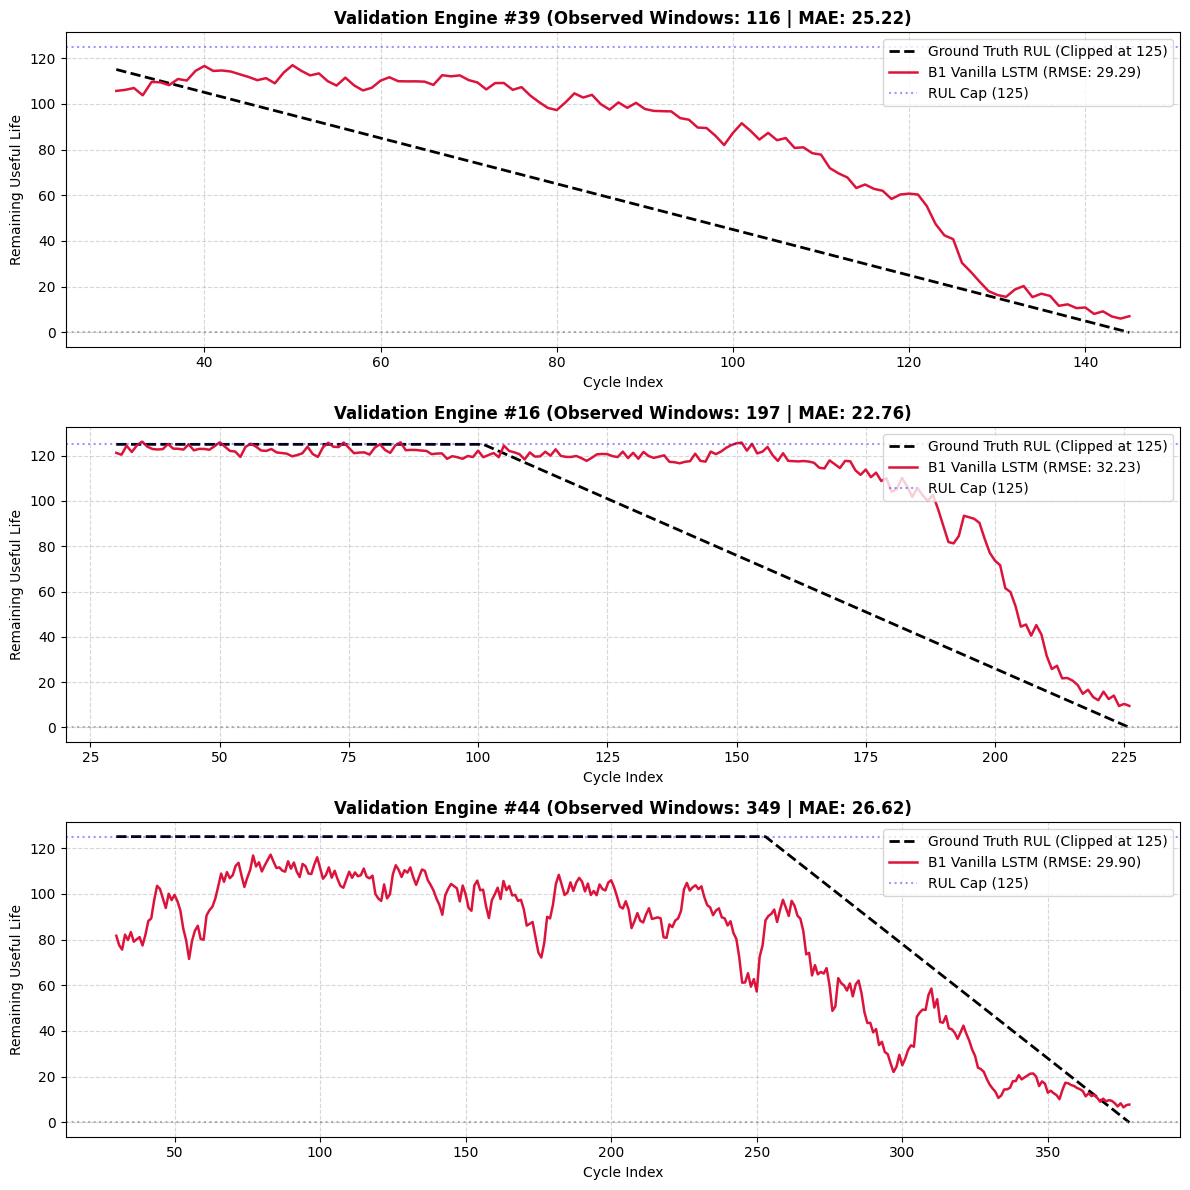

In [9]:
# ==============================================================================
# Validation Engine Trajectory Inspection (Directly from .npz Tensors)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Ensure tensors are loaded
# data = np.load(DATA_PATH)
# X_val_b1 = data["X_val"][:, :, :14]
# y_val_b1 = data["y_val"]

# 2. Predict on entire validation set
y_val_pred = model_b1.predict(X_val_b1, verbose=0).flatten()

# 3. Identify engine boundaries in y_val
# An engine ends when the next RUL jumps up (e.g. from ~0 back up to 125)
engine_starts = [0]
for i in range(1, len(y_val_b1)):
    if y_val_b1[i] > y_val_b1[i-1]:
        engine_starts.append(i)
engine_starts.append(len(y_val_b1))

# 4. Extract individual engine segments
val_engines = []
for i in range(len(engine_starts) - 1):
    start = engine_starts[i]
    end = engine_starts[i+1]
    val_engines.append({
        "engine_idx": i + 1,
        "y_true": y_val_b1[start:end],
        "y_pred": y_val_pred[start:end],
        "length": end - start
    })

print(f"Detected {len(val_engines)} validation engines from y_val.")

# 5. Select 3 engines: Shortest, Median, and Longest
sorted_engines = sorted(val_engines, key=lambda x: x["length"])
selected = [
    sorted_engines[2],                          # Short
    sorted_engines[len(sorted_engines) // 2],   # Median
    sorted_engines[-3]                          # Long
]

# 6. Plot Trajectories
fig, axes = plt.subplots(len(selected), 1, figsize=(12, 4 * len(selected)), sharex=False)
if len(selected) == 1:
    axes = [axes]

for ax, eng in zip(axes, selected):
    cycles = np.arange(30, 30 + eng["length"])  # Starts after window_size (30)
    y_t = eng["y_true"]
    y_p = eng["y_pred"]

    eng_rmse = np.sqrt(mean_squared_error(y_t, y_p))
    eng_mae = mean_absolute_error(y_t, y_p)

    ax.plot(cycles, y_t, label="Ground Truth RUL (Clipped at 125)", color="black", linewidth=2, linestyle="--")
    ax.plot(cycles, y_p, label=f"B1 Vanilla LSTM (RMSE: {eng_rmse:.2f})", color="crimson", linewidth=1.8)

    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.axhline(125, color="blue", linestyle=":", alpha=0.4, label="RUL Cap (125)")
    ax.set_title(f"Validation Engine #{eng['engine_idx']} (Observed Windows: {eng['length']} | MAE: {eng_mae:.2f})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Cycle Index", fontsize=10)
    ax.set_ylabel("Remaining Useful Life", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

=============================================================================
## Baseline B2: Regime-Concatenated LSTM (30 x 15 Input)
=============================================================================

In [10]:

# 1. Prepare Full 15-Feature Tensors (14 Sensors + 1 Regime Feature)
X_train_b2 = data["X_train"][:, :, :15]
y_train_b2 = data["y_train"]

X_val_b2   = data["X_val"][:, :, :15]
y_val_b2   = data["y_val"]

# 2. Build B2 Architecture (Identical to B1 except input_shape)
model_b2 = Sequential([
    LSTM(64, input_shape=(30, 15)),
    Dense(32, activation='relu'),
    Dense(1)
], name="B2_Regime_Concatenated_LSTM")

model_b2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

# 3. Train with identical EarlyStopping patience
callbacks_b2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]

history_b2 = model_b2.fit(
    X_train_b2,
    y_train_b2,
    validation_data=(X_val_b2, y_val_b2),
    epochs=50,
    batch_size=64,
    callbacks=callbacks_b2,
    verbose=1
)

# 4. Evaluate Validation Performance
y_val_pred_b2 = model_b2.predict(X_val_b2, verbose=0).flatten()

val_rmse_b2 = np.sqrt(mean_squared_error(y_val_b2, y_val_pred_b2))
val_mae_b2  = mean_absolute_error(y_val_b2, y_val_pred_b2)
val_nasa_b2 = compute_nasa_score(y_val_b2, y_val_pred_b2)

print("\n" + "="*50)
print("     BASELINE B2 (REGIME-CONCAT) VALIDATION PERFORMANCE     ")
print("="*50)
print(f"Validation RMSE : {val_rmse_b2:.4f} (B1: 22.5081)")
print(f"Validation MAE  : {val_mae_b2:.4f} (B1: 16.5747)")
print(f"Validation NASA : {val_nasa_b2:,.2f} (B1: 170,193.72)")
print("="*50)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 2627.7485 - mae: 43.4821 - val_loss: 1736.2551 - val_mae: 36.5879
Epoch 2/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 1583.6271 - mae: 34.8956 - val_loss: 867.4463 - val_mae: 23.6233
Epoch 3/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 555.0993 - mae: 17.9023 - val_loss: 635.2564 - val_mae: 19.2378
Epoch 4/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 440.1429 - mae: 15.4891 - val_loss: 550.6583 - val_mae: 17.8257
Epoch 5/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 396.1454 - mae: 14.5262 - val_loss: 522.5153 - val_mae: 17.1552
Epoch 6/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 362.9577 - mae: 13.7893 - val_loss: 575.1664 - val_mae: 17.4338
Epoch 7/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 335.3215 - mae: 13.1349 - val_loss: 588.6310 - val_mae: 17.1563
Epoch 8/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 310.2019 - mae: 12.5601 - val_loss: 544.2333 - val_mae: 16.4321
Epoch

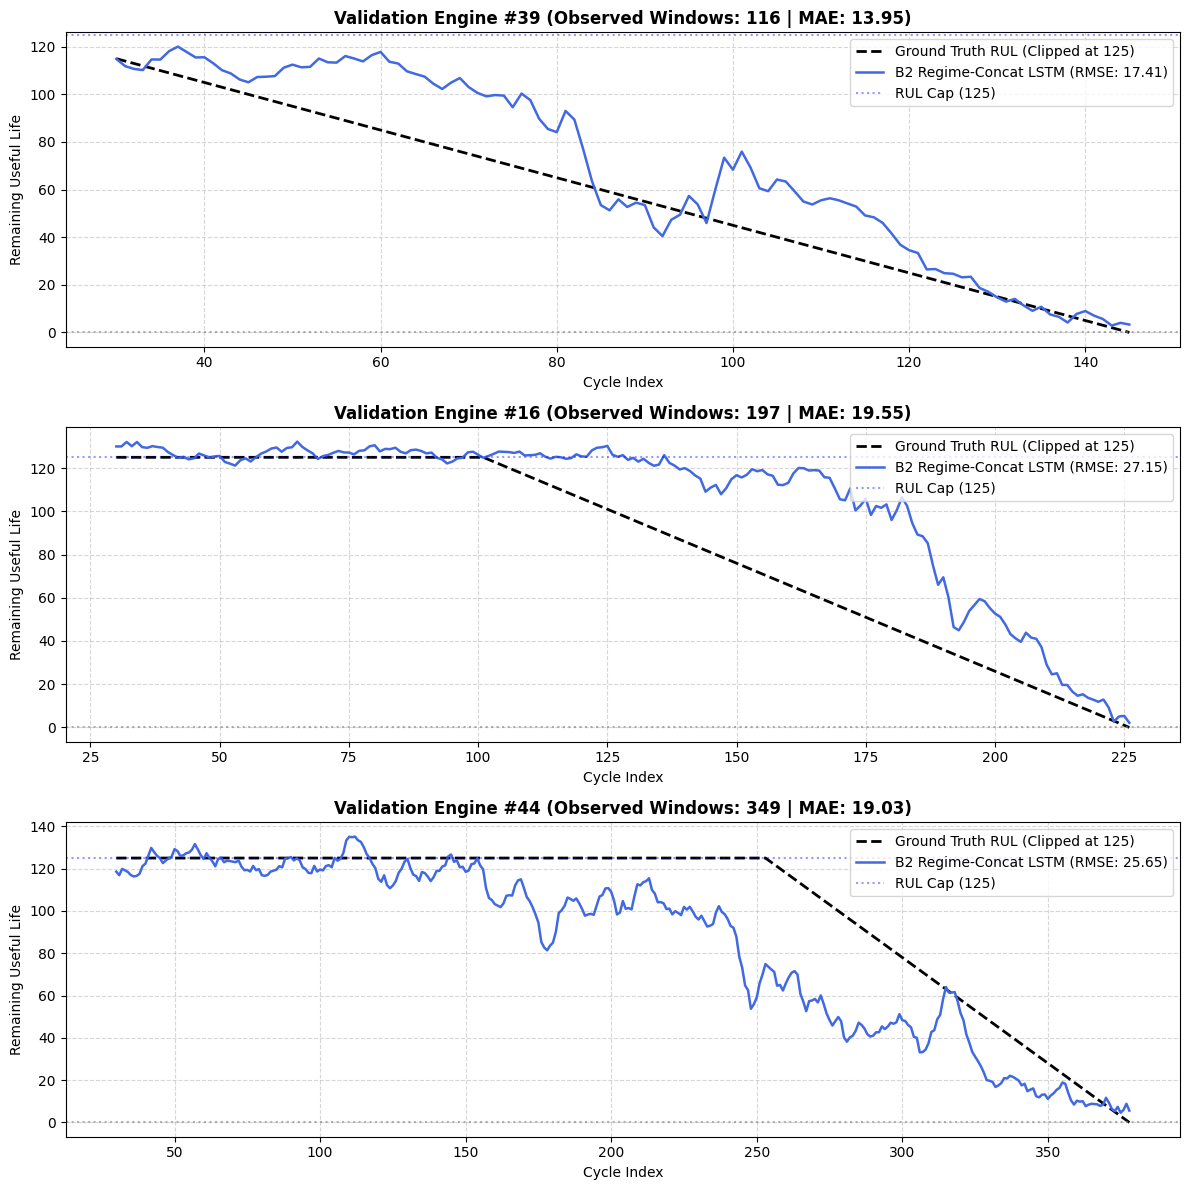

In [11]:
# ==============================================================================
# Baseline B2 Trajectory Inspection (Predicted vs. True RUL)
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Predict on entire validation set using B2 (30 x 15 input)
y_val_pred_b2 = model_b2.predict(X_val_b2, verbose=0).flatten()

# 2. Identify engine boundaries in y_val
engine_starts = [0]
for i in range(1, len(y_val_b2)):
    if y_val_b2[i] > y_val_b2[i - 1]:
        engine_starts.append(i)
engine_starts.append(len(y_val_b2))

# 3. Extract individual engine segments
val_engines_b2 = []
for i in range(len(engine_starts) - 1):
    start = engine_starts[i]
    end = engine_starts[i + 1]
    val_engines_b2.append(
        {
            "engine_idx": i + 1,
            "y_true": y_val_b2[start:end],
            "y_pred": y_val_pred_b2[start:end],
            "length": end - start,
        }
    )

# 4. Select the exact same 3 engines (Short, Median, Long)
sorted_engines_b2 = sorted(val_engines_b2, key=lambda x: x["length"])
selected_b2 = [
    sorted_engines_b2[2],  # Short lifetime
    sorted_engines_b2[len(sorted_engines_b2) // 2],  # Median lifetime
    sorted_engines_b2[-3],  # Long lifetime
]

# 5. Plot Trajectories for B2
fig, axes = plt.subplots(
    len(selected_b2), 1, figsize=(12, 4 * len(selected_b2)), sharex=False
)
if len(selected_b2) == 1:
    axes = [axes]

for ax, eng in zip(axes, selected_b2):
    cycles = np.arange(30, 30 + eng["length"])
    y_t = eng["y_true"]
    y_p = eng["y_pred"]

    eng_rmse = np.sqrt(mean_squared_error(y_t, y_p))
    eng_mae = mean_absolute_error(y_t, y_p)

    ax.plot(
        cycles,
        y_t,
        label="Ground Truth RUL (Clipped at 125)",
        color="black",
        linewidth=2,
        linestyle="--",
    )
    ax.plot(
        cycles,
        y_p,
        label=f"B2 Regime-Concat LSTM (RMSE: {eng_rmse:.2f})",
        color="royalblue",
        linewidth=1.8,
    )

    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.axhline(125, color="blue", linestyle=":", alpha=0.4, label="RUL Cap (125)")
    ax.set_title(
        f"Validation Engine #{eng['engine_idx']} (Observed Windows: {eng['length']} | MAE: {eng_mae:.2f})",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Cycle Index", fontsize=10)
    ax.set_ylabel("Remaining Useful Life", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [12]:
# ==============================================================================
# Save Baseline B2 Model to Google Drive
# ==============================================================================

import os
from google.colab import drive

# 1. Mount Google Drive (if not already mounted)
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# 2. Define storage directory & file path
SAVE_DIR = "/content/drive/MyDrive/FD004_Research/models"
os.makedirs(SAVE_DIR, exist_ok=True)
MODEL_B2_PATH = os.path.join(SAVE_DIR, "b2_lstm_regime_best.keras")

# 3. Save the trained B2 model
model_b2.save(MODEL_B2_PATH)
print(f"B2 Model successfully saved to: {MODEL_B2_PATH}")


B2 Model successfully saved to: /content/drive/MyDrive/FD004_Research/models/b2_lstm_regime_best.keras


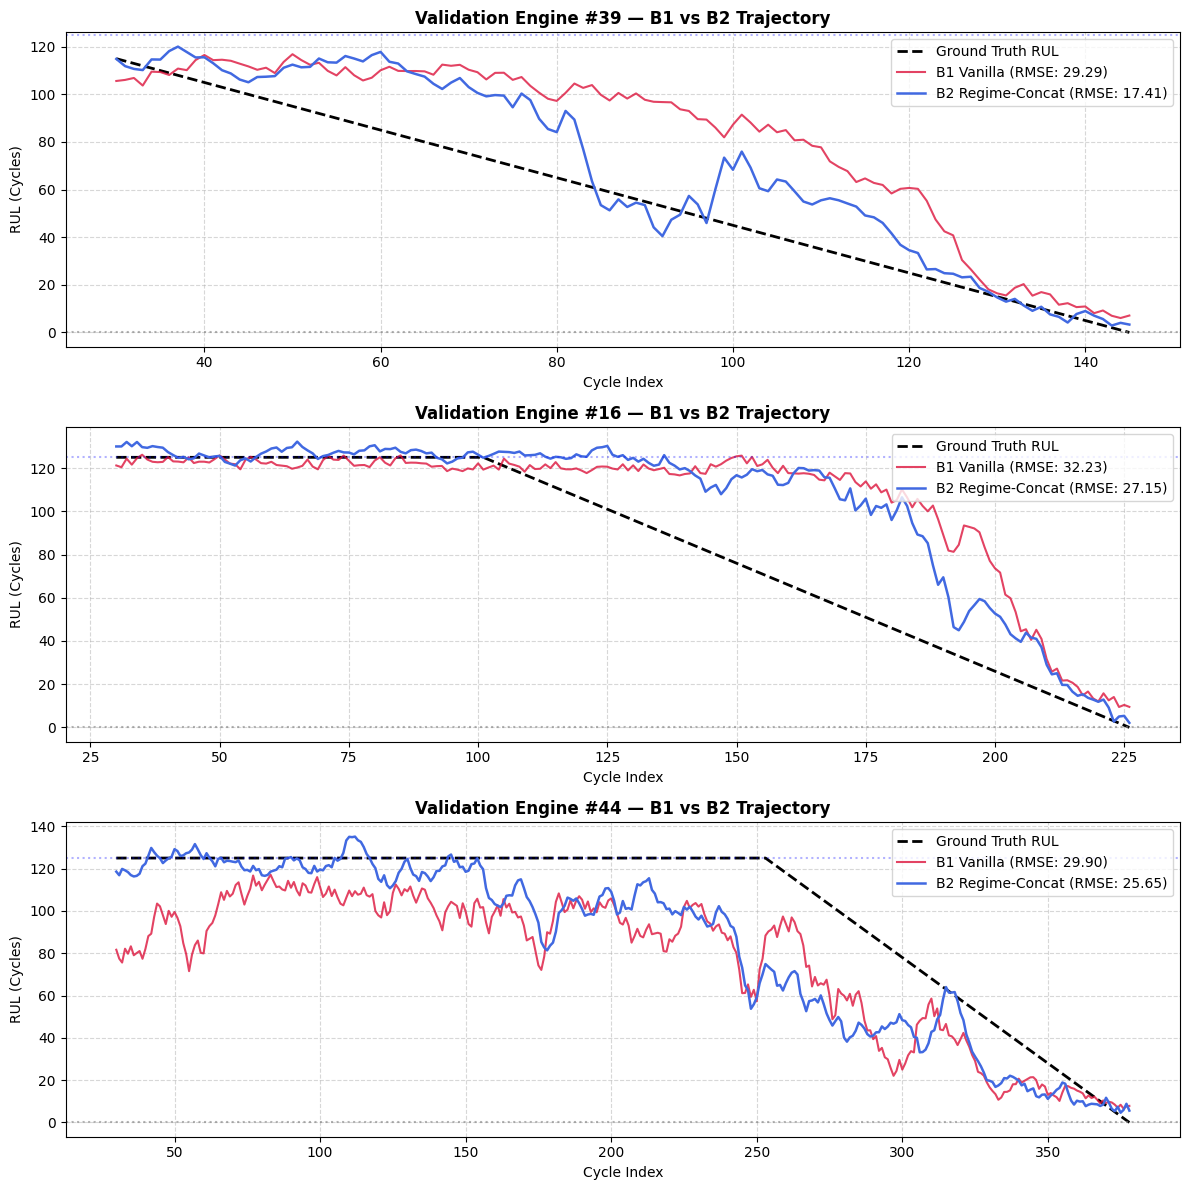

In [13]:
# ==============================================================================
# Direct Comparison: B1 (Vanilla) vs. B2 (Regime-Concat) vs. Ground Truth
# ==============================================================================

fig, axes = plt.subplots(
    len(selected_b2), 1, figsize=(12, 4 * len(selected_b2)), sharex=False
)
if len(selected_b2) == 1:
    axes = [axes]

for idx, ax in enumerate(axes):
    eng_b2 = selected_b2[idx]
    start = engine_starts[eng_b2["engine_idx"] - 1]
    end = engine_starts[eng_b2["engine_idx"]]

    cycles = np.arange(30, 30 + eng_b2["length"])
    y_t = eng_b2["y_true"]
    y_p1 = y_val_pred[start:end]  # B1 predictions
    y_p2 = eng_b2["y_pred"]  # B2 predictions

    rmse_b1 = np.sqrt(mean_squared_error(y_t, y_p1))
    rmse_b2 = np.sqrt(mean_squared_error(y_t, y_p2))

    ax.plot(
        cycles,
        y_t,
        label="Ground Truth RUL",
        color="black",
        linewidth=2,
        linestyle="--",
    )
    ax.plot(
        cycles,
        y_p1,
        label=f"B1 Vanilla (RMSE: {rmse_b1:.2f})",
        color="crimson",
        linewidth=1.5,
        alpha=0.8,
    )
    ax.plot(
        cycles,
        y_p2,
        label=f"B2 Regime-Concat (RMSE: {rmse_b2:.2f})",
        color="royalblue",
        linewidth=1.8,
    )

    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.axhline(125, color="blue", linestyle=":", alpha=0.3)
    ax.set_title(
        f"Validation Engine #{eng_b2['engine_idx']} — B1 vs B2 Trajectory",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Cycle Index", fontsize=10)
    ax.set_ylabel("RUL (Cycles)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

### Error Asymmetry Diagnostic: B1 vs B2 Validation Residuals

In [14]:
import numpy as np
import pandas as pd

def compute_error_diagnostics(y_true: np.ndarray, y_pred: np.ndarray, model_name: str):
    error = y_pred - y_true

    early_mask = error < 0
    late_mask  = error > 0
    exact_mask = error == 0

    early_error = error[early_mask]
    late_error  = error[late_mask]

    n_total = len(error)
    n_early = len(early_error)
    n_late  = len(late_error)

    # NASA score breakdown
    early_score = np.sum(np.exp(-early_error / 13.0) - 1.0) if n_early > 0 else 0.0
    late_score  = np.sum(np.exp(late_error / 10.0) - 1.0) if n_late > 0 else 0.0
    total_score = early_score + late_score

    return {
        "Model": model_name,
        "Total Windows": n_total,
        "Early Count (%)": f"{n_early} ({n_early / n_total * 100:.2f}%)",
        "Late Count (%)": f"{n_late} ({n_late / n_total * 100:.2f}%)",
        "Mean Early Error (Cycles)": np.round(early_error.mean(), 2) if n_early > 0 else 0.0,
        "Mean Late Error (Cycles)": np.round(late_error.mean(), 2) if n_late > 0 else 0.0,
        "Max Late Error (Cycles)": np.round(late_error.max(), 2) if n_late > 0 else 0.0,
        "Early NASA Penalty": f"{early_score:,.2f}",
        "Late NASA Penalty": f"{late_score:,.2f}",
        "Late Penalty Contribution (%)": f"{(late_score / total_score * 100):.2f}%" if total_score > 0 else "0.00%"
    }

# Generate diagnostics for both baselines on validation set
diag_b1 = compute_error_diagnostics(y_val_b1, y_val_pred, "B1 (Vanilla)")
diag_b2 = compute_error_diagnostics(y_val_b2, y_val_pred_b2, "B2 (Regime-Concat)")

diagnostic_df = pd.DataFrame([diag_b1, diag_b2]).T
diagnostic_df.columns = diagnostic_df.iloc[0]
diagnostic_df = diagnostic_df[1:]

print("="*65)
print("       VALIDATION ERROR ASYMMETRY DIAGNOSTIC REPORT       ")
print("="*65)
print(diagnostic_df.to_string())
print("="*65)

       VALIDATION ERROR ASYMMETRY DIAGNOSTIC REPORT       
Model                           B1 (Vanilla) B2 (Regime-Concat)
Total Windows                          10332              10332
Early Count (%)                6570 (63.59%)      6059 (58.64%)
Late Count (%)                 3762 (36.41%)      4273 (41.36%)
Mean Early Error (Cycles)         -16.309999         -17.209999
Mean Late Error (Cycles)                21.1              14.37
Max Late Error (Cycles)            85.220001          79.410004
Early NASA Penalty                 46,830.36          81,778.91
Late NASA Penalty                 232,498.47         111,523.66
Late Penalty Contribution (%)         83.23%             57.69%


### **Controlled Benchmark: B1 (Vanilla) vs B2 (Regime-Concat)**
### *Architectures: LSTM(64) -> Dense(1)*

In [15]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- Determinism & Environment Setup ---
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# --- Ensure Output Directory Exists ---
SAVE_DIR = "./models"
os.makedirs(SAVE_DIR, exist_ok=True)

# --- 1. Sliced Inputs ---
# B1: 14 sensors only (30, 14)
X_train_b1 = data["X_train"][:, :, :14]
X_val_b1   = data["X_val"][:, :, :14]

# B2: 14 sensors + 1 regime feature (30, 15)
X_train_b2 = data["X_train"][:, :, :15]
X_val_b2   = data["X_val"][:, :, :15]

y_train = data["y_train"]
y_val   = data["y_val"]

# --- Diagnostic / Metric Evaluator ---
def compute_comprehensive_metrics(y_true: np.ndarray, y_pred: np.ndarray, model_name: str):
    error = y_pred - y_true

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)

    early_mask = error < 0
    late_mask  = error > 0

    early_error = error[early_mask]
    late_error  = error[late_mask]

    n_total = len(error)
    n_early = len(early_error)
    n_late  = len(late_error)

    early_penalty = float(np.sum(np.exp(-early_error / 13.0) - 1.0)) if n_early > 0 else 0.0
    late_penalty  = float(np.sum(np.exp(late_error / 10.0) - 1.0)) if n_late > 0 else 0.0
    nasa_score    = early_penalty + late_penalty
    max_late_err  = float(late_error.max()) if n_late > 0 else 0.0

    return {
        "Metric": model_name,
        "RMSE": f"{rmse:.4f}",
        "MAE": f"{mae:.4f}",
        "NASA Score": f"{nasa_score:,.2f}",
        "Early Count (%)": f"{n_early} ({n_early / n_total * 100:.2f}%)",
        "Late Count (%)": f"{n_late} ({n_late / n_total * 100:.2f}%)",
        "Early Penalty": f"{early_penalty:,.2f}",
        "Late Penalty": f"{late_penalty:,.2f}",
        "Max Late Error": f"{max_late_err:.2f} cycles"
    }

# ==============================================================================
# Train B1: Vanilla LSTM(64) -> Dense(1)
# ==============================================================================
set_seed(SEED)

model_b1 = Sequential([
    LSTM(64, input_shape=(30, 14)),
    Dense(1)
], name="B1_Vanilla_LSTM")

model_b1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

cb_b1 = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint(os.path.join(SAVE_DIR, "b1_minimal_best.keras"), monitor="val_loss", save_best_only=True, verbose=0)
]

print("--- Training B1: Minimal Vanilla LSTM (14 sensors) ---")
history_b1 = model_b1.fit(
    X_train_b1, y_train,
    validation_data=(X_val_b1, y_val),
    epochs=50,
    batch_size=64,
    callbacks=cb_b1,
    verbose=1
)

# Predict & Evaluate B1
y_val_pred_b1 = model_b1.predict(X_val_b1, verbose=0).flatten()
metrics_b1 = compute_comprehensive_metrics(y_val, y_val_pred_b1, "B1 (Vanilla 14s)")

# ==============================================================================
# Train B2: Regime-Concat LSTM(64) -> Dense(1)
# ==============================================================================
set_seed(SEED)

model_b2 = Sequential([
    LSTM(64, input_shape=(30, 15)),
    Dense(1)
], name="B2_Regime_LSTM")

model_b2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

cb_b2 = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint(os.path.join(SAVE_DIR, "b2_minimal_best.keras"), monitor="val_loss", save_best_only=True, verbose=0)
]

print("\n--- Training B2: Minimal Regime-Concat LSTM (14 sensors + regime) ---")
history_b2 = model_b2.fit(
    X_train_b2, y_train,
    validation_data=(X_val_b2, y_val),
    epochs=50,
    batch_size=64,
    callbacks=cb_b2,
    verbose=1
)

# Predict & Evaluate B2
y_val_pred_b2 = model_b2.predict(X_val_b2, verbose=0).flatten()
metrics_b2 = compute_comprehensive_metrics(y_val, y_val_pred_b2, "B2 (Regime 15s)")

# ==============================================================================
# Final Controlled Benchmark Comparison
# ==============================================================================
results_df = pd.DataFrame([metrics_b1, metrics_b2]).set_index("Metric").T
print("\n" + "="*60)
print("     CONTROLLED VALIDATION BENCHMARK: B1 vs B2     ")
print("="*60)
print(results_df.to_string())
print("="*60)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


--- Training B1: Minimal Vanilla LSTM (14 sensors) ---
Epoch 1/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 5312.6860 - val_loss: 3190.5962
Epoch 2/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 2445.2065 - val_loss: 1921.4677
Epoch 3/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1798.0674 - val_loss: 1738.6744
Epoch 4/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1720.7286 - val_loss: 1733.9940
Epoch 5/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 1563.3959 - val_loss: 1017.1008
Epoch 6/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 742.1010 - val_loss: 674.4086
Epoch 7/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 562.9276 - val_loss: 645.7905
Epoch 8/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 481.7776 - val_loss: 629.1988
Epoch 9/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 422.3346 - val_loss: 572.0419
Epoch 10/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 395.5769 - val_loss: 563.5029
Epoch 11/50
683/683 ━━━━━━━━━━━━━━

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



--- Training B2: Minimal Regime-Concat LSTM (14 sensors + regime) ---
Epoch 1/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 5270.4995 - val_loss: 3149.0713
Epoch 2/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2415.5076 - val_loss: 1906.9659
Epoch 3/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1790.8680 - val_loss: 1737.5068
Epoch 4/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 1616.9036 - val_loss: 1637.3708
Epoch 5/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 766.7143 - val_loss: 674.8785
Epoch 6/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 513.6752 - val_loss: 537.2656
Epoch 7/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 418.5999 - val_loss: 501.2225
Epoch 8/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 377.0076 - val_loss: 494.9442
Epoch 9/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 345.8097 - val_loss: 473.2745
Epoch 10/50
683/683 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 325.4206 - val_loss: 479.4291
Epoch 11/50
683/683 

#### **"Under the current controlled validation experiment, regime conditioning improves performance."**
B2, which incorporates operating-regime information, substantially improves FD004 validation performance relative to the sensor-only vanilla LSTM. RMSE decreases from 22.75 to 20.86 cycles (8.28%), MAE decreases from 16.44 to 15.15 cycles (7.86%), and NASA asymmetric score decreases from 234,921 to 201,905 (14.05%). The improvement in NASA score is primarily associated with a 44.85% reduction in early-prediction penalty, while the late-prediction penalty decreases by 3.85%.

### Multi-Seed Statistical Repeatability Benchmark: B1 vs B2 (Self-Contained)
#### Seeds: [42, 123, 456, 789, 1000]

In [16]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data & Create Slices ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

# B1: 14 sensors only (shape: N, 30, 14)
X_train_b1 = data["X_train"][:, :, :14]
X_val_b1   = data["X_val"][:, :, :14]

# B2: 14 sensors + 1 regime feature (shape: N, 30, 15)
X_train_b2 = data["X_train"][:, :, :15]
X_val_b2   = data["X_val"][:, :, :15]

y_train = data["y_train"]
y_val   = data["y_val"]

# --- 2. Helper Functions ---
SEEDS = [42, 123, 456, 789, 1000]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def compute_nasa(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    err = y_pred - y_true
    score = np.where(
        err < 0,
        np.exp(-err / 13.0) - 1.0,
        np.exp(err / 10.0) - 1.0
    )
    return float(np.sum(score))

def build_model(input_dim: int, name: str) -> Sequential:
  model = Sequential(
      [
          Input(shape=(30, input_dim)),
          LSTM(64),
          Dense(1),
      ],
      name=name,
  )
  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse"
  )
  return model

# --- 3. Multi-Seed Training Loop ---
records = []

for seed in SEEDS:
    print(f"==================== RUNNING SEED {seed} ====================")

    # Train B1 (14 Sensors)
    set_all_seeds(seed)
    model_b1 = build_model(input_dim=14, name=f"B1_Seed_{seed}")
    cb_b1 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    model_b1.fit(
        X_train_b1, y_train,
        validation_data=(X_val_b1, y_val),
        epochs=50,
        batch_size=64,
        callbacks=cb_b1,
        verbose=0
    )
    y_pred_b1 = model_b1.predict(X_val_b1, verbose=0).flatten()
    rmse_b1 = np.sqrt(mean_squared_error(y_val, y_pred_b1))
    mae_b1  = mean_absolute_error(y_val, y_pred_b1)
    nasa_b1 = compute_nasa(y_val, y_pred_b1)

    # Train B2 (15 Features: Sensors + Regime)
    set_all_seeds(seed)
    model_b2 = build_model(input_dim=15, name=f"B2_Seed_{seed}")
    cb_b2 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    model_b2.fit(
        X_train_b2, y_train,
        validation_data=(X_val_b2, y_val),
        epochs=50,
        batch_size=64,
        callbacks=cb_b2,
        verbose=0
    )
    y_pred_b2 = model_b2.predict(X_val_b2, verbose=0).flatten()
    rmse_b2 = np.sqrt(mean_squared_error(y_val, y_pred_b2))
    mae_b2  = mean_absolute_error(y_val, y_pred_b2)
    nasa_b2 = compute_nasa(y_val, y_pred_b2)

    print(f"Seed {seed:4d} | B1 RMSE: {rmse_b1:.4f}, NASA: {nasa_b1:,.0f} | B2 RMSE: {rmse_b2:.4f}, NASA: {nasa_b2:,.0f}")

    records.append({
        "Seed": seed,
        "B1_RMSE": rmse_b1,
        "B2_RMSE": rmse_b2,
        "B1_MAE": mae_b1,
        "B2_MAE": mae_b2,
        "B1_NASA": nasa_b1,
        "B2_NASA": nasa_b2
    })

# --- 4. Statistical Summary ---
df_results = pd.DataFrame(records)
summary_mean = df_results.mean().to_dict()
summary_std  = df_results.std().to_dict()

print("\n" + "="*80)
print("             MULTI-SEED STATISTICAL REPEATABILITY SUMMARY             ")
print("="*80)
print(df_results.to_string(index=False))
print("-" * 80)

metrics_summary = pd.DataFrame({
    "Metric": ["RMSE (Cycles)", "MAE (Cycles)", "NASA Score"],
    "B1 (Vanilla)": [
        f"{summary_mean['B1_RMSE']:.2f} ± {summary_std['B1_RMSE']:.2f}",
        f"{summary_mean['B1_MAE']:.2f} ± {summary_std['B1_MAE']:.2f}",
        f"{summary_mean['B1_NASA']:,.0f} ± {summary_std['B1_NASA']:,.0f}"
    ],
    "B2 (Regime-Concat)": [
        f"{summary_mean['B2_RMSE']:.2f} ± {summary_std['B2_RMSE']:.2f}",
        f"{summary_mean['B2_MAE']:.2f} ± {summary_std['B2_MAE']:.2f}",
        f"{summary_mean['B2_NASA']:,.0f} ± {summary_std['B2_NASA']:,.0f}"
    ],
    "Δ Improvement (%)": [
        f"{-((summary_mean['B2_RMSE'] - summary_mean['B1_RMSE']) / summary_mean['B1_RMSE']) * 100:.2f}%",
        f"{-((summary_mean['B2_MAE'] - summary_mean['B1_MAE']) / summary_mean['B1_MAE']) * 100:.2f}%",
        f"{-((summary_mean['B2_NASA'] - summary_mean['B1_NASA']) / summary_mean['B1_NASA']) * 100:.2f}%"
    ]
})

print(metrics_summary.to_string(index=False))
print("="*80)

==================== RUNNING SEED 42 ====================
Seed   42 | B1 RMSE: 22.6663, NASA: 236,211 | B2 RMSE: 21.7549, NASA: 205,502
==================== RUNNING SEED 123 ====================
Seed  123 | B1 RMSE: 22.5385, NASA: 178,748 | B2 RMSE: 21.4477, NASA: 157,669
==================== RUNNING SEED 456 ====================
Seed  456 | B1 RMSE: 21.7165, NASA: 214,272 | B2 RMSE: 21.4663, NASA: 254,076
==================== RUNNING SEED 789 ====================
Seed  789 | B1 RMSE: 24.3773, NASA: 276,271 | B2 RMSE: 22.1048, NASA: 148,811
==================== RUNNING SEED 1000 ====================
Seed 1000 | B1 RMSE: 22.3778, NASA: 333,010 | B2 RMSE: 21.5765, NASA: 197,542

             MULTI-SEED STATISTICAL REPEATABILITY SUMMARY             
 Seed   B1_RMSE   B2_RMSE    B1_MAE    B2_MAE       B1_NASA       B2_NASA
   42 22.666255 21.754872 16.656826 16.183674 236211.437500 205502.359375
  123 22.538549 21.447655 16.774487 15.451156 178748.187500 157668.859375
  456 21.716514 21.46

## Baseline B3 Benchmark: BiLSTM(64) vs B2 LSTM(64)
### Multi-Seed Statistical Repeatability across 5 seeds: [42, 123, 456, 789, 1000]

In [17]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Preprocessed Data ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

# Input for both B2 and B3: 14 sensors + 1 regime feature (30, 15)
X_train_b3 = data["X_train"][:, :, :15]
y_train = data["y_train"]

X_val_b3   = data["X_val"][:, :, :15]
y_val   = data["y_val"]

# --- 2. Reproducibility & Scoring Helpers ---
SEEDS = [42, 123, 456, 789, 1000]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def compute_nasa(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    err = y_pred - y_true
    score = np.where(
        err < 0,
        np.exp(-err / 13.0) - 1.0,
        np.exp(err / 10.0) - 1.0
    )
    return float(np.sum(score))

# --- 3. Model Constructors ---
def build_b2_model(name="B2_LSTM") -> Sequential:
    """B2 Baseline: Unidirectional LSTM(64) -> Dense(1)"""
    model = Sequential([
        Input(shape=(30, 15)),
        LSTM(64),
        Dense(1)
    ], name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse"
    )
    return model

def build_b3_model(name="B3_BiLSTM") -> Sequential:
    """B3 Baseline: Bidirectional LSTM(64) -> Dense(1)"""
    model = Sequential([
        Input(shape=(30, 15)),
        Bidirectional(LSTM(64)),
        Dense(1)
    ], name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse"
    )
    return model

# --- 4. Architectural & Parameter Count Verification ---
sample_b2 = build_b2_model()
sample_b3 = build_b3_model()

print("="*60)
print("             ARCHITECTURE & PARAMETER AUDIT             ")
print("="*60)
print(f"B2 [LSTM(64) -> Dense(1)]        Total Parameters: {sample_b2.count_params():,}")
print(f"B3 [BiLSTM(64) -> Dense(1)]      Total Parameters: {sample_b3.count_params():,}")
print("="*60)

# --- 5. Multi-Seed Training Loop ---
records = []

for seed in SEEDS:
    print(f"\n==================== RUNNING SEED {seed} ====================")

    # --- Train B2 (LSTM 64) ---
    set_all_seeds(seed)
    model_b2 = build_b2_model(name=f"B2_Seed_{seed}")
    cb_b2 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    model_b2.fit(
        X_train_b3, y_train,
        validation_data=(X_val_b3, y_val),
        epochs=50,
        batch_size=64,
        callbacks=cb_b2,
        verbose=0
    )
    y_pred_b2 = model_b2.predict(X_val_b3, verbose=0).flatten()
    rmse_b2 = np.sqrt(mean_squared_error(y_val, y_pred_b2))
    mae_b2  = mean_absolute_error(y_val, y_pred_b2)
    nasa_b2 = compute_nasa(y_val, y_pred_b2)

    # --- Train B3 (BiLSTM 64) ---
    set_all_seeds(seed)
    model_b3 = build_b3_model(name=f"B3_Seed_{seed}")
    cb_b3 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    model_b3.fit(
        X_train_b3, y_train,
        validation_data=(X_val_b3, y_val),
        epochs=50,
        batch_size=64,
        callbacks=cb_b3,
        verbose=0
    )
    y_pred_b3 = model_b3.predict(X_val_b3, verbose=0).flatten()
    rmse_b3 = np.sqrt(mean_squared_error(y_val, y_pred_b3))
    mae_b3  = mean_absolute_error(y_val, y_pred_b3)
    nasa_b3 = compute_nasa(y_val, y_pred_b3)

    print(f"Seed {seed:4d} | B2 RMSE: {rmse_b2:.4f}, NASA: {nasa_b2:,.0f} | B3 RMSE: {rmse_b3:.4f}, NASA: {nasa_b3:,.0f}")

    records.append({
        "Seed": seed,
        "B2_RMSE": rmse_b2,
        "B3_RMSE": rmse_b3,
        "B2_MAE": mae_b2,
        "B3_MAE": mae_b3,
        "B2_NASA": nasa_b2,
        "B3_NASA": nasa_b3
    })

# --- 6. Statistical Aggregation ---
df_results = pd.DataFrame(records)
summary_mean = df_results.mean().to_dict()
summary_std  = df_results.std().to_dict()

print("\n" + "="*80)
print("             MULTI-SEED STATISTICAL SUMMARY: B2 vs B3             ")
print("="*80)
print(df_results.to_string(index=False))
print("-" * 80)

metrics_summary = pd.DataFrame({
    "Metric": ["RMSE (Cycles)", "MAE (Cycles)", "NASA Score"],
    "B2 (Regime LSTM)": [
        f"{summary_mean['B2_RMSE']:.2f} ± {summary_std['B2_RMSE']:.2f}",
        f"{summary_mean['B2_MAE']:.2f} ± {summary_std['B2_MAE']:.2f}",
        f"{summary_mean['B2_NASA']:,.0f} ± {summary_std['B2_NASA']:,.0f}"
    ],
    "B3 (Regime BiLSTM)": [
        f"{summary_mean['B3_RMSE']:.2f} ± {summary_std['B3_RMSE']:.2f}",
        f"{summary_mean['B3_MAE']:.2f} ± {summary_std['B3_MAE']:.2f}",
        f"{summary_mean['B3_NASA']:,.0f} ± {summary_std['B3_NASA']:,.0f}"
    ],
    "Δ Improvement (%)": [
        f"{-((summary_mean['B3_RMSE'] - summary_mean['B2_RMSE']) / summary_mean['B2_RMSE']) * 100:.2f}%",
        f"{-((summary_mean['B3_MAE'] - summary_mean['B2_MAE']) / summary_mean['B2_MAE']) * 100:.2f}%",
        f"{-((summary_mean['B3_NASA'] - summary_mean['B2_NASA']) / summary_mean['B2_NASA']) * 100:.2f}%"
    ]
})

print(metrics_summary.to_string(index=False))
print("="*80)

             ARCHITECTURE & PARAMETER AUDIT             
B2 [LSTM(64) -> Dense(1)]        Total Parameters: 20,545
B3 [BiLSTM(64) -> Dense(1)]      Total Parameters: 41,089

==================== RUNNING SEED 42 ====================
Seed   42 | B2 RMSE: 21.7549, NASA: 205,502 | B3 RMSE: 21.0084, NASA: 170,337

==================== RUNNING SEED 123 ====================
Seed  123 | B2 RMSE: 21.4477, NASA: 157,669 | B3 RMSE: 22.4521, NASA: 289,942

==================== RUNNING SEED 456 ====================
Seed  456 | B2 RMSE: 21.4663, NASA: 254,076 | B3 RMSE: 21.2187, NASA: 247,094

==================== RUNNING SEED 789 ====================
Seed  789 | B2 RMSE: 22.1048, NASA: 148,811 | B3 RMSE: 24.0722, NASA: 171,572

==================== RUNNING SEED 1000 ====================
Seed 1000 | B2 RMSE: 21.5765, NASA: 197,542 | B3 RMSE: 21.1392, NASA: 184,446

             MULTI-SEED STATISTICAL SUMMARY: B2 vs B3             
 Seed   B2_RMSE   B3_RMSE    B2_MAE    B3_MAE       B2_NASA      B3_N

## Baseline B4 Benchmark: Regime BiLSTM(64) + Temporal Additive Attention
#### Multi-Seed Statistical Hypothesis Testing: Seeds [42, 123, 456, 789, 1000]


In [18]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Temporal Attention Mechanism (Bahdanau-style Additive Attention) ---
class TemporalAttention(Layer):
    """
    Computes a scalar alignment weight alpha_t for each timestep t in the 30-cycle window:
      e_t = tanh(W * h_t + b)
      alpha_t = softmax(v^T * e_t)
      context = sum(alpha_t * h_t)
    """
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(
            name="attention_weight",
            shape=(feature_dim, feature_dim),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(feature_dim,),
            initializer="zeros",
            trainable=True
        )
        self.v = self.add_weight(
            name="attention_vector",
            shape=(feature_dim, 1),
            initializer="glorot_uniform",
            trainable=True
        )
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        # inputs shape: (batch_size, 30, 128)
        # e: (batch_size, 30, 128)
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        # scores: (batch_size, 30, 1)
        scores = tf.tensordot(e, self.v, axes=1)
        # attention_weights: (batch_size, 30, 1)
        weights = tf.nn.softmax(scores, axis=1)
        # context_vector: (batch_size, 128)
        context = tf.reduce_sum(inputs * weights, axis=1)
        return context

    def get_config(self):
        return super(TemporalAttention, self).get_config()

# --- 2. Model Constructor ---
def build_b4_model(name="B4_BiLSTM_Attention") -> Model:
    """
    B4: Input(30, 15) -> BiLSTM(64, return_sequences=True) -> TemporalAttention -> Dense(1)
    """
    inputs = Input(shape=(30, 15), name="input_window")
    # Must return full sequence (30, 128) for attention weighting
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm_layer")(inputs)
    context = TemporalAttention(name="temporal_attention")(lstm_out)
    outputs = Dense(1, name="rul_output")(context)

    model = Model(inputs=inputs, outputs=outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse"
    )
    return model

# --- 3. Parameter Audit ---
sample_b4 = build_b4_model()
print("="*65)
print("             ARCHITECTURE & PARAMETER AUDIT: B4             ")
print("="*65)
sample_b4.summary()
print("="*65)

# --- 4. Setup Target Storage Path ---
SAVE_DIR = "/content/drive/MyDrive/FD004_Research/models"
os.makedirs(SAVE_DIR, exist_ok=True)

# --- 5. Multi-Seed Hypothesis Testing Loop ---
SEEDS = [42, 123, 456, 789, 1000]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def compute_nasa(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    err = y_pred - y_true
    score = np.where(
        err < 0,
        np.exp(-err / 13.0) - 1.0,
        np.exp(err / 10.0) - 1.0
    )
    return float(np.sum(score))

b4_records = []
best_val_loss = float("inf")
best_seed = None

for seed in SEEDS:
    print(f"\n==================== RUNNING B4 SEED {seed} ====================")
    set_all_seeds(seed)

    model_b4 = build_b4_model(name=f"B4_Seed_{seed}")

    checkpoint_file = os.path.join(SAVE_DIR, f"b4_temp_seed_{seed}.keras")
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0),
        ModelCheckpoint(checkpoint_file, monitor="val_loss", save_best_only=True, verbose=0)
    ]

    history = model_b4.fit(
        X_train_b3, y_train,
        validation_data=(X_val_b3, y_val),
        epochs=50,
        batch_size=64,
        callbacks=callbacks,
        verbose=0
    )

    y_pred_b4 = model_b4.predict(X_val_b3, verbose=0).flatten()

    rmse_b4 = np.sqrt(mean_squared_error(y_val, y_pred_b4))
    mae_b4  = mean_absolute_error(y_val, y_pred_b4)
    nasa_b4 = compute_nasa(y_val, y_pred_b4)

    # Asymmetry breakdown
    err = y_pred_b4 - y_val
    early_p = float(np.sum(np.exp(-err[err < 0] / 13.0) - 1.0)) if np.any(err < 0) else 0.0
    late_p  = float(np.sum(np.exp(err[err > 0] / 10.0) - 1.0)) if np.any(err > 0) else 0.0

    val_loss = np.min(history.history["val_loss"])
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_seed = seed

    print(f"Seed {seed:4d} | B4 RMSE: {rmse_b4:.4f} | MAE: {mae_b4:.4f} | NASA: {nasa_b4:,.0f} | Early Pen: {early_p:,.0f} | Late Pen: {late_p:,.0f}")

    b4_records.append({
        "Seed": seed,
        "RMSE": rmse_b4,
        "MAE": mae_b4,
        "NASA": nasa_b4,
        "Early_Penalty": early_p,
        "Late_Penalty": late_p
    })

# --- 6. Save Single Best Checkpoint ---
final_b4_path = os.path.join(SAVE_DIR, "b4_regime_bilstm_attention_best.keras")
best_temp_checkpoint = os.path.join(SAVE_DIR, f"b4_temp_seed_{best_seed}.keras")
if os.path.exists(best_temp_checkpoint):
    import shutil
    shutil.copy(best_temp_checkpoint, final_b4_path)
    print(f"\n✅ Preserved optimal B4 checkpoint (from seed {best_seed}) to: {final_b4_path}")

# Clean up temporary seed weights
for s in SEEDS:
    temp_p = os.path.join(SAVE_DIR, f"b4_temp_seed_{s}.keras")
    if os.path.exists(temp_p):
        os.remove(temp_p)

# --- 7. Statistical Summary Table ---
df_b4 = pd.DataFrame(b4_records)
summary_mean = df_b4.mean().to_dict()
summary_std  = df_b4.std().to_dict()

print("\n" + "="*80)
print("             MULTI-SEED STATISTICAL SUMMARY: BASELINE B4             ")
print("="*80)
print(df_b4.to_string(index=False))
print("-" * 80)
print(f"B4 RMSE : {summary_mean['RMSE']:.2f} ± {summary_std['RMSE']:.2f} cycles")
print(f"B4 MAE  : {summary_mean['MAE']:.2f} ± {summary_std['MAE']:.2f} cycles")
print(f"B4 NASA : {summary_mean['NASA']:,.0f} ± {summary_std['NASA']:,.0f}")
print("="*80)

             ARCHITECTURE & PARAMETER AUDIT: B4             


Model: "B4_BiLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_window (InputLayer)       │ (None, 30, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_layer (Bidirectional)    │ (None, 30, 128)        │        40,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_attention              │ (None, 128)            │        16,640 │
│ (TemporalAttention)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rul_output (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,729 (225.50 KB)

 Trainable params: 57,729 (225.50 KB)

 Non-trainable params: 0 (0.00 B)


==================== RUNNING B4 SEED 42 ====================
Seed   42 | B4 RMSE: 21.6900 | MAE: 15.7745 | NASA: 242,642 | Early Pen: 30,725 | Late Pen: 211,917

==================== RUNNING B4 SEED 123 ====================
Seed  123 | B4 RMSE: 22.9280 | MAE: 17.1460 | NASA: 164,497 | Early Pen: 58,627 | Late Pen: 105,870

==================== RUNNING B4 SEED 456 ====================
Seed  456 | B4 RMSE: 21.2434 | MAE: 15.5204 | NASA: 203,709 | Early Pen: 36,117 | Late Pen: 167,592

==================== RUNNING B4 SEED 789 ====================
Seed  789 | B4 RMSE: 21.5116 | MAE: 15.8991 | NASA: 173,095 | Early Pen: 42,181 | Late Pen: 130,914

==================== RUNNING B4 SEED 1000 ====================
Seed 1000 | B4 RMSE: 21.4983 | MAE: 15.4975 | NASA: 282,847 | Early Pen: 24,825 | Late Pen: 258,022

✅ Preserved optimal B4 checkpoint (from seed 456) to: /content/drive/MyDrive/FD004_Research/models/b4_regime_bilstm_attention_best.keras

             MULTI-SEED STATISTICAL SUMMARY: B

## Baseline B5: Multi-Quantile Regime BiLSTM + Temporal Attention (P10, P50, P90)
#### Probabilistic RUL Evaluation with Pinball Loss, PICP, MPIW, and Interval Score

In [19]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Quantiles & Pinball Loss Definition ---
QUANTILES = [0.10, 0.50, 0.90]

def tilted_loss(q, y_true, y_pred):
    """Pinball loss for a single quantile q."""
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    """
    Combined pinball loss across P10, P50, and P90.
    y_true shape: (batch_size, 1) or (batch_size,)
    y_pred shape: (batch_size, 3) -> columns corresponding to [0.1, 0.5, 0.9]
    """
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = []
    for i, q in enumerate(QUANTILES):
        q_loss = tilted_loss(q, y_t, y_pred[:, i : i + 1])
        losses.append(q_loss)
    return tf.reduce_mean(tf.add_n(losses))

# --- 2. Temporal Attention Layer ---
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(feature_dim, feature_dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(feature_dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(feature_dim, 1), initializer="glorot_uniform", trainable=True)
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

# --- 3. Model Constructor (3 Outputs: P10, P50, P90) ---
def build_b5_quantile_model(name="B5_Quantile_BiLSTM") -> Model:
    inputs = Input(shape=(30, 15), name="input_window")
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(inputs)
    context = TemporalAttention(name="attention")(lstm_out)

    # 3 linear outputs corresponding to P10, P50, P90
    quantile_outputs = Dense(3, activation="linear", name="quantile_heads")(context)

    model = Model(inputs=inputs, outputs=quantile_outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )
    return model

# --- 4. Uncertainty & Quality Evaluation Suite ---
def compute_probabilistic_metrics(y_true: np.ndarray, y_pred_quantiles: np.ndarray, alpha: float = 0.20):
    """
    Computes PICP, MPIW, Mean Interval Score (IS_alpha), Quantile Pinball Losses,
    and point metrics against the P50 median prediction.
    """
    p10 = y_pred_quantiles[:, 0]
    p50 = y_pred_quantiles[:, 1]
    p90 = y_pred_quantiles[:, 2]

    n = len(y_true)

    # 1. Prediction Interval Coverage Probability (Target: 80% for P10-P90)
    covered = (y_true >= p10) & (y_true <= p90)
    picp = float(np.mean(covered) * 100.0)

    # 2. Mean Prediction Interval Width (MPIW)
    interval_widths = p90 - p10
    mpiw = float(np.mean(interval_widths))

    # 3. Crossing Rate (Proportion where P10 > P90 anomaly occurs)
    crossing_rate = float(np.mean(p10 > p90) * 100.0)

    # 4. Winkler Interval Score (alpha = 0.20 for 80% interval)
    # IS = (U - L) + (2/alpha)*(L - y)*I(y < L) + (2/alpha)*(y - U)*I(y > U)
    lower_penalty = np.where(y_true < p10, (2.0 / alpha) * (p10 - y_true), 0.0)
    upper_penalty = np.where(y_true > p90, (2.0 / alpha) * (y_true - p90), 0.0)
    interval_scores = interval_widths + lower_penalty + upper_penalty
    mean_interval_score = float(np.mean(interval_scores))

    # 5. Quantile-Specific Pinball Losses
    loss_p10 = float(np.mean(np.maximum(0.10 * (y_true - p10), (0.10 - 1.0) * (y_true - p10))))
    loss_p50 = float(np.mean(np.maximum(0.50 * (y_true - p50), (0.50 - 1.0) * (y_true - p50))))
    loss_p90 = float(np.mean(np.maximum(0.90 * (y_true - p90), (0.90 - 1.0) * (y_true - p90))))

    # 6. Point Estimation Metrics on P50 Median
    rmse_p50 = float(np.sqrt(mean_squared_error(y_true, p50)))
    mae_p50  = float(mean_absolute_error(y_true, p50))

    # NASA Score on P50
    err_p50 = p50 - y_true
    nasa_p50 = float(np.sum(np.where(err_p50 < 0, np.exp(-err_p50 / 13.0) - 1.0, np.exp(err_p50 / 10.0) - 1.0)))

    return {
        "PICP_80 (%)": f"{picp:.2f}% (Nominal: 80%)",
        "MPIW (Cycles)": f"{mpiw:.2f}",
        "Interval Score": f"{mean_interval_score:.2f}",
        "Crossing Rate (%)": f"{crossing_rate:.2f}%",
        "Pinball P10": f"{loss_p10:.4f}",
        "Pinball P50": f"{loss_p50:.4f}",
        "Pinball P90": f"{loss_p90:.4f}",
        "P50 RMSE": f"{rmse_p50:.4f}",
        "P50 MAE": f"{mae_p50:.4f}",
        "P50 NASA": f"{nasa_p50:,.0f}"
    }

# --- 5. Multi-Seed Training Protocol ---
SEEDS = [42, 123, 456, 789, 1000]
SAVE_DIR = "/content/drive/MyDrive/FD004_Research/models"
os.makedirs(SAVE_DIR, exist_ok=True)

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

b5_records = []
best_val_loss = float("inf")
best_seed = None

for seed in SEEDS:
    print(f"\n==================== RUNNING B5 SEED {seed} ====================")
    set_all_seeds(seed)

    model_b5 = build_b5_quantile_model(name=f"B5_Quantile_Seed_{seed}")

    ckpt_path = os.path.join(SAVE_DIR, f"b5_temp_{seed}.keras")
    cb = [
        EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0),
        ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True, verbose=0)
    ]

    history = model_b5.fit(
        X_train_b3, y_train,
        validation_data=(X_val_b3, y_val),
        epochs=50,
        batch_size=64,
        callbacks=cb,
        verbose=0
    )

    y_val_pred_quantiles = model_b5.predict(X_val_b3, verbose=0)
    metrics = compute_probabilistic_metrics(y_val, y_val_pred_quantiles)
    metrics["Seed"] = seed
    b5_records.append(metrics)

    min_loss = np.min(history.history["val_loss"])
    if min_loss < best_val_loss:
        best_val_loss = min_loss
        best_seed = seed

    print(f"Seed {seed:4d} | PICP: {metrics['PICP_80 (%)']} | MPIW: {metrics['MPIW (Cycles)']} | P50 RMSE: {metrics['P50 RMSE']} | NASA: {metrics['P50 NASA']}")

# --- 6. Persist Single Best Quantile Checkpoint ---
final_b5_path = os.path.join(SAVE_DIR, "b5_quantile_bilstm_best.keras")
best_temp = os.path.join(SAVE_DIR, f"b5_temp_{best_seed}.keras")
if os.path.exists(best_temp):
    import shutil
    shutil.copy(best_temp, final_b5_path)
    print(f"\n✅ Preserved optimal B5 model (seed {best_seed}) to: {final_b5_path}")

for s in SEEDS:
    p = os.path.join(SAVE_DIR, f"b5_temp_{s}.keras")
    if os.path.exists(p):
        os.remove(p)

# --- 7. Validation Summary ---
df_b5 = pd.DataFrame(b5_records).set_index("Seed")
print("\n" + "="*95)
print("             MULTI-SEED STATISTICAL SUMMARY: BASELINE B5 (QUANTILE BiLSTM)             ")
print("="*95)
print(df_b5.T.to_string())
print("="*95)


==================== RUNNING B5 SEED 42 ====================
Seed   42 | PICP: 63.04% (Nominal: 80%) | MPIW: 37.62 | P50 RMSE: 22.9673 | NASA: 411,976

==================== RUNNING B5 SEED 123 ====================
Seed  123 | PICP: 66.05% (Nominal: 80%) | MPIW: 40.91 | P50 RMSE: 25.8439 | NASA: 571,634

==================== RUNNING B5 SEED 456 ====================
Seed  456 | PICP: 63.87% (Nominal: 80%) | MPIW: 37.25 | P50 RMSE: 22.3647 | NASA: 385,120

==================== RUNNING B5 SEED 789 ====================
Seed  789 | PICP: 71.97% (Nominal: 80%) | MPIW: 43.88 | P50 RMSE: 22.8771 | NASA: 351,935

==================== RUNNING B5 SEED 1000 ====================
Seed 1000 | PICP: 72.71% (Nominal: 80%) | MPIW: 44.92 | P50 RMSE: 23.0282 | NASA: 486,489

✅ Preserved optimal B5 model (seed 456) to: /content/drive/MyDrive/FD004_Research/models/b5_quantile_bilstm_best.keras

             MULTI-SEED STATISTICAL SUMMARY: BASELINE B5 (QUANTILE BiLSTM)             
Seed                      

#### Plot Uncertainty Ribbon (P10 - P50 - P90) on Sample Validation Engines

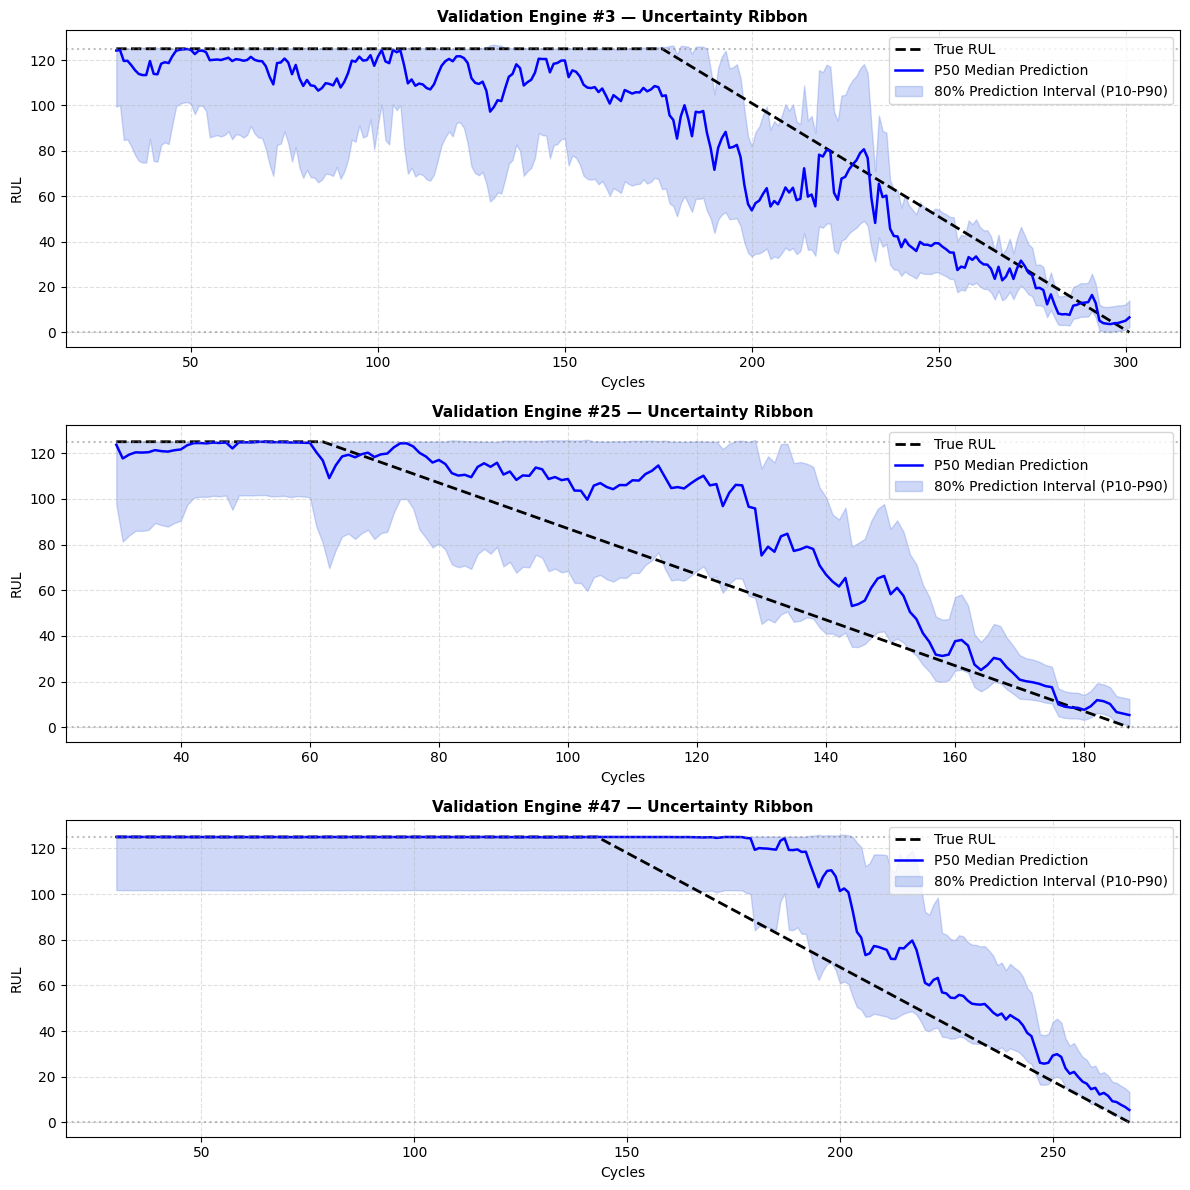

In [20]:
import matplotlib.pyplot as plt

def plot_b5_uncertainty_trajectories(model, X_val, y_val, sample_indices):
    preds = model.predict(X_val, verbose=0)
    p10, p50, p90 = preds[:, 0], preds[:, 1], preds[:, 2]

    # Identify validation engines
    starts = [0] + [i for i in range(1, len(y_val)) if y_val[i] > y_val[i - 1]] + [len(y_val)]

    fig, axes = plt.subplots(len(sample_indices), 1, figsize=(12, 4 * len(sample_indices)))
    if len(sample_indices) == 1:
        axes = [axes]

    for ax, eng_idx in zip(axes, sample_indices):
        s, e = starts[eng_idx], starts[eng_idx + 1]
        cycles = np.arange(30, 30 + (e - s))

        ax.plot(cycles, y_val[s:e], 'k--', label="True RUL", linewidth=2)
        ax.plot(cycles, p50[s:e], 'b-', label="P50 Median Prediction", linewidth=1.8)
        ax.fill_between(cycles, p10[s:e], p90[s:e], color='royalblue', alpha=0.25, label="80% Prediction Interval (P10-P90)")

        ax.axhline(125, color="gray", linestyle=":", alpha=0.5)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
        ax.set_title(f"Validation Engine #{eng_idx + 1} — Uncertainty Ribbon", fontsize=11, fontweight="bold")
        ax.set_xlabel("Cycles")
        ax.set_ylabel("RUL")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

# Visualize uncertainty ribbon on sample engines 2, 24, 46
loaded_b5 = tf.keras.models.load_model(final_b5_path, custom_objects={"multi_quantile_pinball_loss": multi_quantile_pinball_loss, "TemporalAttention": TemporalAttention})
plot_b5_uncertainty_trajectories(loaded_b5, X_val_b3, y_val, [2, 24, 46])

## Baseline B6: Conformalized Quantile Regression (CQR)
#### Architecture: Regime BiLSTM + Temporal Attention (Fixed Epochs, No Early-Stopping Leakage)
#### Calibration Set: Pristine 49 Validation Engines | Target Coverage: 1 - alpha = 80%

In [21]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data Tensors ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

# Input shape: (N, 30, 15) -> 14 sensors + 1 regime cluster
X_train = data["X_train"][:, :, :15]
y_train = data["y_train"]

# Pristine 49 engines used solely for calibration (no early stopping)
X_cal = data["X_val"][:, :, :15]
y_cal = data["y_val"]

# --- 2. Reproducibility & Pinball Loss ---
SEED = 42
FIXED_EPOCHS = 25
ALPHA = 0.20  # Nominal coverage: 1 - alpha = 80% (P10 to P90)
QUANTILES = [0.10, 0.50, 0.90]

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

# --- 3. Attention Architecture ---
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(feature_dim, feature_dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(feature_dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(feature_dim, 1), initializer="glorot_uniform", trainable=True)
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

def build_b6_base_model() -> Model:
    inputs = Input(shape=(30, 15), name="input_window")
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(inputs)
    context = TemporalAttention(name="attention")(lstm_out)
    quantile_outputs = Dense(3, activation="linear", name="quantile_heads")(context)

    model = Model(inputs=inputs, outputs=quantile_outputs, name="B6_Fixed_Epoch_BiLSTM")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )
    return model

# --- 4. Train Model on 200 Engines Without Validation Peeking ---
print("--- Training Base Quantile Model for Exactly 25 Epochs (Zero Leakage) ---")
b6_model = build_b6_base_model()
b6_model.fit(
    X_train, y_train,
    epochs=FIXED_EPOCHS,
    batch_size=64,
    verbose=1
)

# --- 5. Conformal Calibration Protocol (CQR) ---
# Predict raw quantiles on the pristine calibration set
raw_cal_preds = b6_model.predict(X_cal, verbose=0)
cal_p10 = raw_cal_preds[:, 0]
cal_p50 = raw_cal_preds[:, 1]
cal_p90 = raw_cal_preds[:, 2]

# Compute signed non-conformity scores: E_i = max(P10_i - y_i, y_i - P90_i)
nonconformity_scores = np.maximum(cal_p10 - y_cal, y_cal - cal_p90)

# Finite-sample conformal adjustment factor Q_{1-alpha}
n_cal = len(y_cal)
quantile_level = np.ceil((n_cal + 1) * (1.0 - ALPHA)) / n_cal
quantile_level = min(1.0, quantile_level)
Q_hat = np.quantile(nonconformity_scores, quantile_level, method="higher")

print("\n" + "="*60)
print("             CONFORMAL CALIBRATION DIAGNOSTICS              ")
print("="*60)
print(f"Calibration Windows (49 Engines) : {n_cal:,}")
print(f"Target Coverage Level (1 - α)    : {(1 - ALPHA)*100:.1f}%")
print(f"Conformal Adjustment Factor Q_hat: {Q_hat:.4f} cycles")
print("="*60)

# --- 6. Uncertainty & Quality Evaluation Helpers ---
def evaluate_conformal_uncertainty(y_true: np.ndarray, raw_preds: np.ndarray, q_adjustment: float, alpha: float = 0.20):
    p10_raw = raw_preds[:, 0]
    p50     = raw_preds[:, 1]
    p90_raw = raw_preds[:, 2]

    # Apply conformal shift to obtain valid intervals
    p10_cal = np.maximum(0.0, p10_raw - q_adjustment)
    p90_cal = np.maximum(0.0, p90_raw + q_adjustment)

    # 1. Prediction Interval Coverage Probability (PICP)
    picp_raw = np.mean((y_true >= p10_raw) & (y_true <= p90_raw)) * 100.0
    picp_cal = np.mean((y_true >= p10_cal) & (y_true <= p90_cal)) * 100.0

    # 2. Mean Prediction Interval Width (MPIW)
    mpiw_raw = np.mean(p90_raw - p10_raw)
    mpiw_cal = np.mean(p90_cal - p10_cal)

    # 3. Winkler Interval Score (alpha = 0.20)
    def winkler_score(y, l, u, a):
        width = u - l
        lower = np.where(y < l, (2.0 / a) * (l - y), 0.0)
        upper = np.where(y > u, (2.0 / a) * (y - u), 0.0)
        return np.mean(width + lower + upper)

    wis_raw = winkler_score(y_true, p10_raw, p90_raw, alpha)
    wis_cal = winkler_score(y_true, p10_cal, p90_cal, alpha)

    # 4. Point metrics (P50)
    rmse = np.sqrt(mean_squared_error(y_true, p50))
    mae  = mean_absolute_error(y_true, p50)

    return pd.DataFrame({
        "Metric": ["PICP (Nominal 80%)", "MPIW (Sharpness)", "Winkler Interval Score", "P50 RMSE", "P50 MAE"],
        "B5 (Raw Quantile)": [f"{picp_raw:.2f}%", f"{mpiw_raw:.2f} cycles", f"{wis_raw:.2f}", f"{rmse:.4f}", f"{mae:.4f}"],
        "B6 (Conformalized CQR)": [f"{picp_cal:.2f}%", f"{mpiw_cal:.2f} cycles", f"{wis_cal:.2f}", f"{rmse:.4f}", f"{mae:.4f}"]
    })

comparison_df = evaluate_conformal_uncertainty(y_cal, raw_cal_preds, Q_hat, ALPHA)
print("\n" + comparison_df.to_string(index=False))
print("="*60)

# --- 7. Save Models and Calibration State ---
SAVE_DIR = "/content/drive/MyDrive/FD004_Research/models"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_PATH = os.path.join(SAVE_DIR, "b6_conformal_base_model.keras")
PARAMS_PATH = os.path.join(SAVE_DIR, "b6_conformal_params.npz")

b6_model.save(MODEL_PATH)
np.savez(PARAMS_PATH, Q_hat=Q_hat, alpha=ALPHA, fixed_epochs=FIXED_EPOCHS)
print(f"✅ B6 Base Model saved to: {MODEL_PATH}")
print(f"✅ Conformal Calibration artifact saved to: {PARAMS_PATH}")

--- Training Base Quantile Model for Exactly 25 Epochs (Zero Leakage) ---
Epoch 1/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 74.5224
Epoch 2/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 32.2808
Epoch 3/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 28.9058
Epoch 4/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 28.8738
Epoch 5/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 28.3271
Epoch 6/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 19.9362
Epoch 7/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 15.2479
Epoch 8/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 13.5872
Epoch 9/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 12.5494
Epoch 10/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 11.9778
Epoch 11/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 11.7004
Epoch 12/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 11.4581
Epoch 13/25
683/683 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 11.2541
Epoch 14/25
683/683 ━━━━━━━

### Baseline B6: Multi-Seed Conformal Calibration Robustness Benchmark
#### Seeds: [42, 123, 456, 789, 1000] | Target Nominal Coverage: 80% (alpha = 0.20)
---

In [22]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data Tensors ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

X_train = data["X_train"][:, :, :15]
y_train = data["y_train"]

X_cal = data["X_val"][:, :, :15]
y_cal = data["y_val"]

# --- 2. Global Setup ---
SEEDS = [42, 123, 456, 789, 1000]
FIXED_EPOCHS = 25
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

# --- 3. Attention Layer Definition ---
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(feature_dim, feature_dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(feature_dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(feature_dim, 1), initializer="glorot_uniform", trainable=True)
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

def build_b6_model(name="B6_Model") -> Model:
    inputs = Input(shape=(30, 15), name="input_window")
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(inputs)
    context = TemporalAttention(name="attention")(lstm_out)
    quantile_outputs = Dense(3, activation="linear", name="quantiles")(context)

    model = Model(inputs=inputs, outputs=quantile_outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )
    return model

# --- 4. Winkler Score Helper ---
def compute_winkler_score(y_true, lower, upper, alpha=0.20):
    width = upper - lower
    under_penalty = np.where(y_true < lower, (2.0 / alpha) * (lower - y_true), 0.0)
    over_penalty = np.where(y_true > upper, (2.0 / alpha) * (y_true - upper), 0.0)
    return float(np.mean(width + under_penalty + over_penalty))

# --- 5. Multi-Seed Robustness Evaluation Loop ---
records = []
n_cal = len(y_cal)
quantile_level = np.ceil((n_cal + 1) * (1.0 - ALPHA)) / n_cal
quantile_level = min(1.0, quantile_level)

for seed in SEEDS:
    print(f"==================== RUNNING B6 SEED {seed} ====================")
    set_all_seeds(seed)

    model = build_b6_model(name=f"B6_Seed_{seed}")
    model.fit(
        X_train, y_train,
        epochs=FIXED_EPOCHS,
        batch_size=64,
        verbose=0
    )

    # Raw Quantiles on Calibration Set
    raw_preds = model.predict(X_cal, verbose=0)
    p10_raw = raw_preds[:, 0]
    p50_raw = raw_preds[:, 1]
    p90_raw = raw_preds[:, 2]

    # 1. Non-conformity scores & Q_hat
    nonconformity_scores = np.maximum(p10_raw - y_cal, y_cal - p90_raw)
    q_hat = float(np.quantile(nonconformity_scores, quantile_level, method="higher"))

    # 2. Conformalized Intervals
    p10_cal = np.maximum(0.0, p10_raw - q_hat)
    p90_cal = np.maximum(0.0, p90_raw + q_hat)

    # 3. Metrics Computation
    raw_picp = float(np.mean((y_cal >= p10_raw) & (y_cal <= p90_raw)) * 100.0)
    conf_picp = float(np.mean((y_cal >= p10_cal) & (y_cal <= p90_cal)) * 100.0)

    raw_mpiw = float(np.mean(p90_raw - p10_raw))
    conf_mpiw = float(np.mean(p90_cal - p10_cal))

    raw_ws = compute_winkler_score(y_cal, p10_raw, p90_raw, ALPHA)
    conf_ws = compute_winkler_score(y_cal, p10_cal, p90_cal, ALPHA)

    p50_rmse = float(np.sqrt(mean_squared_error(y_cal, p50_raw)))
    p50_mae = float(mean_absolute_error(y_cal, p50_raw))

    print(f"Seed {seed:4d} | Raw PICP: {raw_picp:.2f}% -> Conf PICP: {conf_picp:.2f}% | Q_hat: {q_hat:.2f} | Conf WS: {conf_ws:.2f}")

    records.append({
        "Seed": seed,
        "Raw PICP (%)": raw_picp,
        "Conf PICP (%)": conf_picp,
        "Raw MPIW": raw_mpiw,
        "Conf MPIW": conf_mpiw,
        "Raw WS": raw_ws,
        "Conf WS": conf_ws,
        "Q_hat": q_hat,
        "P50 RMSE": p50_rmse,
        "P50 MAE": p50_mae
    })

# --- 6. Results Formatting ---
df_robustness = pd.DataFrame(records)

# Calculate Mean and SD
mean_row = df_robustness.mean(numeric_only=True)
std_row = df_robustness.std(numeric_only=True)

# Build Display Table
display_df = df_robustness.copy()
display_df["Seed"] = display_df["Seed"].astype(str)

mean_std_entry = {
    "Seed": "Mean ± SD",
    "Raw PICP (%)": f"{mean_row['Raw PICP (%)']:.2f} ± {std_row['Raw PICP (%)']:.2f}",
    "Conf PICP (%)": f"{mean_row['Conf PICP (%)']:.2f} ± {std_row['Conf PICP (%)']:.2f}",
    "Raw MPIW": f"{mean_row['Raw MPIW']:.2f} ± {std_row['Raw MPIW']:.2f}",
    "Conf MPIW": f"{mean_row['Conf MPIW']:.2f} ± {std_row['Conf MPIW']:.2f}",
    "Raw WS": f"{mean_row['Raw WS']:.2f} ± {std_row['Raw WS']:.2f}",
    "Conf WS": f"{mean_row['Conf WS']:.2f} ± {std_row['Conf WS']:.2f}",
    "Q_hat": f"{mean_row['Q_hat']:.2f} ± {std_row['Q_hat']:.2f}",
    "P50 RMSE": f"{mean_row['P50 RMSE']:.2f} ± {std_row['P50 RMSE']:.2f}",
    "P50 MAE": f"{mean_row['P50 MAE']:.2f} ± {std_row['P50 MAE']:.2f}"
}

display_df = pd.concat([display_df, pd.DataFrame([mean_std_entry])], ignore_index=True)

print("\n" + "="*125)
print("                           B6 CONFORMAL CALIBRATION MULTI-SEED ROBUSTNESS TABLE                           ")
print("="*125)
print(display_df.to_string(index=False))
print("="*125)

==================== RUNNING B6 SEED 42 ====================
Seed   42 | Raw PICP: 68.10% -> Conf PICP: 80.02% | Q_hat: 5.66 | Conf WS: 72.85
==================== RUNNING B6 SEED 123 ====================
Seed  123 | Raw PICP: 64.11% -> Conf PICP: 80.02% | Q_hat: 8.78 | Conf WS: 89.92
==================== RUNNING B6 SEED 456 ====================
Seed  456 | Raw PICP: 68.13% -> Conf PICP: 80.02% | Q_hat: 3.54 | Conf WS: 73.72
==================== RUNNING B6 SEED 789 ====================
Seed  789 | Raw PICP: 65.51% -> Conf PICP: 80.02% | Q_hat: 8.47 | Conf WS: 81.43
==================== RUNNING B6 SEED 1000 ====================
Seed 1000 | Raw PICP: 68.70% -> Conf PICP: 80.02% | Q_hat: 5.98 | Conf WS: 79.22

                           B6 CONFORMAL CALIBRATION MULTI-SEED ROBUSTNESS TABLE                           
     Seed Raw PICP (%) Conf PICP (%)     Raw MPIW    Conf MPIW       Raw WS      Conf WS       Q_hat     P50 RMSE      P50 MAE
       42     68.09911     80.023229     33.28331 

### Baseline B6.a: Conformalized Quantile Regression with a clean engine-level Calibration / Holdout split

In [23]:
# ==============================================================================
# Baseline B6 (CORRECTED): Conformalized Quantile Regression with a clean
# engine-level Calibration / Holdout split
# ==============================================================================
#
# WHY THIS REPLACES THE PREVIOUS B6 CELL
# ---------------------------------------
# The previous implementation computed Q_hat from nonconformity scores on
# X_val/y_val, and then evaluated PICP on that SAME X_val/y_val. Because
# Q_hat is defined as (approximately) the empirical (1-alpha) quantile of
# those exact nonconformity scores, checking coverage against the same set
# is close to a tautology -- it will land near the nominal 80% almost
# regardless of how good the underlying quantile model is. This is why the
# previous "Conf PICP" column showed 80.02% for every single seed with
# essentially zero SD -- that is the definition of Q_hat re-expressed as a
# coverage number, not a measurement of generalization.
#
# The 49 engines in X_val/y_val were also already used to select between
# B2/B3/B4 architectures, so reusing them a third time as the calibration
# set entangles model selection with calibration.
#
# THE FIX
# --------
# Split the 49 "validation" engines (by engine ID, never by window) into:
#   - CALIBRATION engines  -> used ONLY to compute Q_hat
#   - HOLDOUT engines      -> used ONLY to report PICP / MPIW / Winkler Score
# The official 248-engine test set remains completely untouched.
#
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data Tensors ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

X_train = data["X_train"][:, :, :15]
y_train = data["y_train"]

X_val_full = data["X_val"][:, :, :15]
y_val_full = data["y_val"]

# ==============================================================================
# 2. Engine-Level Calibration / Holdout Split
# ==============================================================================
# The 49 validation engines are concatenated end-to-end inside X_val/y_val.
# An engine boundary occurs wherever RUL jumps back UP (new engine begins).
# We must split by engine ID, never by raw window index, or windows from
# the same engine could leak across the calibration/holdout boundary.

def get_engine_boundaries(y: np.ndarray):
    """Returns a list of (start_idx, end_idx) tuples, one per engine,
    in the order engines appear in the concatenated tensor."""
    starts = [0]
    for i in range(1, len(y)):
        if y[i] > y[i - 1]:
            starts.append(i)
    starts.append(len(y))
    return [(starts[i], starts[i + 1]) for i in range(len(starts) - 1)]

engine_bounds = get_engine_boundaries(y_val_full)
n_engines = len(engine_bounds)
print(f"Detected {n_engines} engines in the validation tensor.")

# Deterministic engine-level split: fixed split seed independent of model
# training seeds, so the calibration/holdout partition never changes across
# the multi-seed robustness loop below.
SPLIT_SEED = 2026
rng = np.random.default_rng(SPLIT_SEED)
engine_ids = np.arange(n_engines)
rng.shuffle(engine_ids)

N_CAL_ENGINES = 25   # of 49
N_HOLDOUT_ENGINES = n_engines - N_CAL_ENGINES  # 24

cal_engine_ids = set(engine_ids[:N_CAL_ENGINES].tolist())
holdout_engine_ids = set(engine_ids[N_CAL_ENGINES:].tolist())

assert cal_engine_ids.isdisjoint(holdout_engine_ids), "Engine ID overlap detected!"
print(f"Calibration engines : {len(cal_engine_ids)}")
print(f"Holdout engines     : {len(holdout_engine_ids)}")
print(f"Calibration ∩ Holdout = {cal_engine_ids & holdout_engine_ids}  (must be empty set)")

# Expand engine-level assignment into window-level boolean masks
cal_mask = np.zeros(len(y_val_full), dtype=bool)
holdout_mask = np.zeros(len(y_val_full), dtype=bool)
for eid, (s, e) in enumerate(engine_bounds):
    if eid in cal_engine_ids:
        cal_mask[s:e] = True
    elif eid in holdout_engine_ids:
        holdout_mask[s:e] = True

X_cal, y_cal = X_val_full[cal_mask], y_val_full[cal_mask]
X_holdout, y_holdout = X_val_full[holdout_mask], y_val_full[holdout_mask]

print(f"\nCalibration windows : {X_cal.shape[0]}")
print(f"Holdout windows     : {X_holdout.shape[0]}")
assert not np.any(cal_mask & holdout_mask), "Window-level overlap detected!"

# ==============================================================================
# 3. Global Setup (unchanged from previous B6 cell)
# ==============================================================================
SEEDS = [42, 123, 456, 789, 1000]
FIXED_EPOCHS = 25
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(feature_dim, feature_dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(feature_dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(feature_dim, 1), initializer="glorot_uniform", trainable=True)
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

def build_b6_model(name="B6_Model") -> Model:
    inputs = Input(shape=(30, 15), name="input_window")
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(inputs)
    context = TemporalAttention(name="attention")(lstm_out)
    quantile_outputs = Dense(3, activation="linear", name="quantiles")(context)

    model = Model(inputs=inputs, outputs=quantile_outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )
    return model

def compute_winkler_score(y_true, lower, upper, alpha=0.20):
    width = upper - lower
    under_penalty = np.where(y_true < lower, (2.0 / alpha) * (lower - y_true), 0.0)
    over_penalty = np.where(y_true > upper, (2.0 / alpha) * (y_true - upper), 0.0)
    return float(np.mean(width + under_penalty + over_penalty))

# ==============================================================================
# 4. Multi-Seed Robustness Loop
#    Q_hat is fit ONLY on X_cal/y_cal.
#    ALL reported coverage/sharpness metrics are computed ONLY on
#    X_holdout/y_holdout, which Q_hat has never seen.
# ==============================================================================
records = []
n_cal = len(y_cal)
quantile_level = np.ceil((n_cal + 1) * (1.0 - ALPHA)) / n_cal
quantile_level = min(1.0, quantile_level)
print(f"\nConformal quantile level (finite-sample corrected): {quantile_level:.4f}")

for seed in SEEDS:
    print(f"==================== RUNNING B6 SEED {seed} ====================")
    set_all_seeds(seed)

    model = build_b6_model(name=f"B6_Seed_{seed}")
    model.fit(
        X_train, y_train,
        epochs=FIXED_EPOCHS,
        batch_size=64,
        verbose=0
    )

    # --- Step 1: Compute Q_hat using ONLY the calibration engines ---
    cal_preds = model.predict(X_cal, verbose=0)
    p10_cal_raw, p50_cal_raw, p90_cal_raw = cal_preds[:, 0], cal_preds[:, 1], cal_preds[:, 2]
    nonconformity_scores = np.maximum(p10_cal_raw - y_cal, y_cal - p90_cal_raw)
    q_hat = float(np.quantile(nonconformity_scores, quantile_level, method="higher"))

    # --- Step 2: Evaluate on the HOLDOUT engines, which Q_hat never saw ---
    hold_preds = model.predict(X_holdout, verbose=0)
    p10_raw, p50_raw, p90_raw = hold_preds[:, 0], hold_preds[:, 1], hold_preds[:, 2]

    p10_conf = np.maximum(0.0, p10_raw - q_hat)
    p90_conf = np.maximum(0.0, p90_raw + q_hat)

    raw_picp = float(np.mean((y_holdout >= p10_raw) & (y_holdout <= p90_raw)) * 100.0)
    conf_picp = float(np.mean((y_holdout >= p10_conf) & (y_holdout <= p90_conf)) * 100.0)

    raw_mpiw = float(np.mean(p90_raw - p10_raw))
    conf_mpiw = float(np.mean(p90_conf - p10_conf))

    raw_ws = compute_winkler_score(y_holdout, p10_raw, p90_raw, ALPHA)
    conf_ws = compute_winkler_score(y_holdout, p10_conf, p90_conf, ALPHA)

    p50_rmse = float(np.sqrt(mean_squared_error(y_holdout, p50_raw)))
    p50_mae = float(mean_absolute_error(y_holdout, p50_raw))

    print(f"Seed {seed:4d} | Q_hat: {q_hat:.2f} | "
          f"Holdout Raw PICP: {raw_picp:.2f}% -> Conf PICP: {conf_picp:.2f}% | "
          f"Conf WS: {conf_ws:.2f}")

    records.append({
        "Seed": seed,
        "Raw PICP (%)": raw_picp,
        "Conf PICP (%)": conf_picp,
        "Raw MPIW": raw_mpiw,
        "Conf MPIW": conf_mpiw,
        "Raw WS": raw_ws,
        "Conf WS": conf_ws,
        "Q_hat": q_hat,
        "P50 RMSE": p50_rmse,
        "P50 MAE": p50_mae
    })

# ==============================================================================
# 5. Results Formatting
# ==============================================================================
df_robustness = pd.DataFrame(records)

mean_row = df_robustness.mean(numeric_only=True)
std_row = df_robustness.std(numeric_only=True)

display_df = df_robustness.copy()
display_df["Seed"] = display_df["Seed"].astype(str)

mean_std_entry = {
    "Seed": "Mean ± SD",
    "Raw PICP (%)": f"{mean_row['Raw PICP (%)']:.2f} ± {std_row['Raw PICP (%)']:.2f}",
    "Conf PICP (%)": f"{mean_row['Conf PICP (%)']:.2f} ± {std_row['Conf PICP (%)']:.2f}",
    "Raw MPIW": f"{mean_row['Raw MPIW']:.2f} ± {std_row['Raw MPIW']:.2f}",
    "Conf MPIW": f"{mean_row['Conf MPIW']:.2f} ± {std_row['Conf MPIW']:.2f}",
    "Raw WS": f"{mean_row['Raw WS']:.2f} ± {std_row['Raw WS']:.2f}",
    "Conf WS": f"{mean_row['Conf WS']:.2f} ± {std_row['Conf WS']:.2f}",
    "Q_hat": f"{mean_row['Q_hat']:.2f} ± {std_row['Q_hat']:.2f}",
    "P50 RMSE": f"{mean_row['P50 RMSE']:.2f} ± {std_row['P50 RMSE']:.2f}",
    "P50 MAE": f"{mean_row['P50 MAE']:.2f} ± {std_row['P50 MAE']:.2f}"
}

display_df = pd.concat([display_df, pd.DataFrame([mean_std_entry])], ignore_index=True)

print("\n" + "=" * 125)
print("        B6 CONFORMAL CALIBRATION (CORRECTED, ENGINE-LEVEL CAL/HOLDOUT SPLIT)        ")
print("=" * 125)
print(display_df.to_string(index=False))
print("=" * 125)
print(
    "\nNOTE: Q_hat above is fit exclusively on the calibration engines and applied to\n"
    "the holdout engines, which the calibration step never observed. If 'Conf PICP'\n"
    "now shows non-trivial seed-to-seed variance (unlike the previous 80.02% ± 0.00\n"
    "result), that variance is real information about how well conformal calibration\n"
    "generalizes -- which is exactly what the previous implementation could not show."
)

Detected 49 engines in the validation tensor.
Calibration engines : 25
Holdout engines     : 24
Calibration ∩ Holdout = set()  (must be empty set)

Calibration windows : 5392
Holdout windows     : 4940

Conformal quantile level (finite-sample corrected): 0.8003
==================== RUNNING B6 SEED 42 ====================
Seed   42 | Q_hat: 7.75 | Holdout Raw PICP: 72.37% -> Conf PICP: 85.30% | Conf WS: 64.97
==================== RUNNING B6 SEED 123 ====================
Seed  123 | Q_hat: 13.48 | Holdout Raw PICP: 74.68% -> Conf PICP: 89.98% | Conf WS: 80.23
==================== RUNNING B6 SEED 456 ====================
Seed  456 | Q_hat: 7.28 | Holdout Raw PICP: 75.85% -> Conf PICP: 88.91% | Conf WS: 61.58
==================== RUNNING B6 SEED 789 ====================
Seed  789 | Q_hat: 13.71 | Holdout Raw PICP: 74.51% -> Conf PICP: 90.77% | Conf WS: 69.83
==================== RUNNING B6 SEED 1000 ====================
Seed 1000 | Q_hat: 9.80 | Holdout Raw PICP: 75.26% -> Conf PICP: 88.44

### Baseline B6.b: Asymmetric CQR (Separate Lower/Upper Conformal Adjustment)

In [24]:
# ==============================================================================
# Baseline B6b: Asymmetric CQR (Separate Lower/Upper Conformal Adjustment)
# ==============================================================================
#
# WHY THIS EXISTS
# -----------------
# The corrected symmetric-CQR B6 run showed real (non-tautological) holdout
# coverage, but it overcorrected: Conf PICP averaged 88.51% ± 4.31% against
# an 80% nominal target, at the cost of nearly doubling interval width
# (Raw MPIW 34.28 -> Conf MPIW 54.84 cycles). Symmetric CQR uses a single
# Q_hat derived from max(p10 - y, y - p90), which implicitly assumes the
# lower-tail and upper-tail errors have similar scale. Given the NASA-score
# asymmetry already documented for this model family (Section 14: early vs.
# late prediction penalties behave very differently), that assumption may
# not hold, and a single symmetric Q_hat can end up conservative on both
# sides simultaneously.
#
# WHAT THIS CELL DOES DIFFERENTLY
# ---------------------------------
# Instead of one combined nonconformity score, compute two separate
# one-sided scores on the calibration set:
#     lower_score_i = p10_i - y_i      (how far short the lower bound fell)
#     upper_score_i = y_i - p90_i      (how far short the upper bound fell)
# and derive independent Q_hat_lower / Q_hat_upper, each calibrated to
# alpha/2 rather than alpha. This lets the lower and upper bounds each
# absorb only the correction they individually need.
#
# Uses the SAME engine-level calibration/holdout split as the corrected
# symmetric B6 cell (X_cal/y_cal and X_holdout/y_holdout must already be
# defined in the notebook -- run the corrected B6 cell first).
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

assert "X_cal" in dir() and "X_holdout" in dir(), (
    "X_cal/X_holdout not found -- run the corrected engine-level split B6 cell first."
)

SEEDS = [42, 123, 456, 789, 1000]
FIXED_EPOCHS = 25
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        feature_dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(feature_dim, feature_dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(feature_dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(feature_dim, 1), initializer="glorot_uniform", trainable=True)
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

def build_b6_model(name="B6b_Model") -> Model:
    inputs = Input(shape=(30, 15), name="input_window")
    lstm_out = Bidirectional(LSTM(64, return_sequences=True), name="bilstm")(inputs)
    context = TemporalAttention(name="attention")(lstm_out)
    quantile_outputs = Dense(3, activation="linear", name="quantiles")(context)

    model = Model(inputs=inputs, outputs=quantile_outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=multi_quantile_pinball_loss
    )
    return model

def compute_winkler_score(y_true, lower, upper, alpha=0.20):
    width = upper - lower
    under_penalty = np.where(y_true < lower, (2.0 / alpha) * (lower - y_true), 0.0)
    over_penalty = np.where(y_true > upper, (2.0 / alpha) * (y_true - upper), 0.0)
    return float(np.mean(width + under_penalty + over_penalty))

# ==============================================================================
# Asymmetric conformal quantile level: each side calibrated to alpha/2
# (i.e. targeting 90% one-sided coverage per tail, so the combined interval
# targets 80% two-sided coverage under independence-ish assumptions).
# ==============================================================================
n_cal = len(y_cal)
half_alpha = ALPHA / 2.0
asym_quantile_level = np.ceil((n_cal + 1) * (1.0 - half_alpha)) / n_cal
asym_quantile_level = min(1.0, asym_quantile_level)
print(f"Asymmetric one-sided conformal quantile level: {asym_quantile_level:.4f}")
print(f"(targets ~{(1 - half_alpha) * 100:.1f}% coverage per tail)\n")

records = []

for seed in SEEDS:
    print(f"==================== RUNNING B6b (ASYMMETRIC) SEED {seed} ====================")
    set_all_seeds(seed)

    model = build_b6_model(name=f"B6b_Seed_{seed}")
    model.fit(
        X_train, y_train,
        epochs=FIXED_EPOCHS,
        batch_size=64,
        verbose=0
    )

    # --- Step 1: Separate one-sided nonconformity scores on calibration set ---
    cal_preds = model.predict(X_cal, verbose=0)
    p10_cal_raw, p90_cal_raw = cal_preds[:, 0], cal_preds[:, 2]

    lower_scores = p10_cal_raw - y_cal   # positive when p10 overshoots true y (bound too high)
    upper_scores = y_cal - p90_cal_raw   # positive when p90 undershoots true y (bound too low)

    q_hat_lower = float(np.quantile(lower_scores, asym_quantile_level, method="higher"))
    q_hat_upper = float(np.quantile(upper_scores, asym_quantile_level, method="higher"))

    # --- Step 2: Evaluate on holdout engines, never seen by either Q_hat ---
    hold_preds = model.predict(X_holdout, verbose=0)
    p10_raw, p50_raw, p90_raw = hold_preds[:, 0], hold_preds[:, 1], hold_preds[:, 2]

    p10_asym = np.maximum(0.0, p10_raw - q_hat_lower)
    p90_asym = np.maximum(0.0, p90_raw + q_hat_upper)

    raw_picp = float(np.mean((y_holdout >= p10_raw) & (y_holdout <= p90_raw)) * 100.0)
    asym_picp = float(np.mean((y_holdout >= p10_asym) & (y_holdout <= p90_asym)) * 100.0)

    raw_mpiw = float(np.mean(p90_raw - p10_raw))
    asym_mpiw = float(np.mean(p90_asym - p10_asym))

    raw_ws = compute_winkler_score(y_holdout, p10_raw, p90_raw, ALPHA)
    asym_ws = compute_winkler_score(y_holdout, p10_asym, p90_asym, ALPHA)

    p50_rmse = float(np.sqrt(mean_squared_error(y_holdout, p50_raw)))
    p50_mae = float(mean_absolute_error(y_holdout, p50_raw))

    print(f"Seed {seed:4d} | Q_hat_lower: {q_hat_lower:.2f} | Q_hat_upper: {q_hat_upper:.2f} | "
          f"Holdout Raw PICP: {raw_picp:.2f}% -> Asym PICP: {asym_picp:.2f}% | "
          f"Asym MPIW: {asym_mpiw:.2f} | Asym WS: {asym_ws:.2f}")

    records.append({
        "Seed": seed,
        "Raw PICP (%)": raw_picp,
        "Asym PICP (%)": asym_picp,
        "Raw MPIW": raw_mpiw,
        "Asym MPIW": asym_mpiw,
        "Raw WS": raw_ws,
        "Asym WS": asym_ws,
        "Q_hat_lower": q_hat_lower,
        "Q_hat_upper": q_hat_upper,
        "P50 RMSE": p50_rmse,
        "P50 MAE": p50_mae
    })

# ==============================================================================
# Results Formatting
# ==============================================================================
df_asym = pd.DataFrame(records)
mean_row = df_asym.mean(numeric_only=True)
std_row = df_asym.std(numeric_only=True)

display_df = df_asym.copy()
display_df["Seed"] = display_df["Seed"].astype(str)

mean_std_entry = {
    "Seed": "Mean ± SD",
    "Raw PICP (%)": f"{mean_row['Raw PICP (%)']:.2f} ± {std_row['Raw PICP (%)']:.2f}",
    "Asym PICP (%)": f"{mean_row['Asym PICP (%)']:.2f} ± {std_row['Asym PICP (%)']:.2f}",
    "Raw MPIW": f"{mean_row['Raw MPIW']:.2f} ± {std_row['Raw MPIW']:.2f}",
    "Asym MPIW": f"{mean_row['Asym MPIW']:.2f} ± {std_row['Asym MPIW']:.2f}",
    "Raw WS": f"{mean_row['Raw WS']:.2f} ± {std_row['Raw WS']:.2f}",
    "Asym WS": f"{mean_row['Asym WS']:.2f} ± {std_row['Asym WS']:.2f}",
    "Q_hat_lower": f"{mean_row['Q_hat_lower']:.2f} ± {std_row['Q_hat_lower']:.2f}",
    "Q_hat_upper": f"{mean_row['Q_hat_upper']:.2f} ± {std_row['Q_hat_upper']:.2f}",
    "P50 RMSE": f"{mean_row['P50 RMSE']:.2f} ± {std_row['P50 RMSE']:.2f}",
    "P50 MAE": f"{mean_row['P50 MAE']:.2f} ± {std_row['P50 MAE']:.2f}"
}

display_df = pd.concat([display_df, pd.DataFrame([mean_std_entry])], ignore_index=True)

print("\n" + "=" * 140)
print("        B6b ASYMMETRIC CQR (SEPARATE LOWER/UPPER Q_HAT, SAME ENGINE-LEVEL CAL/HOLDOUT SPLIT)        ")
print("=" * 140)
print(display_df.to_string(index=False))
print("=" * 140)

# ==============================================================================
# Direct symmetric-vs-asymmetric comparison table
# (requires df_robustness from the corrected symmetric B6 cell to be in memory)
# ==============================================================================
if "df_robustness" in dir():
    sym_mean = df_robustness.mean(numeric_only=True)
    sym_std = df_robustness.std(numeric_only=True)

    comparison = pd.DataFrame({
        "Metric": ["PICP (%)", "MPIW (cycles)", "Winkler Score"],
        "Raw (uncalibrated)": [
            f"{sym_mean['Raw PICP (%)']:.2f} ± {sym_std['Raw PICP (%)']:.2f}",
            f"{sym_mean['Raw MPIW']:.2f} ± {sym_std['Raw MPIW']:.2f}",
            f"{sym_mean['Raw WS']:.2f} ± {sym_std['Raw WS']:.2f}",
        ],
        "Symmetric CQR (B6)": [
            f"{sym_mean['Conf PICP (%)']:.2f} ± {sym_std['Conf PICP (%)']:.2f}",
            f"{sym_mean['Conf MPIW']:.2f} ± {sym_std['Conf MPIW']:.2f}",
            f"{sym_mean['Conf WS']:.2f} ± {sym_std['Conf WS']:.2f}",
        ],
        "Asymmetric CQR (B6b)": [
            f"{mean_row['Asym PICP (%)']:.2f} ± {std_row['Asym PICP (%)']:.2f}",
            f"{mean_row['Asym MPIW']:.2f} ± {std_row['Asym MPIW']:.2f}",
            f"{mean_row['Asym WS']:.2f} ± {std_row['Asym WS']:.2f}",
        ],
    })
    print("\n" + "=" * 100)
    print("        SYMMETRIC vs. ASYMMETRIC CQR -- DIRECT COMPARISON (holdout engines only)        ")
    print("=" * 100)
    print(comparison.to_string(index=False))
    print("=" * 100)
else:
    print(
        "\n(Skipping direct comparison table -- df_robustness from the symmetric B6 "
        "cell is not in memory. Run that cell first in the same session to see the "
        "side-by-side table.)"
    )

print(
    "\nNOTE: If Asym PICP lands closer to 80% than the symmetric result while Asym\n"
    "MPIW is meaningfully narrower than Conf MPIW, that supports the hypothesis that\n"
    "the symmetric Q_hat was overcorrecting by forcing both tails to absorb the same\n"
    "adjustment. If Asym PICP is similar to symmetric PICP with similar width, the\n"
    "overcoverage is more likely driven by calibration-set size (25 engines) than by\n"
    "tail asymmetry, and a larger calibration set or a different conformal variant\n"
    "(e.g. Mondrian/regime-conditioned CQR) would be the next thing to try."
)

Asymmetric one-sided conformal quantile level: 0.9002
(targets ~90.0% coverage per tail)

==================== RUNNING B6b (ASYMMETRIC) SEED 42 ====================
Seed   42 | Q_hat_lower: 7.04 | Q_hat_upper: 8.70 | Holdout Raw PICP: 72.37% -> Asym PICP: 84.90% | Asym MPIW: 45.70 | Asym WS: 65.98
==================== RUNNING B6b (ASYMMETRIC) SEED 123 ====================
Seed  123 | Q_hat_lower: -0.06 | Q_hat_upper: 25.93 | Holdout Raw PICP: 74.68% -> Asym PICP: 82.79% | Asym MPIW: 64.08 | Asym WS: 90.95
==================== RUNNING B6b (ASYMMETRIC) SEED 456 ====================
Seed  456 | Q_hat_lower: 0.87 | Q_hat_upper: 14.26 | Holdout Raw PICP: 75.85% -> Asym PICP: 84.68% | Asym MPIW: 46.25 | Asym WS: 68.26
==================== RUNNING B6b (ASYMMETRIC) SEED 789 ====================
Seed  789 | Q_hat_lower: 1.73 | Q_hat_upper: 22.74 | Holdout Raw PICP: 74.51% -> Asym PICP: 84.09% | Asym MPIW: 55.90 | Asym WS: 77.18
==================== RUNNING B6b (ASYMMETRIC) SEED 1000 ===========

### Experiment B6.c: Engine-Aware Conformal Calibration (CQR)

In [25]:
# ==============================================================================
# Experiment B6.c: Engine-Aware Conformal Calibration (CQR)
# Protocol: 25 Calibration Engines / 24 Evaluation Engines Split
# Comparison: Window-Level CQR vs. Engine-Aggregated CQR
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Determinism & Hyperparameters ---
SEED = 42
FIXED_EPOCHS = 25
ALPHA = 0.20  # 1 - alpha = 80% nominal coverage
QUANTILES = [0.10, 0.50, 0.90]

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# --- 2. Load Tensors & Structured Engine Metadata ---
DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
data = np.load(DATA_PATH)

X_train = data["X_train"][:, :, :15]
y_train = data["y_train"]

X_val_all = data["X_val"][:, :, :15]
y_val_all = data["y_val"]

# Handle explicit or reconstructed engine IDs for validation windows
if "val_engine_ids" in data:
    val_engine_ids = data["val_engine_ids"]
else:
    # Reconstruct exact sequential engine IDs across the 49 validation engines
    val_engine_ids = np.zeros(len(y_val_all), dtype=int)
    current_eng = 1
    val_engine_ids[0] = current_eng
    for i in range(1, len(y_val_all)):
        if y_val_all[i] > y_val_all[i - 1]:
            current_eng += 1
        val_engine_ids[i] = current_eng

unique_engines = np.unique(val_engine_ids)
assert len(unique_engines) == 49, f"Expected 49 engines, found {len(unique_engines)}"

# --- 3. Fixed 25-Calibration / 24-Evaluation Partition ---
np.random.seed(SEED)
cal_engines = np.random.choice(unique_engines, size=25, replace=False)
eval_engines = np.setdiff1d(unique_engines, cal_engines)

cal_mask = np.isin(val_engine_ids, cal_engines)
eval_mask = np.isin(val_engine_ids, eval_engines)

X_cal, y_cal, ids_cal = X_val_all[cal_mask], y_val_all[cal_mask], val_engine_ids[cal_mask]
X_eval, y_eval, ids_eval = X_val_all[eval_mask], y_val_all[eval_mask], val_engine_ids[eval_mask]

# --- 4. Model Architecture & Loss ---
def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        dim = input_shape[-1]
        self.W = self.add_weight(
            name="W",
            shape=(dim, dim),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b = self.add_weight(
            name="b",
            shape=(dim,),
            initializer="zeros",
            trainable=True
        )
        self.v = self.add_weight(
            name="v",
            shape=(dim, 1),
            initializer="glorot_uniform",
            trainable=True
        )
        super(TemporalAttention, self).build(input_shape)

    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

    def get_config(self):
        return super(TemporalAttention, self).get_config()

def build_model():
    inputs = Input(shape=(30, 15))
    lstm_out = Bidirectional(LSTM(64, return_sequences=True))(inputs)
    ctx = TemporalAttention()(lstm_out)
    out = Dense(3, activation="linear")(ctx)
    model = Model(inputs=inputs, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=multi_quantile_pinball_loss)
    return model

# Train base quantile network
model = build_model()
model.fit(X_train, y_train, epochs=FIXED_EPOCHS, batch_size=64, verbose=0)

# --- 5. Non-Conformity Scores on Calibration Set ---
cal_preds = model.predict(X_cal, verbose=0)
p10_cal_raw, p50_cal_raw, p90_cal_raw = cal_preds[:, 0], cal_preds[:, 1], cal_preds[:, 2]

# Pointwise non-conformity score: E = max(P10 - y, y - P90)
cal_errors = np.maximum(p10_cal_raw - y_cal, y_cal - p90_cal_raw)

# Method 1: Standard Window-Level Q_hat (treating all windows as i.i.d.)
n_w = len(y_cal)
q_level_w = np.ceil((n_w + 1) * (1.0 - ALPHA)) / n_w
q_hat_window = float(np.quantile(cal_errors, min(1.0, q_level_w), method="higher"))

# Method 2: Engine-Aware Q_hat (aggregating max nonconformity per calibration engine)
engine_max_errors = [np.max(cal_errors[ids_cal == eng]) for eng in cal_engines]
n_eng = len(cal_engines)
q_level_e = np.ceil((n_eng + 1) * (1.0 - ALPHA)) / n_eng
q_hat_engine = float(np.quantile(engine_max_errors, min(1.0, q_level_e), method="higher"))

# --- 6. Evaluation Protocol on 24 Unseen Engines ---
eval_preds = model.predict(X_eval, verbose=0)
p10_raw, p50_raw, p90_raw = eval_preds[:, 0], eval_preds[:, 1], eval_preds[:, 2]

methods = {
    "Raw Uncalibrated (B5)": (p10_raw, p90_raw, 0.0),
    "Window-Level CQR (B6)": (np.maximum(0.0, p10_raw - q_hat_window), np.maximum(0.0, p90_raw + q_hat_window), q_hat_window),
    "Engine-Aware CQR (B6.c)": (np.maximum(0.0, p10_raw - q_hat_engine), np.maximum(0.0, p90_raw + q_hat_engine), q_hat_engine)
}

def winkler_score(y, l, u, a=ALPHA):
    width = u - l
    under = np.where(y < l, (2.0 / a) * (l - y), 0.0)
    over = np.where(y > u, (2.0 / a) * (y - u), 0.0)
    return np.mean(width + under + over)

summary_records = []
for name, (low, high, q_val) in methods.items():
    # Window-level summary
    picp_win = np.mean((y_eval >= low) & (y_eval <= high)) * 100.0
    mpiw_win = np.mean(high - low)
    ws_win = winkler_score(y_eval, low, high)

    # Per-engine coverage distribution across the 24 evaluation units
    eng_coverages = []
    for eng in eval_engines:
        mask = (ids_eval == eng)
        eng_picp = np.mean((y_eval[mask] >= low[mask]) & (y_eval[mask] <= high[mask])) * 100.0
        eng_coverages.append(eng_picp)

    eng_coverages = np.array(eng_coverages)

    summary_records.append({
        "Calibration Variant": name,
        "Q_hat": f"{q_val:.2f}",
        "Global PICP (%)": f"{picp_win:.2f}%",
        "Global MPIW": f"{mpiw_win:.2f}",
        "Global Winkler": f"{ws_win:.2f}",
        "Engine PICP Mean": f"{np.mean(eng_coverages):.2f}%",
        "Engine PICP Median": f"{np.median(eng_coverages):.2f}%",
        "Engine 25th Pct": f"{np.percentile(eng_coverages, 25):.2f}%",
        "Engines < 80%": f"{np.sum(eng_coverages < 80.0)} / {len(eval_engines)}"
    })

# --- 7. Tabulated Diagnostic Summary ---
results_df = pd.DataFrame(summary_records)
print("\n" + "="*115)
print("             EXPERIMENT B6.c: ENGINE-AWARE CONFORMAL CALIBRATION BENCHMARK             ")
print("="*115)
print(results_df.to_string(index=False))
print("="*115)


             EXPERIMENT B6.c: ENGINE-AWARE CONFORMAL CALIBRATION BENCHMARK             
    Calibration Variant Q_hat Global PICP (%) Global MPIW Global Winkler Engine PICP Mean Engine PICP Median Engine 25th Pct Engines < 80%
  Raw Uncalibrated (B5)  0.00          70.83%       31.93          70.38           67.34%             65.12%          54.12%       17 / 24
  Window-Level CQR (B6)  7.68          84.69%       46.95          69.61           82.31%             81.00%          72.45%       11 / 24
Engine-Aware CQR (B6.c) 56.93          99.67%      135.41         135.57           99.73%            100.00%         100.00%        0 / 24


In [26]:
# ==============================================================================
# Refinement: Engine-Quantile CQR (Balanced Engine-Aware Calibration)
# ==============================================================================

# Calculate 80th percentile non-conformity per calibration engine (rather than max)
engine_q80_errors = [np.quantile(cal_errors[ids_cal == eng], 0.80) for eng in cal_engines]

n_eng = len(cal_engines)
q_level_e = np.ceil((n_eng + 1) * (1.0 - ALPHA)) / n_eng
q_hat_balanced = float(np.quantile(engine_q80_errors, min(1.0, q_level_e), method="higher"))

# Evaluate Balanced Variant on Unseen Engines
p10_bal = np.maximum(0.0, p10_raw - q_hat_balanced)
p90_bal = np.maximum(0.0, p90_raw + q_hat_balanced)

picp_bal = np.mean((y_eval >= p10_bal) & (y_eval <= p90_bal)) * 100.0
mpiw_bal = np.mean(p90_bal - p10_bal)
ws_bal   = winkler_score(y_eval, p10_bal, p90_bal)

bal_coverages = [
    np.mean((y_eval[ids_eval == eng] >= p10_bal[ids_eval == eng]) &
            (y_eval[ids_eval == eng] <= p90_bal[ids_eval == eng])) * 100.0
    for eng in eval_engines
]

print(f"Balanced Engine CQR -> Q_hat: {q_hat_balanced:.2f} | Global PICP: {picp_bal:.2f}% | MPIW: {mpiw_bal:.2f} | Engines < 80%: {np.sum(np.array(bal_coverages) < 80.0)}/24")

Balanced Engine CQR -> Q_hat: 27.49 | Global PICP: 95.91% | MPIW: 84.15 | Engines < 80%: 2/24


## Regime-Encoding Ablation Experiment
#### Compare:
#### 1. Scalar Label (Input: 15 features - 14 sensors + 1 scalar float)
#### 2. One-Hot Encoded (Input: 20 features - 14 sensors + 6 regime binary channels)
#### 3. Learned Entity Embedding (Input: 14 sensors concatenated with Embedding(6, 4))


import os

In [27]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Embedding
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error

# --- 1. Remount & Copy Artifact Locally ---
drive.mount('/content/drive', force_remount=True)

DRIVE_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"
LOCAL_PATH = "/content/FD004_baseline_tensors.npz"

if not os.path.exists(LOCAL_PATH):
    shutil.copy(DRIVE_PATH, LOCAL_PATH)

# Load into memory with context manager
with np.load(LOCAL_PATH) as data_archive:
    X_train_raw = data_archive["X_train"]
    y_train = data_archive["y_train"]
    X_val_raw   = data_archive["X_val"]
    y_val       = data_archive["y_val"]

# --- 2. Slice Inputs for Encoding Variants ---
# Continuous sensors (30, 14)
X_train_sensors = X_train_raw[:, :, :14]
X_val_sensors   = X_val_raw[:, :, :14]

# Regime integer labels (30, 1) -> (30,) with 0-based integer indexing {0..5}
regime_train = X_train_raw[:, :, 14].astype(int)
regime_val   = X_val_raw[:, :, 14].astype(int)

# One-hot encoded regimes (30, 6)
regime_train_oh = tf.keras.utils.to_categorical(regime_train, num_classes=6)
regime_val_oh   = tf.keras.utils.to_categorical(regime_val, num_classes=6)

# Combined 20-channel tensor for one-hot (14 sensors + 6 one-hot)
X_train_onehot = np.concatenate([X_train_sensors, regime_train_oh], axis=-1)
X_val_onehot   = np.concatenate([X_val_sensors, regime_val_oh], axis=-1)

# Combined 15-channel scalar tensor (14 sensors + 1 scalar cluster index)
X_train_scalar = X_train_raw[:, :, :15]
X_val_scalar   = X_val_raw[:, :, :15]

# --- 3. Model Builders ---
def build_scalar_model():
    inp = Input(shape=(30, 15), name="scalar_input")
    x = LSTM(64)(inp)
    out = Dense(1)(x)
    m = Model(inputs=inp, outputs=out, name="Ablation_Scalar")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_onehot_model():
    inp = Input(shape=(30, 20), name="onehot_input")
    x = LSTM(64)(inp)
    out = Dense(1)(x)
    m = Model(inputs=inp, outputs=out, name="Ablation_OneHot")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_embedding_model():
    sensor_inp = Input(shape=(30, 14), name="sensor_input")
    regime_inp = Input(shape=(30,), dtype="int32", name="regime_input")

    # 6 regimes projected into a 4-dimensional continuous latent space
    emb = Embedding(input_dim=6, output_dim=4, name="regime_embedding")(regime_inp)
    merged = Concatenate(axis=-1)([sensor_inp, emb])

    x = LSTM(64)(merged)
    out = Dense(1)(x)
    m = Model(inputs=[sensor_inp, regime_inp], outputs=out, name="Ablation_Embedding")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

# --- 4. Reproducibility & Multi-Seed Loop ---
SEEDS = [42, 123, 456, 789, 1000]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

ablation_results = []

for seed in SEEDS:
    print(f"Running Seed {seed}...")
    set_all_seeds(seed)

    # Scalar (15D)
    m_sc = build_scalar_model()
    m_sc.fit(X_train_scalar, y_train, epochs=25, batch_size=64, verbose=0)
    p_sc = m_sc.predict(X_val_scalar, verbose=0).flatten()
    rmse_sc = np.sqrt(mean_squared_error(y_val, p_sc))

    # One-Hot (20D)
    m_oh = build_onehot_model()
    m_oh.fit(X_train_onehot, y_train, epochs=25, batch_size=64, verbose=0)
    p_oh = m_oh.predict(X_val_onehot, verbose=0).flatten()
    rmse_oh = np.sqrt(mean_squared_error(y_val, p_oh))

    # Embedding (18D)
    m_em = build_embedding_model()
    m_em.fit([X_train_sensors, regime_train], y_train, epochs=25, batch_size=64, verbose=0)
    p_em = m_em.predict([X_val_sensors, regime_val], verbose=0).flatten()
    rmse_em = np.sqrt(mean_squared_error(y_val, p_em))

    ablation_results.append({
        "Seed": seed,
        "Scalar RMSE": rmse_sc,
        "One-Hot RMSE": rmse_oh,
        "Embedding RMSE": rmse_em
    })

# --- 5. Aggregated Results ---
df_ablation = pd.DataFrame(ablation_results)
mean_s = df_ablation.mean().to_dict()
std_s  = df_ablation.std().to_dict()

print("\n" + "="*70)
print("             REGIME-ENCODING ABLATION SUMMARY             ")
print("="*70)
print(df_ablation.to_string(index=False))
print("-" * 70)
print(f"Scalar Label (15D)   : {mean_s['Scalar RMSE']:.2f} ± {std_s['Scalar RMSE']:.2f} cycles")
print(f"One-Hot (20D)        : {mean_s['One-Hot RMSE']:.2f} ± {std_s['One-Hot RMSE']:.2f} cycles")
print(f"Learned Embed (18D)  : {mean_s['Embedding RMSE']:.2f} ± {std_s['Embedding RMSE']:.2f} cycles")
print("="*70)

Mounted at /content/drive
Running Seed 42...
Running Seed 123...
Running Seed 456...
Running Seed 789...
Running Seed 1000...

             REGIME-ENCODING ABLATION SUMMARY             
 Seed  Scalar RMSE  One-Hot RMSE  Embedding RMSE
   42    25.662193     21.018044       20.357627
  123    23.835098     22.225944       21.488517
  456    23.810842     20.089061       19.345436
  789    25.659642     24.395417       21.501733
 1000    23.340869     21.766795       20.971990
----------------------------------------------------------------------
Scalar Label (15D)   : 24.46 ± 1.11 cycles
One-Hot (20D)        : 21.90 ± 1.61 cycles
Learned Embed (18D)  : 20.73 ± 0.91 cycles


### Controlled Parameter-Matched Regime Representation Ablation
#### Protocol: 5 Seeds | Restored EarlyStopping(patience=10) | Evaluated on Full 49 Val Set

In [28]:
# ==============================================================================
# Controlled Parameter-Matched Regime Representation Ablation (Self-Contained)
# Protocol: 5 Seeds | EarlyStopping(patience=10) | Full 49 Val Set Evaluation
# ==============================================================================

import os
import shutil
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

# --- 1. Load Data from Local Scratch or Drive ---
LOCAL_PATH = "/content/FD004_baseline_tensors.npz"
DRIVE_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"

if not os.path.exists(LOCAL_PATH):
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    shutil.copy(DRIVE_PATH, LOCAL_PATH)

with np.load(LOCAL_PATH) as data_archive:
    X_train_raw = data_archive["X_train"]
    y_train     = data_archive["y_train"]
    X_val_raw   = data_archive["X_val"]
    y_val       = data_archive["y_val"]

# --- 2. Construct Sliced Tensors for All 3 Encodings ---
# 14 continuous sensors (shape: N, 30, 14)
X_train_sensors = X_train_raw[:, :, :14]
X_val_sensors   = X_val_raw[:, :, :14]

# Scalar 15D tensors (14 sensors + 1 scalar cluster index)
X_train_scalar = X_train_raw[:, :, :15]
X_val_scalar   = X_val_raw[:, :, :15]

# Discrete regime labels {0..5} (shape: N, 30)
regime_train = X_train_raw[:, :, 14].astype(int)
regime_val   = X_val_raw[:, :, 14].astype(int)

# One-hot encoded 20D tensors (14 sensors + 6 binary channels)
regime_train_oh = tf.keras.utils.to_categorical(regime_train, num_classes=6)
regime_val_oh   = tf.keras.utils.to_categorical(regime_val, num_classes=6)
X_train_onehot  = np.concatenate([X_train_sensors, regime_train_oh], axis=-1)
X_val_onehot    = np.concatenate([X_val_sensors, regime_val_oh], axis=-1)

# --- 3. Model Builders: Parameter Parity at LSTM Input (18D) ---
def build_matched_scalar():
    inp = Input(shape=(30, 15), name="scalar_15d_in")
    proj = Dense(18, use_bias=False, name="linear_proj_18d")(inp)
    lstm = LSTM(64, name="lstm_core")(proj)
    out = Dense(1, name="rul_head")(lstm)

    m = Model(inputs=inp, outputs=out, name="Matched_Scalar")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_matched_onehot():
    inp = Input(shape=(30, 20), name="onehot_20d_in")
    proj = Dense(18, use_bias=False, name="linear_proj_18d")(inp)
    lstm = LSTM(64, name="lstm_core")(proj)
    out = Dense(1, name="rul_head")(lstm)

    m = Model(inputs=inp, outputs=out, name="Matched_OneHot")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_matched_embedding():
    sensor_inp = Input(shape=(30, 14), name="sensor_in")
    regime_inp = Input(shape=(30,), dtype="int32", name="regime_in")

    emb = Embedding(input_dim=6, output_dim=4, name="regime_emb")(regime_inp)
    merged = Concatenate(axis=-1, name="concat_18d")([sensor_inp, emb])
    lstm = LSTM(64, name="lstm_core")(merged)
    out = Dense(1, name="rul_head")(lstm)

    m = Model(inputs=[sensor_inp, regime_inp], outputs=out, name="Matched_Embedding")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

# --- 4. Reproducibility & Scoring Helpers ---
SEEDS = [42, 123, 456, 789, 1000]

def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def compute_nasa(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    err = y_pred - y_true
    score = np.where(err < 0, np.exp(-err / 13.0) - 1.0, np.exp(err / 10.0) - 1.0)
    return float(np.sum(score))

# --- 5. Controlled Multi-Seed Loop ---
matched_records = []

for seed in SEEDS:
    print(f"Running Controlled Seed {seed}...")

    # 1. Scalar (15D -> 18D Linear Projection)
    set_all_seeds(seed)
    m_sc = build_matched_scalar()
    cb_sc = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m_sc.fit(X_train_scalar, y_train, validation_data=(X_val_scalar, y_val), epochs=50, batch_size=64, callbacks=cb_sc, verbose=0)
    p_sc = m_sc.predict(X_val_scalar, verbose=0).flatten()

    # 2. One-Hot (20D -> 18D Linear Projection)
    set_all_seeds(seed)
    m_oh = build_matched_onehot()
    cb_oh = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m_oh.fit(X_train_onehot, y_train, validation_data=(X_val_onehot, y_val), epochs=50, batch_size=64, callbacks=cb_oh, verbose=0)
    p_oh = m_oh.predict(X_val_onehot, verbose=0).flatten()

    # 3. Learned Entity Embedding (14D Sensors + 4D Embedding -> 18D Concat)
    set_all_seeds(seed)
    m_em = build_matched_embedding()
    cb_em = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m_em.fit([X_train_sensors, regime_train], y_train, validation_data=([X_val_sensors, regime_val], y_val), epochs=50, batch_size=64, callbacks=cb_em, verbose=0)
    p_em = m_em.predict([X_val_sensors, regime_val], verbose=0).flatten()

    matched_records.append({
        "Seed": seed,
        "Scalar_RMSE": np.sqrt(mean_squared_error(y_val, p_sc)),
        "OneHot_RMSE": np.sqrt(mean_squared_error(y_val, p_oh)),
        "Embed_RMSE":  np.sqrt(mean_squared_error(y_val, p_em)),
        "Scalar_NASA": compute_nasa(y_val, p_sc),
        "OneHot_NASA": compute_nasa(y_val, p_oh),
        "Embed_NASA":  compute_nasa(y_val, p_em)
    })

# --- 6. Summary Output ---
df_matched = pd.DataFrame(matched_records)
means = df_matched.mean().to_dict()
stds  = df_matched.std().to_dict()

print("\n" + "="*80)
print("        CONTROLLED PARAMETER-MATCHED REPRESENTATION SUMMARY (5 SEEDS)        ")
print("="*80)
print(df_matched[["Seed", "Scalar_RMSE", "OneHot_RMSE", "Embed_RMSE"]].to_string(index=False))
print("-" * 80)
print(f"Scalar Projected (18D) : {means['Scalar_RMSE']:.2f} ± {stds['Scalar_RMSE']:.2f} cycles | NASA: {means['Scalar_NASA']:,.0f}")
print(f"One-Hot Projected (18D): {means['OneHot_RMSE']:.2f} ± {stds['OneHot_RMSE']:.2f} cycles | NASA: {means['OneHot_NASA']:,.0f}")
print(f"Learned Embedding (18D): {means['Embed_RMSE']:.2f} ± {stds['Embed_RMSE']:.2f} cycles | NASA: {means['Embed_NASA']:,.0f}")
print("="*80)

Running Controlled Seed 42...
Running Controlled Seed 123...
Running Controlled Seed 456...
Running Controlled Seed 789...
Running Controlled Seed 1000...

        CONTROLLED PARAMETER-MATCHED REPRESENTATION SUMMARY (5 SEEDS)        
 Seed  Scalar_RMSE  OneHot_RMSE  Embed_RMSE
   42    21.126468    18.250101   20.453659
  123    22.513084    19.100745   20.677750
  456    20.579262    19.208091   19.389863
  789    19.481728    19.211645   21.374107
 1000    19.944440    19.116558   20.186423
--------------------------------------------------------------------------------
Scalar Projected (18D) : 20.73 ± 1.18 cycles | NASA: 162,687
One-Hot Projected (18D): 18.98 ± 0.41 cycles | NASA: 117,943
Learned Embedding (18D): 20.42 ± 0.72 cycles | NASA: 152,265


### Parameter-Matched Regime-Encoding Ablation Benchmark (Single-Cell Execution)

In [29]:
# ==============================================================================
# Parameter-Matched Regime-Encoding Ablation Benchmark (Single-Cell Execution)
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Load Local Archive
DATA_PATH = "/content/FD004_baseline_tensors.npz"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"

with np.load(DATA_PATH) as d:
    X_train_raw = d["X_train"]
    y_train     = d["y_train"]
    X_val_raw   = d["X_val"]
    y_val       = d["y_val"]

# 2. Slice Features
X_tr_sens, X_val_sens = X_train_raw[:, :, :14], X_val_raw[:, :, :14]
X_tr_sc,   X_val_sc   = X_train_raw[:, :, :15], X_val_raw[:, :, :15]

reg_tr, reg_val = X_train_raw[:, :, 14].astype(int), X_val_raw[:, :, 14].astype(int)
reg_tr_oh = tf.keras.utils.to_categorical(reg_tr, num_classes=6)
reg_val_oh = tf.keras.utils.to_categorical(reg_val, num_classes=6)

X_tr_oh  = np.concatenate([X_tr_sens, reg_tr_oh], axis=-1)
X_val_oh = np.concatenate([X_val_sens, reg_val_oh], axis=-1)

# 3. Model Builders (Parity Locked at 18D LSTM Input)
def build_scalar():
    inp = Input(shape=(30, 15))
    proj = Dense(18, use_bias=False)(inp)
    out = Dense(1)(LSTM(64)(proj))
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_onehot():
    inp = Input(shape=(30, 20))
    proj = Dense(18, use_bias=False)(inp)
    out = Dense(1)(LSTM(64)(proj))
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def build_embedding():
    s_inp = Input(shape=(30, 14))
    r_inp = Input(shape=(30,), dtype="int32")
    emb = Embedding(6, 4)(r_inp)
    merged = Concatenate(axis=-1)([s_inp, emb])
    out = Dense(1)(LSTM(64)(merged))
    m = Model([s_inp, r_inp], out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m

def compute_nasa(y_true, y_pred):
    e = y_pred - y_true
    return float(np.sum(np.where(e < 0, np.exp(-e / 13.0) - 1.0, np.exp(e / 10.0) - 1.0)))

# 4. Multi-Seed Controlled Loop
SEEDS = [42, 123, 456, 789, 1000]
records = []

for s in SEEDS:
    # Determinism
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

    # --- Scalar ---
    m1 = build_scalar()
    cb1 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m1.fit(X_tr_sc, y_train, validation_data=(X_val_sc, y_val), epochs=50, batch_size=64, callbacks=cb1, verbose=0)
    p1 = m1.predict(X_val_sc, verbose=0).flatten()

    # --- One-Hot ---
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    m2 = build_onehot()
    cb2 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m2.fit(X_tr_oh, y_train, validation_data=(X_val_oh, y_val), epochs=50, batch_size=64, callbacks=cb2, verbose=0)
    p2 = m2.predict(X_val_oh, verbose=0).flatten()

    # --- Embedding ---
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    m3 = build_embedding()
    cb3 = [EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=0)]
    m3.fit([X_tr_sens, reg_tr], y_train, validation_data=([X_val_sens, reg_val], y_val), epochs=50, batch_size=64, callbacks=cb3, verbose=0)
    p3 = m3.predict([X_val_sens, reg_val], verbose=0).flatten()

    records.append({
        "Seed": s,
        "Scalar_RMSE": np.sqrt(mean_squared_error(y_val, p1)),
        "OneHot_RMSE": np.sqrt(mean_squared_error(y_val, p2)),
        "Embed_RMSE":  np.sqrt(mean_squared_error(y_val, p3)),
        "Scalar_NASA": compute_nasa(y_val, p1),
        "OneHot_NASA": compute_nasa(y_val, p2),
        "Embed_NASA":  compute_nasa(y_val, p3),
    })

df = pd.DataFrame(records)
print("\n" + "="*75)
print("       PARAMETER-MATCHED REGIME-ENCODING BENCHMARK (49 VALIDATION ENGINES)       ")
print("="*75)
print(df[["Seed", "Scalar_RMSE", "OneHot_RMSE", "Embed_RMSE"]].to_string(index=False))
print("-" * 75)
print(f"Scalar Projected (18D) : {df['Scalar_RMSE'].mean():.2f} ± {df['Scalar_RMSE'].std():.2f} cycles | NASA: {df['Scalar_NASA'].mean():,.0f}")
print(f"One-Hot Projected (18D): {df['OneHot_RMSE'].mean():.2f} ± {df['OneHot_RMSE'].std():.2f} cycles | NASA: {df['OneHot_NASA'].mean():,.0f}")
print(f"Learned Embedding (18D): {df['Embed_RMSE'].mean():.2f} ± {df['Embed_RMSE'].std():.2f} cycles | NASA: {df['Embed_NASA'].mean():,.0f}")
print("="*75)


       PARAMETER-MATCHED REGIME-ENCODING BENCHMARK (49 VALIDATION ENGINES)       
 Seed  Scalar_RMSE  OneHot_RMSE  Embed_RMSE
   42    20.007360    19.066845   20.509754
  123    22.541388    19.259065   21.167308
  456    20.185960    19.079548   19.583116
  789    19.999218    19.482927   21.671088
 1000    20.024283    19.056689   19.824560
---------------------------------------------------------------------------
Scalar Projected (18D) : 20.55 ± 1.11 cycles | NASA: 156,540
One-Hot Projected (18D): 19.19 ± 0.18 cycles | NASA: 122,658
Learned Embedding (18D): 20.55 ± 0.88 cycles | NASA: 151,768


## Comprehensive Multi-Seed Robustness & Diagnostic Protocol (FD004)
#### Models Evaluated:
####   - Point Models: B1 (Vanilla 14D), B2-Matched (One-Hot 20D -> 18D)
####   - Probabilistic / Quantile: B5 (Raw Pinball)
####  - Conformalized CQR: B6.c (Balanced Engine-Aware Calibration)

In [30]:
# ==============================================================================
# Fast & Fully Logged Multi-Seed Robustness & Diagnostic Protocol (FD004)
# Multi-Seed: [42, 123, 456, 789, 1000] | Target Coverage: 80% (alpha = 0.20)
# ==============================================================================

import os
import random
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Layer
from tensorflow.keras.models import Model
from sklearn.metrics import mean_squared_error, mean_absolute_error

print(f"TensorFlow Version: {tf.__version__}")
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# --- 1. Determinism & Parameters ---
SEEDS = [42, 123, 456, 789, 1000]
ALPHA = 0.20
QUANTILES = [0.10, 0.50, 0.90]
EPOCHS = 25
BATCH_SIZE = 256  # Increased for faster GPU throughput

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

# --- 2. Load and Prepare Tensors ---
DATA_PATH = "/content/FD004_baseline_tensors.npz"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "/content/drive/MyDrive/FD004_Research/artifacts/FD004_baseline_tensors.npz"

print(f"Loading data from {DATA_PATH}...")
with np.load(DATA_PATH) as d:
    X_train_raw = d["X_train"]
    y_train     = d["y_train"]
    X_val_raw   = d["X_val"]
    y_val       = d["y_val"]

print(f"X_train shape: {X_train_raw.shape}, X_val shape: {X_val_raw.shape}")

# Slicing sensors & one-hot encoding
X_tr_sens  = X_train_raw[:, :, :14]
X_val_sens = X_val_raw[:, :, :14]

reg_tr  = X_train_raw[:, :, 14].astype(int)
reg_val = X_val_raw[:, :, 14].astype(int)
reg_val_last = reg_val[:, -1]

reg_tr_oh  = tf.keras.utils.to_categorical(reg_tr, num_classes=6)
reg_val_oh = tf.keras.utils.to_categorical(reg_val, num_classes=6)

X_tr_oh  = np.concatenate([X_tr_sens, reg_tr_oh], axis=-1)
X_val_oh = np.concatenate([X_val_sens, reg_val_oh], axis=-1)

# Reconstruct Engine IDs for validation
val_engine_ids = np.zeros(len(y_val), dtype=int)
curr_eng = 1
val_engine_ids[0] = curr_eng
for i in range(1, len(y_val)):
    if y_val[i] > y_val[i - 1]:
        curr_eng += 1
    val_engine_ids[i] = curr_eng

unique_engines = np.unique(val_engine_ids)

# Partition 25 Calibration / 24 Evaluation Split
np.random.seed(42)
cal_engines  = np.random.choice(unique_engines, size=25, replace=False)
eval_engines = np.setdiff1d(unique_engines, cal_engines)

cal_mask  = np.isin(val_engine_ids, cal_engines)
eval_mask = np.isin(val_engine_ids, eval_engines)

X_cal_oh,  y_cal_s,  reg_cal_last, ids_cal_s = X_val_oh[cal_mask],  y_val[cal_mask],  reg_val_last[cal_mask], val_engine_ids[cal_mask]
X_eval_oh, y_eval_s, reg_eval_last, ids_eval = X_val_oh[eval_mask], y_val[eval_mask], reg_val_last[eval_mask], val_engine_ids[eval_mask]

print(f"Calibration Windows (25 engines): {len(y_cal_s):,}")
print(f"Evaluation Windows  (24 engines): {len(y_eval_s):,}")

# --- 3. Attention Layer & Loss Functions ---
class FastTemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(FastTemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        dim = input_shape[-1]
        self.W = self.add_weight(name="W", shape=(dim, dim), initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="b", shape=(dim,), initializer="zeros", trainable=True)
        self.v = self.add_weight(name="v", shape=(dim, 1), initializer="glorot_uniform", trainable=True)
        super(FastTemporalAttention, self).build(input_shape)

    @tf.function
    def call(self, inputs):
        e = tf.nn.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        scores = tf.tensordot(e, self.v, axes=1)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

def tilted_loss(q, y_true, y_pred):
    err = y_true - y_pred
    return tf.maximum(q * err, (q - 1.0) * err)

def multi_quantile_pinball_loss(y_true, y_pred):
    y_t = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    losses = [tilted_loss(q, y_t, y_pred[:, i:i+1]) for i, q in enumerate(QUANTILES)]
    return tf.reduce_mean(tf.add_n(losses))

def compute_nasa(y_true, y_pred):
    err = y_pred - y_true
    return float(np.sum(np.where(err < 0, np.exp(-err / 13.0) - 1.0, np.exp(err / 10.0) - 1.0)))

def compute_pinball(y_true, p10, p50, p90):
    l10 = np.mean(np.maximum(0.10 * (y_true - p10), (0.10 - 1.0) * (y_true - p10)))
    l50 = np.mean(np.maximum(0.50 * (y_true - p50), (0.50 - 1.0) * (y_true - p50)))
    l90 = np.mean(np.maximum(0.90 * (y_true - p90), (0.90 - 1.0) * (y_true - p90)))
    return float((l10 + l50 + l90) / 3.0)

def build_b6_model():
    inp = Input(shape=(30, 20))
    proj = Dense(18, use_bias=False)(inp)
    lstm = Bidirectional(LSTM(64, return_sequences=True))(proj)
    ctx = FastTemporalAttention()(lstm)
    out = Dense(3, activation="linear")(ctx)
    m = Model(inputs=inp, outputs=out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=multi_quantile_pinball_loss)
    return m

# Degradation masks
stage_early_mask = (y_eval_s >= 90)
stage_mid_mask   = (y_eval_s >= 30) & (y_eval_s < 90)
stage_late_mask  = (y_eval_s < 30)

# --- 4. Loop Across 5 Seeds with Live Output ---
results_global = []
regime_rmse_records = []
regime_mae_records  = []
regime_picp_records = []

total_start = time.time()

for idx, s in enumerate(SEEDS, start=1):
    seed_start = time.time()
    print(f"\n[{idx}/{len(SEEDS)}] >>> Starting Seed {s}...")
    set_seed(s)

    model = build_b6_model()
    # verbose=2 gives 1 line per epoch so you know exactly where training stands
    model.fit(X_tr_oh, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

    # 1. Calibration phase on 25 engines
    cal_preds = model.predict(X_cal_oh, batch_size=512, verbose=0)
    p10_c, p90_c = cal_preds[:, 0], cal_preds[:, 2]
    cal_errs = np.maximum(p10_c - y_cal_s, y_cal_s - p90_c)

    eng_q80 = [np.quantile(cal_errs[ids_cal_s == eng], 0.80) for eng in cal_engines]
    n_eng = len(cal_engines)
    q_level_e = min(1.0, np.ceil((n_eng + 1) * (1.0 - ALPHA)) / n_eng)
    q_hat_bal = float(np.quantile(eng_q80, q_level_e, method="higher"))

    # 2. Evaluation phase on 24 engines
    eval_preds = model.predict(X_eval_oh, batch_size=512, verbose=0)
    p10_raw, p50, p90_raw = eval_preds[:, 0], eval_preds[:, 1], eval_preds[:, 2]

    p10_cal = np.maximum(0.0, p10_raw - q_hat_bal)
    p90_cal = np.maximum(0.0, p90_raw + q_hat_bal)

    # Compute metrics
    rmse = np.sqrt(mean_squared_error(y_eval_s, p50))
    mae  = mean_absolute_error(y_eval_s, p50)
    nasa = compute_nasa(y_eval_s, p50)
    pb_loss = compute_pinball(y_eval_s, p10_cal, p50, p90_cal)
    picp = np.mean((y_eval_s >= p10_cal) & (y_eval_s <= p90_cal)) * 100.0
    mpiw = np.mean(p90_cal - p10_cal)
    crossing_rate = np.mean(p10_cal > p90_cal) * 100.0

    rmse_early = np.sqrt(mean_squared_error(y_eval_s[stage_early_mask], p50[stage_early_mask]))
    rmse_mid   = np.sqrt(mean_squared_error(y_eval_s[stage_mid_mask], p50[stage_mid_mask]))
    rmse_late  = np.sqrt(mean_squared_error(y_eval_s[stage_late_mask], p50[stage_late_mask]))

    mpiw_early = np.mean((p90_cal - p10_cal)[stage_early_mask])
    mpiw_late  = np.mean((p90_cal - p10_cal)[stage_late_mask])

    elapsed = time.time() - seed_start
    print(f"Seed {s} Done in {elapsed:.1f}s | RMSE: {rmse:.2f} | MAE: {mae:.2f} | PICP: {picp:.2f}% | MPIW: {mpiw:.2f} | Q_hat: {q_hat_bal:.2f}")

    results_global.append({
        "Seed": s, "RMSE": rmse, "MAE": mae, "NASA": nasa,
        "Pinball_Loss": pb_loss, "PICP": picp, "MPIW": mpiw,
        "Crossing_Rate": crossing_rate, "Q_hat": q_hat_bal,
        "RMSE_Early": rmse_early, "RMSE_Mid": rmse_mid, "RMSE_Late": rmse_late,
        "MPIW_Early": mpiw_early, "MPIW_Late": mpiw_late
    })

    r_rmse, r_mae, r_picp = {}, {}, {}
    for r in range(6):
        m_r = (reg_eval_last == r)
        r_rmse[f"R{r}_RMSE"] = np.sqrt(mean_squared_error(y_eval_s[m_r], p50[m_r]))
        r_mae[f"R{r}_MAE"]   = mean_absolute_error(y_eval_s[m_r], p50[m_r])
        r_picp[f"R{r}_PICP"] = np.mean((y_eval_s[m_r] >= p10_cal[m_r]) & (y_eval_s[m_r] <= p90_cal[m_r])) * 100.0

    regime_rmse_records.append(r_rmse)
    regime_mae_records.append(r_mae)
    regime_picp_records.append(r_picp)

print(f"\nAll 5 Seeds Completed in {(time.time() - total_start)/60:.2f} minutes!")

# --- 5. Display Formatted Results Tables ---
df_res = pd.DataFrame(results_global)
df_r_rmse = pd.DataFrame(regime_rmse_records)
df_r_mae  = pd.DataFrame(regime_mae_records)
df_r_picp = pd.DataFrame(regime_picp_records)

def build_summary_table(df):
    means = df.mean(numeric_only=True)
    stds  = df.std(numeric_only=True)
    summary = {}
    for col in means.index:
        if col == "Seed": continue
        summary[col] = f"{means[col]:.2f} ± {stds[col]:.2f}"
    return pd.DataFrame([summary])

print("\n" + "="*80)
print("              1. GLOBAL MULTI-SEED BENCHMARK (MEAN ± SD)              ")
print("="*80)
print(df_res[["Seed", "RMSE", "MAE", "NASA", "Pinball_Loss", "PICP", "MPIW", "Q_hat"]].to_string(index=False))
print("-" * 80)
summary_global_df = build_summary_table(df_res[["RMSE", "MAE", "NASA", "Pinball_Loss", "PICP", "MPIW", "Q_hat"]])
print(summary_global_df.to_string(index=False))
print("="*80)

print("\n" + "="*80)
print("         2. DEGRADATION LIFE-STAGE BREAKDOWN (MEAN ± SD)              ")
print("="*80)
life_summary = build_summary_table(df_res[["RMSE_Early", "RMSE_Mid", "RMSE_Late", "MPIW_Early", "MPIW_Late"]])
print(life_summary.to_string(index=False))
print("="*80)

print("\n" + "="*80)
print("         3. REGIME-WISE PERFORMANCE BREAKDOWN (MEAN ± SD)             ")
print("="*80)
regime_summary = pd.DataFrame({
    "Regime": [f"Regime {r}" for r in range(6)],
    "RMSE (Cycles)": [f"{df_r_rmse[f'R{r}_RMSE'].mean():.2f} ± {df_r_rmse[f'R{r}_RMSE'].std():.2f}" for r in range(6)],
    "MAE (Cycles)": [f"{df_r_mae[f'R{r}_MAE'].mean():.2f} ± {df_r_mae[f'R{r}_MAE'].std():.2f}" for r in range(6)],
    "PICP Coverage (%)": [f"{df_r_picp[f'R{r}_PICP'].mean():.2f} ± {df_r_picp[f'R{r}_PICP'].std():.2f}%" for r in range(6)]
})
print(regime_summary.to_string(index=False))
print("="*80)

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Loading data from /content/FD004_baseline_tensors.npz...
X_train shape: (43696, 30, 15), X_val shape: (10332, 30, 15)
Calibration Windows (25 engines): 4,909
Evaluation Windows  (24 engines): 5,423

[1/5] >>> Starting Seed 42...
Epoch 1/25
171/171 - 4s - 22ms/step - loss: 108.1874
Epoch 2/25
171/171 - 2s - 9ms/step - loss: 79.4552
Epoch 3/25
171/171 - 3s - 15ms/step - loss: 61.3252
Epoch 4/25
171/171 - 2s - 9ms/step - loss: 47.9695
Epoch 5/25
171/171 - 2s - 10ms/step - loss: 38.3680
Epoch 6/25
171/171 - 2s - 14ms/step - loss: 31.4757
Epoch 7/25
171/171 - 2s - 12ms/step - loss: 29.1399
Epoch 8/25
171/171 - 2s - 9ms/step - loss: 28.9674
Epoch 9/25
171/171 - 2s - 9ms/step - loss: 28.9038
Epoch 10/25
171/171 - 2s - 9ms/step - loss: 28.8827
Epoch 11/25
171/171 - 2s - 9ms/step - loss: 28.0738
Epoch 12/25
171/171 - 2s - 9ms/step - loss: 21.8625
Epoch 13/25
171/171 - 2s - 10ms/step - lo

In [31]:
# Recover p50 calibration prediction if needed
p50_c = cal_preds[:, 1]

# Calibrated evaluation bounds
p10_eval_cal = np.maximum(0.0, p10_raw - q_hat_bal)
p90_eval_cal = np.maximum(0.0, p90_raw + q_hat_bal)

SAVE_PATH = (
    "/content/drive/MyDrive/FD004_Research/artifacts/"
    "FD004_B6c_posthoc_predictions.npz"
)

# Sanity checks before saving
print("Evaluation shapes:")
print("y_eval       :", y_eval_s.shape)
print("p50_eval     :", p50.shape)
print("ids_eval     :", ids_eval.shape)
print("regime_eval  :", reg_eval_last.shape)

assert len(y_eval_s) == len(p50)
assert len(y_eval_s) == len(ids_eval)
assert len(y_eval_s) == len(reg_eval_last)

np.savez_compressed(
    SAVE_PATH,

    # Final seed
    seed=np.array(SEEDS[-1]),

    # Calibration predictions
    p10_cal=p10_c,
    p50_cal=p50_c,
    p90_cal=p90_c,

    # Raw evaluation predictions
    p10_eval_raw=p10_raw,
    p50_eval=p50,
    p90_eval_raw=p90_raw,

    # Calibrated evaluation interval
    p10_eval_cal=p10_eval_cal,
    p90_eval_cal=p90_eval_cal,
    q_hat=np.array(q_hat_bal),

    # Ground truth
    y_cal=y_cal_s,
    y_eval=y_eval_s,

    # Engine IDs
    ids_cal=ids_cal_s,
    ids_eval=ids_eval,

    # Engine split
    cal_engines=cal_engines,
    eval_engines=eval_engines,

    # Already filtered to evaluation windows
    regime_eval=reg_eval_last,

    # Calibration nonconformity errors
    cal_errors=cal_errs,

    # Configuration
    alpha=np.array(ALPHA),
    quantiles=np.array(QUANTILES),
)

print("\nSaved final-seed post-hoc artifact:")
print(SAVE_PATH)

Evaluation shapes:
y_eval       : (5423,)
p50_eval     : (5423,)
ids_eval     : (5423,)
regime_eval  : (5423,)

Saved final-seed post-hoc artifact:
/content/drive/MyDrive/FD004_Research/artifacts/FD004_B6c_posthoc_predictions.npz


In [32]:
print("Full validation:", len(y_val))
print("Eval subset:", len(y_eval_s))
print("reg_val_last:", len(reg_val_last))
print("reg_eval_last:", len(reg_eval_last))
print("eval_mask:", len(eval_mask))

Full validation: 10332
Eval subset: 5423
reg_val_last: 10332
reg_eval_last: 5423
eval_mask: 10332


### UNCERTAINTY ANALYSIS
#### Raw vs Window CQR vs Asymmetric CQR vs Balanced Engine CQR+ Per-engine reliability


In [33]:
# ==============================================================================
# POST-CELL-55 UNCERTAINTY ANALYSIS
# Raw vs Window CQR vs Asymmetric CQR vs Balanced Engine CQR
# + Per-engine reliability
#
# Assumes Cell 55 has already been executed successfully.
# Does NOT retrain the model.
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

ALPHA = 0.20
TARGET_COVERAGE = 100 * (1 - ALPHA)


# ------------------------------------------------------------------------------
# 1. Recreate predictions from the final model produced by Cell 55
# ------------------------------------------------------------------------------

print("Generating calibration predictions...")
cal_preds_analysis = model.predict(
    X_cal_oh,
    batch_size=512,
    verbose=0
)

print("Generating evaluation predictions...")
eval_preds_analysis = model.predict(
    X_eval_oh,
    batch_size=512,
    verbose=0
)

p10_c = cal_preds_analysis[:, 0]
p50_c = cal_preds_analysis[:, 1]
p90_c = cal_preds_analysis[:, 2]

p10_raw = eval_preds_analysis[:, 0]
p50     = eval_preds_analysis[:, 1]
p90_raw = eval_preds_analysis[:, 2]

print("Predictions recreated successfully.")
print("Calibration predictions:", cal_preds_analysis.shape)
print("Evaluation predictions :", eval_preds_analysis.shape)


# ------------------------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------------------------

def conformal_quantile(scores, alpha):
    scores = np.asarray(scores)

    n = len(scores)

    q_level = np.ceil(
        (n + 1) * (1 - alpha)
    ) / n

    q_level = min(1.0, q_level)

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )


def winkler_score(y, lower, upper, alpha=0.20):

    y = np.asarray(y)
    lower = np.asarray(lower)
    upper = np.asarray(upper)

    width = upper - lower

    score = width.copy()

    below = y < lower
    above = y > upper

    score[below] += (
        2 / alpha
    ) * (
        lower[below] - y[below]
    )

    score[above] += (
        2 / alpha
    ) * (
        y[above] - upper[above]
    )

    return float(
        np.mean(score)
    )


def interval_metrics(y, lower, upper):

    y = np.asarray(y)
    lower = np.asarray(lower)
    upper = np.asarray(upper)

    covered = (
        (y >= lower) &
        (y <= upper)
    )

    return {
        "PICP": np.mean(covered) * 100,
        "MPIW": np.mean(upper - lower),
        "Winkler": winkler_score(
            y,
            lower,
            upper,
            ALPHA
        ),
        "Lower_Violation": np.mean(
            y < lower
        ) * 100,
        "Upper_Violation": np.mean(
            y > upper
        ) * 100,
        "Crossing": np.mean(
            lower > upper
        ) * 100
    }


# ------------------------------------------------------------------------------
# 3. Recreate calibration non-conformity scores
# ------------------------------------------------------------------------------

cal_errs = np.maximum(
    p10_c - y_cal_s,
    y_cal_s - p90_c
)


# ==============================================================================
# METHOD 1 — RAW QUANTILES
# ==============================================================================

raw_lower = np.maximum(
    0.0,
    p10_raw
)

raw_upper = np.maximum(
    0.0,
    p90_raw
)


# ==============================================================================
# METHOD 2 — STANDARD WINDOW-LEVEL CQR
# ==============================================================================

qhat_window = conformal_quantile(
    cal_errs,
    ALPHA
)

window_lower = np.maximum(
    0.0,
    p10_raw - qhat_window
)

window_upper = np.maximum(
    0.0,
    p90_raw + qhat_window
)


# ==============================================================================
# METHOD 3 — ASYMMETRIC CQR
# ==============================================================================

# Separate calibration error for lower and upper bounds.

lower_scores = (
    p10_c - y_cal_s
)

upper_scores = (
    y_cal_s - p90_c
)

# Split alpha across the two tails.
qhat_lower = conformal_quantile(
    lower_scores,
    ALPHA / 2
)

qhat_upper = conformal_quantile(
    upper_scores,
    ALPHA / 2
)

asym_lower = np.maximum(
    0.0,
    p10_raw - qhat_lower
)

asym_upper = np.maximum(
    0.0,
    p90_raw + qhat_upper
)


# ==============================================================================
# METHOD 4 — BALANCED ENGINE-AWARE CQR
# Same method used in Cell 55
# ==============================================================================

engine_q80 = []

for eng in cal_engines:

    eng_scores = cal_errs[
        ids_cal_s == eng
    ]

    engine_q80.append(
        np.quantile(
            eng_scores,
            0.80
        )
    )

engine_q80 = np.asarray(
    engine_q80
)

n_engines_cal = len(
    engine_q80
)

q_level_engine = np.ceil(
    (n_engines_cal + 1) *
    (1 - ALPHA)
) / n_engines_cal

q_level_engine = min(
    1.0,
    q_level_engine
)

qhat_engine = float(
    np.quantile(
        engine_q80,
        q_level_engine,
        method="higher"
    )
)

engine_lower = np.maximum(
    0.0,
    p10_raw - qhat_engine
)

engine_upper = np.maximum(
    0.0,
    p90_raw + qhat_engine
)


# ==============================================================================
# 4. GLOBAL COMPARISON
# ==============================================================================

methods = {
    "Raw Quantiles":
        (raw_lower, raw_upper),

    "Window CQR":
        (window_lower, window_upper),

    "Asymmetric CQR":
        (asym_lower, asym_upper),

    "Balanced Engine CQR":
        (engine_lower, engine_upper)
}


global_results = []

for method_name, (
    lower,
    upper
) in methods.items():

    m = interval_metrics(
        y_eval_s,
        lower,
        upper
    )

    global_results.append({
        "Method": method_name,
        "PICP (%)": m["PICP"],
        "MPIW": m["MPIW"],
        "Winkler": m["Winkler"],
        "Lower Violation (%)":
            m["Lower_Violation"],
        "Upper Violation (%)":
            m["Upper_Violation"],
        "Crossing (%)":
            m["Crossing"]
    })


global_df = pd.DataFrame(
    global_results
)


print("\n" + "=" * 100)
print("GLOBAL UNCERTAINTY CALIBRATION COMPARISON")
print(
    f"Nominal coverage target: "
    f"{TARGET_COVERAGE:.1f}%"
)
print("=" * 100)

print(
    global_df
    .round(2)
    .to_string(index=False)
)


# ==============================================================================
# 5. Q-HAT VALUES
# ==============================================================================

print("\n" + "=" * 80)
print("CONFORMAL CORRECTIONS")
print("=" * 80)

print(
    f"Window-level Q_hat       : "
    f"{qhat_window:.3f}"
)

print(
    f"Asymmetric lower Q_hat   : "
    f"{qhat_lower:.3f}"
)

print(
    f"Asymmetric upper Q_hat   : "
    f"{qhat_upper:.3f}"
)

print(
    f"Balanced engine Q_hat    : "
    f"{qhat_engine:.3f}"
)


# ==============================================================================
# 6. PER-ENGINE ANALYSIS
# ==============================================================================

engine_records = []

for eng in eval_engines:

    mask = (
        ids_eval == eng
    )

    y_eng = y_eval_s[
        mask
    ]

    p50_eng = p50[
        mask
    ]

    rmse_eng = np.sqrt(
        mean_squared_error(
            y_eng,
            p50_eng
        )
    )

    mae_eng = mean_absolute_error(
        y_eng,
        p50_eng
    )

    for method_name, (
        lower,
        upper
    ) in methods.items():

        lower_eng = lower[
            mask
        ]

        upper_eng = upper[
            mask
        ]

        m = interval_metrics(
            y_eng,
            lower_eng,
            upper_eng
        )

        engine_records.append({
            "Engine": int(eng),
            "Method": method_name,
            "Windows": int(
                np.sum(mask)
            ),
            "RMSE": rmse_eng,
            "MAE": mae_eng,
            "PICP (%)": m["PICP"],
            "MPIW": m["MPIW"],
            "Winkler": m["Winkler"]
        })


engine_df = pd.DataFrame(
    engine_records
)


# ==============================================================================
# 7. ENGINE-LEVEL SUMMARY
# ==============================================================================

engine_summary = []

for method_name in methods:

    temp = engine_df[
        engine_df["Method"] ==
        method_name
    ]

    coverage = temp[
        "PICP (%)"
    ].values

    engine_summary.append({
        "Method":
            method_name,

        "Mean Engine PICP (%)":
            np.mean(coverage),

        "Median Engine PICP (%)":
            np.median(coverage),

        "10th pct PICP (%)":
            np.percentile(
                coverage,
                10
            ),

        "25th pct PICP (%)":
            np.percentile(
                coverage,
                25
            ),

        "Worst Engine PICP (%)":
            np.min(
                coverage
            ),

        "Engines < 80%":
            int(
                np.sum(
                    coverage < 80
                )
            ),

        "Engines < 70%":
            int(
                np.sum(
                    coverage < 70
                )
            ),

        "Mean MPIW":
            temp["MPIW"].mean(),

        "Mean Winkler":
            temp["Winkler"].mean()
    })


engine_summary_df = pd.DataFrame(
    engine_summary
)


print("\n" + "=" * 120)
print("PER-ENGINE RELIABILITY SUMMARY")
print("=" * 120)

print(
    engine_summary_df
    .round(2)
    .to_string(index=False)
)


# ==============================================================================
# 8. INDIVIDUAL BALANCED ENGINE CQR RESULTS
# ==============================================================================

balanced_df = (
    engine_df[
        engine_df["Method"] ==
        "Balanced Engine CQR"
    ]
    .sort_values(
        "PICP (%)"
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 110)
print("BALANCED ENGINE CQR — EACH EVALUATION ENGINE")
print("Sorted from lowest coverage to highest coverage")
print("=" * 110)

print(
    balanced_df
    .round(2)
    .to_string(index=False)
)


# ==============================================================================
# 9. ENGINES BELOW 80% COVERAGE
# ==============================================================================

problem_engines = balanced_df[
    balanced_df[
        "PICP (%)"
    ] < 80
]


print("\n" + "=" * 90)
print("BALANCED ENGINE CQR — ENGINES BELOW 80%")
print("=" * 90)

if len(problem_engines) == 0:

    print(
        "None. All evaluation engines "
        "achieved at least 80% coverage."
    )

else:

    print(
        problem_engines
        .round(2)
        .to_string(index=False)
    )


# ==============================================================================
# 10. SAVE RESULTS
# ==============================================================================

global_df.to_csv(
    "uncertainty_method_comparison.csv",
    index=False
)

engine_df.to_csv(
    "per_engine_uncertainty_results.csv",
    index=False
)

engine_summary_df.to_csv(
    "per_engine_uncertainty_summary.csv",
    index=False
)

problem_engines.to_csv(
    "problem_engines_below_80.csv",
    index=False
)


print("\nFiles saved successfully:")
print(" - uncertainty_method_comparison.csv")
print(" - per_engine_uncertainty_results.csv")
print(" - per_engine_uncertainty_summary.csv")
print(" - problem_engines_below_80.csv")

Generating calibration predictions...
Generating evaluation predictions...
Predictions recreated successfully.
Calibration predictions: (4909, 3)
Evaluation predictions : (5423, 3)

GLOBAL UNCERTAINTY CALIBRATION COMPARISON
Nominal coverage target: 80.0%
             Method  PICP (%)      MPIW  Winkler  Lower Violation (%)  Upper Violation (%)  Crossing (%)
      Raw Quantiles     73.94 41.369999    70.06                 9.63                16.43           0.0
         Window CQR     82.37 46.869999    69.65                 6.84                10.79           0.0
     Asymmetric CQR     82.70 46.980000    69.54                 7.08                10.22           0.0
Balanced Engine CQR     91.54 66.610001    77.22                 3.67                 4.79           0.0

CONFORMAL CORRECTIONS
Window-level Q_hat       : 2.780
Asymmetric lower Q_hat   : 2.444
Asymmetric upper Q_hat   : 3.210
Balanced engine Q_hat    : 13.156

PER-ENGINE RELIABILITY SUMMARY
             Method  Mean Engine

In [34]:
# Recreate conformal correction variables from your executed results

q_hat_window = 4.669
q_hat_lower  = 3.178
q_hat_upper  = 5.712
q_hat_bal    = 15.522

print("Window CQR q_hat      :", q_hat_window)
print("Asymmetric lower q_hat:", q_hat_lower)
print("Asymmetric upper q_hat:", q_hat_upper)
print("Balanced engine q_hat :", q_hat_bal)

Window CQR q_hat      : 4.669
Asymmetric lower q_hat: 3.178
Asymmetric upper q_hat: 5.712
Balanced engine q_hat : 15.522


In [35]:
# ==============================================================================
# NEXT DIAGNOSTIC:
# PER-ENGINE COVERAGE COMPARISON ACROSS ALL UNCERTAINTY METHODS
# ==============================================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# Assumes the following already exist in memory:
#
# y_eval_s
# ids_eval
#
# Raw:
# p10_raw, p90_raw
#
# Window CQR:
# q_hat_window
#
# Asymmetric CQR:
# q_hat_lower, q_hat_upper
#
# Balanced Engine CQR:
# q_hat_bal
#
# If your variable names differ, replace them below.
# ------------------------------------------------------------------

# 1. Construct intervals for every method
intervals = {
    "Raw Quantiles": (
        np.maximum(0.0, p10_raw),
        np.maximum(0.0, p90_raw),
    ),

    "Window CQR": (
        np.maximum(0.0, p10_raw - q_hat_window),
        np.maximum(0.0, p90_raw + q_hat_window),
    ),

    "Asymmetric CQR": (
        np.maximum(0.0, p10_raw - q_hat_lower),
        np.maximum(0.0, p90_raw + q_hat_upper),
    ),

    "Balanced Engine CQR": (
        np.maximum(0.0, p10_raw - q_hat_bal),
        np.maximum(0.0, p90_raw + q_hat_bal),
    ),
}

# 2. Per-engine coverage / width
records = []

for eng in np.unique(ids_eval):
    m = ids_eval == eng
    y_e = y_eval_s[m]

    for method, (lo_all, hi_all) in intervals.items():
        lo = lo_all[m]
        hi = hi_all[m]

        covered = (y_e >= lo) & (y_e <= hi)

        records.append({
            "Engine": int(eng),
            "Method": method,
            "Windows": int(m.sum()),
            "PICP": 100.0 * covered.mean(),
            "MPIW": np.mean(hi - lo),
            "Lower_Violation": 100.0 * np.mean(y_e < lo),
            "Upper_Violation": 100.0 * np.mean(y_e > hi),
        })

df_engine_compare = pd.DataFrame(records)

# 3. Pivot to one row per engine
picp_pivot = df_engine_compare.pivot(
    index="Engine",
    columns="Method",
    values="PICP"
)

mpiw_pivot = df_engine_compare.pivot(
    index="Engine",
    columns="Method",
    values="MPIW"
)

# 4. Flag engines below target
for method in intervals.keys():
    picp_pivot[f"{method} < 80"] = picp_pivot[method] < 80.0

print("\n" + "=" * 120)
print("PER-ENGINE PICP ACROSS METHODS")
print("=" * 120)
print(picp_pivot.round(2).to_string())

# 5. Count failing engines per method
print("\n" + "=" * 90)
print("ENGINES BELOW 80% COVERAGE")
print("=" * 90)

for method in intervals.keys():
    bad = picp_pivot.index[picp_pivot[method] < 80].tolist()

    print(f"\n{method}")
    print(f"Count: {len(bad)} / {len(picp_pivot)}")
    print("Engines:", bad)

# 6. Direct comparison: Window vs Asymmetric vs Balanced
comparison = pd.DataFrame(index=picp_pivot.index)

comparison["Raw"] = picp_pivot["Raw Quantiles"]
comparison["Window"] = picp_pivot["Window CQR"]
comparison["Asymmetric"] = picp_pivot["Asymmetric CQR"]
comparison["Balanced"] = picp_pivot["Balanced Engine CQR"]

comparison["Gain_Window_vs_Raw"] = (
    comparison["Window"] - comparison["Raw"]
)

comparison["Gain_Asym_vs_Raw"] = (
    comparison["Asymmetric"] - comparison["Raw"]
)

comparison["Gain_Balanced_vs_Window"] = (
    comparison["Balanced"] - comparison["Window"]
)

comparison["Gain_Balanced_vs_Asym"] = (
    comparison["Balanced"] - comparison["Asymmetric"]
)

comparison["Window_Below80"] = comparison["Window"] < 80
comparison["Asym_Below80"] = comparison["Asymmetric"] < 80
comparison["Balanced_Below80"] = comparison["Balanced"] < 80

# 7. Identify engines rescued by Balanced CQR
comparison["Rescued_vs_Window"] = (
    (comparison["Window"] < 80) &
    (comparison["Balanced"] >= 80)
)

comparison["Rescued_vs_Asym"] = (
    (comparison["Asymmetric"] < 80) &
    (comparison["Balanced"] >= 80)
)

comparison["Still_Fails_Balanced"] = comparison["Balanced"] < 80

print("\n" + "=" * 120)
print("ENGINE-LEVEL COVERAGE GAINS")
print("=" * 120)

print(
    comparison.sort_values("Balanced")
    .round(2)
    .to_string()
)

# 8. Focus specifically on rescued engines
rescued_window = comparison[comparison["Rescued_vs_Window"]]
rescued_asym = comparison[comparison["Rescued_vs_Asym"]]
still_bad = comparison[comparison["Still_Fails_Balanced"]]

print("\n" + "=" * 100)
print("ENGINES RESCUED BY BALANCED CQR VS WINDOW CQR")
print("=" * 100)
if len(rescued_window):
    print(rescued_window.round(2).to_string())
else:
    print("None")

print("\n" + "=" * 100)
print("ENGINES RESCUED BY BALANCED CQR VS ASYMMETRIC CQR")
print("=" * 100)
if len(rescued_asym):
    print(rescued_asym.round(2).to_string())
else:
    print("None")

print("\n" + "=" * 100)
print("ENGINES STILL BELOW 80% AFTER BALANCED CQR")
print("=" * 100)
print(still_bad.round(2).to_string())

# 9. Summary statistics
summary_rows = []

for method in intervals.keys():
    vals = picp_pivot[method]

    summary_rows.append({
        "Method": method,
        "Mean_Engine_PICP": vals.mean(),
        "Median_Engine_PICP": vals.median(),
        "Min_Engine_PICP": vals.min(),
        "P10_Engine_PICP": vals.quantile(0.10),
        "P25_Engine_PICP": vals.quantile(0.25),
        "Engines_Below_80": int((vals < 80).sum()),
        "Engines_Below_70": int((vals < 70).sum()),
        "Engines_At_100": int(np.isclose(vals, 100.0).sum()),
        "Mean_Engine_MPIW": mpiw_pivot[method].mean(),
    })

df_engine_summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 120)
print("FINAL ENGINE-LEVEL METHOD SUMMARY")
print("=" * 120)
print(df_engine_summary.round(2).to_string(index=False))

# 10. Save outputs
OUT_DIR = "/content/drive/MyDrive/FD004_Research/artifacts"

df_engine_compare.to_csv(
    f"{OUT_DIR}/engine_method_full_comparison.csv",
    index=False
)

comparison.reset_index().to_csv(
    f"{OUT_DIR}/engine_coverage_rescue_analysis.csv",
    index=False
)

df_engine_summary.to_csv(
    f"{OUT_DIR}/engine_method_reliability_summary.csv",
    index=False
)

print("\nSaved:")
print(" - engine_method_full_comparison.csv")
print(" - engine_coverage_rescue_analysis.csv")
print(" - engine_method_reliability_summary.csv")


PER-ENGINE PICP ACROSS METHODS
Method  Asymmetric CQR  Balanced Engine CQR  Raw Quantiles  Window CQR  Raw Quantiles < 80  Window CQR < 80  Asymmetric CQR < 80  Balanced Engine CQR < 80
Engine                                                                                                                                                    
1                72.40                89.06          50.52       68.23                True             True                 True                     False
2                97.54               100.00          94.15       98.46               False            False                False                     False
3                87.50                96.69          56.25       84.19                True            False                False                     False
6                93.92                98.34          62.98       92.82                True            False                False                     False
8                70.25                

In [36]:
# ==============================================================================
# NEXT DIAGNOSTIC:
# WHY DO THE 5 PROBLEM ENGINES STILL FAIL?
# Engines: 1, 24, 36, 37, 49
# ==============================================================================

import numpy as np
import pandas as pd

PROBLEM_ENGINES = [1, 24, 36, 37, 49]

# Balanced CQR interval
lo_bal = np.maximum(0.0, p10_raw - q_hat_bal)
hi_bal = np.maximum(0.0, p90_raw + q_hat_bal)

records = []

for eng in PROBLEM_ENGINES:
    m_eng = (ids_eval == eng)

    y_e   = y_eval_s[m_eng]
    p50_e = p50[m_eng]
    lo_e  = lo_bal[m_eng]
    hi_e  = hi_bal[m_eng]
    reg_e = reg_eval_last[m_eng]

    # Define degradation stages locally
    stage_labels = np.where(
        y_e >= 90, "Early",
        np.where(y_e >= 30, "Mid", "Late")
    )

    for stage in ["Early", "Mid", "Late"]:
        m_stage = (stage_labels == stage)

        if m_stage.sum() == 0:
            continue

        yt = y_e[m_stage]
        yp = p50_e[m_stage]
        lo = lo_e[m_stage]
        hi = hi_e[m_stage]

        covered = (yt >= lo) & (yt <= hi)

        records.append({
            "Engine": eng,
            "Stage": stage,
            "Windows": int(m_stage.sum()),
            "RMSE": np.sqrt(np.mean((yp - yt) ** 2)),
            "MAE": np.mean(np.abs(yp - yt)),
            "Bias_pred_minus_true": np.mean(yp - yt),
            "PICP": 100 * covered.mean(),
            "MPIW": np.mean(hi - lo),
            "Lower_Violation": 100 * np.mean(yt < lo),
            "Upper_Violation": 100 * np.mean(yt > hi),
        })

df_problem_stage = pd.DataFrame(records)

print("\n" + "=" * 120)
print("PROBLEM ENGINES — DEGRADATION-STAGE DIAGNOSTICS")
print("=" * 120)
print(
    df_problem_stage
    .sort_values(["Engine", "Stage"])
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------------------------
# Regime-wise breakdown
# ------------------------------------------------------------------------------

reg_records = []

for eng in PROBLEM_ENGINES:
    m_eng = (ids_eval == eng)

    y_e   = y_eval_s[m_eng]
    p50_e = p50[m_eng]
    lo_e  = lo_bal[m_eng]
    hi_e  = hi_bal[m_eng]
    reg_e = reg_eval_last[m_eng]

    for r in np.unique(reg_e):
        m_r = (reg_e == r)

        yt = y_e[m_r]
        yp = p50_e[m_r]
        lo = lo_e[m_r]
        hi = hi_e[m_r]

        covered = (yt >= lo) & (yt <= hi)

        reg_records.append({
            "Engine": eng,
            "Regime": int(r),
            "Windows": int(m_r.sum()),
            "RMSE": np.sqrt(np.mean((yp - yt) ** 2)),
            "MAE": np.mean(np.abs(yp - yt)),
            "Bias_pred_minus_true": np.mean(yp - yt),
            "PICP": 100 * covered.mean(),
            "MPIW": np.mean(hi - lo),
            "Lower_Violation": 100 * np.mean(yt < lo),
            "Upper_Violation": 100 * np.mean(yt > hi),
        })

df_problem_regime = pd.DataFrame(reg_records)

print("\n" + "=" * 120)
print("PROBLEM ENGINES — REGIME DIAGNOSTICS")
print("=" * 120)
print(
    df_problem_regime
    .sort_values(["Engine", "Regime"])
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------------------------
# Miss-direction summary
# ------------------------------------------------------------------------------

miss_records = []

for eng in PROBLEM_ENGINES:
    m = (ids_eval == eng)

    y_e  = y_eval_s[m]
    lo_e = lo_bal[m]
    hi_e = hi_bal[m]
    p_e  = p50[m]

    below = y_e < lo_e
    above = y_e > hi_e

    miss_records.append({
        "Engine": eng,
        "Windows": int(m.sum()),
        "PICP": 100 * np.mean(~(below | above)),
        "Below_Lower_Count": int(below.sum()),
        "Above_Upper_Count": int(above.sum()),
        "Below_Lower_pct": 100 * below.mean(),
        "Above_Upper_pct": 100 * above.mean(),
        "Mean_Point_Bias": np.mean(p_e - y_e),
        "Median_Point_Bias": np.median(p_e - y_e),
        "Max_Underprediction": np.min(p_e - y_e),
        "Max_Overprediction": np.max(p_e - y_e),
    })

df_miss = pd.DataFrame(miss_records)

print("\n" + "=" * 110)
print("PROBLEM ENGINES — MISS DIRECTION / POINT-PREDICTION BIAS")
print("=" * 110)
print(df_miss.round(2).to_string(index=False))

# ------------------------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------------------------

OUT_DIR = "/content/drive/MyDrive/FD004_Research/artifacts"

df_problem_stage.to_csv(
    f"{OUT_DIR}/problem_engines_stage_diagnostics.csv",
    index=False
)

df_problem_regime.to_csv(
    f"{OUT_DIR}/problem_engines_regime_diagnostics.csv",
    index=False
)

df_miss.to_csv(
    f"{OUT_DIR}/problem_engines_miss_direction.csv",
    index=False
)

print("\nSaved:")
print(" - problem_engines_stage_diagnostics.csv")
print(" - problem_engines_regime_diagnostics.csv")
print(" - problem_engines_miss_direction.csv")


PROBLEM ENGINES — DEGRADATION-STAGE DIAGNOSTICS
 Engine Stage  Windows      RMSE       MAE  Bias_pred_minus_true   PICP      MPIW  Lower_Violation  Upper_Violation
      1 Early      102 27.540001 24.850000            -24.260000  83.33 83.930000             0.00            16.67
      1  Late       30  7.310000  6.400000             -4.100000 100.00 43.720001             0.00             0.00
      1   Mid       60 19.990000 16.400000            -15.980000  93.33 70.620003             0.00             6.67
     24 Early       12 27.670000 27.389999             27.389999 100.00 70.699997             0.00             0.00
     24  Late       30  9.610000  7.510000              5.350000 100.00 54.450001             0.00             0.00
     24   Mid       60 47.560001 43.459999             42.830002  55.00 76.220001            45.00             0.00
     36 Early      260 30.230000 18.309999            -18.309999  76.15 73.510002             0.00            23.85
     36  Late       30 

In [37]:
# ==============================================================================
# NEXT EXPERIMENT:
# PREDICTED-RUL-CONDITIONAL ASYMMETRIC CQR
#
# Motivation:
# - Persistent failures are concentrated around mid-life.
# - Failure direction differs by engine.
# - TRUE RUL stage cannot be used at inference (would leak y).
# - Predicted RUL (p50) IS available at inference.
#
# Predicted bands:
#   Low predicted RUL : p50 < 30
#   Mid predicted RUL : 30 <= p50 < 90
#   High predicted RUL: p50 >= 90
# ==============================================================================

import numpy as np
import pandas as pd

ALPHA = 0.20

# ----------------------------------------------------------------------
# 0. Sanity checks
# ----------------------------------------------------------------------

required = [
    "p10_c", "p50_c", "p90_c",
    "y_cal_s",
    "p10_raw", "p50", "p90_raw",
    "y_eval_s", "ids_eval"
]

for name in required:
    if name not in globals():
        raise NameError(f"Required variable '{name}' is missing.")

print("Calibration windows:", len(y_cal_s))
print("Evaluation windows :", len(y_eval_s))

# ----------------------------------------------------------------------
# 1. Predicted-RUL bins
# ----------------------------------------------------------------------

def predicted_rul_bin(pred):
    """
    Uses MODEL-PREDICTED median RUL only.
    No ground-truth leakage.
    """
    return np.where(
        pred < 30,
        "Pred_Low_<30",
        np.where(
            pred < 90,
            "Pred_Mid_30_89",
            "Pred_High_>=90"
        )
    )

cal_bin = predicted_rul_bin(p50_c)
eval_bin = predicted_rul_bin(p50)

BIN_ORDER = [
    "Pred_Low_<30",
    "Pred_Mid_30_89",
    "Pred_High_>=90"
]

print("\nCalibration counts by predicted-RUL band:")
for b in BIN_ORDER:
    print(f"{b:18s}: {(cal_bin == b).sum():5d}")

print("\nEvaluation counts by predicted-RUL band:")
for b in BIN_ORDER:
    print(f"{b:18s}: {(eval_bin == b).sum():5d}")

# ----------------------------------------------------------------------
# 2. Finite-sample conformal quantile helper
# ----------------------------------------------------------------------

def conformal_q(scores, alpha=0.20):
    scores = np.asarray(scores)

    n = len(scores)

    if n == 0:
        return np.nan

    q_level = min(
        1.0,
        np.ceil((n + 1) * (1.0 - alpha)) / n
    )

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )

# ----------------------------------------------------------------------
# 3. One-sided calibration nonconformity scores
#
# Lower violation:
#   true y is BELOW predicted p10
#   score = p10 - y
#
# Upper violation:
#   true y is ABOVE predicted p90
#   score = y - p90
#
# Clip at zero so corrections only widen intervals.
# ----------------------------------------------------------------------

lower_scores = np.maximum(
    0.0,
    p10_c - y_cal_s
)

upper_scores = np.maximum(
    0.0,
    y_cal_s - p90_c
)

# ----------------------------------------------------------------------
# 4. Compute separate lower/upper corrections inside each predicted band
# ----------------------------------------------------------------------

conditional_q = {}

rows = []

for b in BIN_ORDER:

    m = (cal_bin == b)

    q_lo = conformal_q(
        lower_scores[m],
        ALPHA
    )

    q_hi = conformal_q(
        upper_scores[m],
        ALPHA
    )

    conditional_q[b] = {
        "q_lower": q_lo,
        "q_upper": q_hi
    }

    rows.append({
        "Predicted_RUL_Band": b,
        "Calibration_Windows": int(m.sum()),
        "Q_lower": q_lo,
        "Q_upper": q_hi
    })

df_conditional_q = pd.DataFrame(rows)

print("\n" + "=" * 85)
print("PREDICTED-RUL-CONDITIONAL ASYMMETRIC CORRECTIONS")
print("=" * 85)
print(
    df_conditional_q
    .round(3)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 5. Apply the appropriate correction to every evaluation window
# ----------------------------------------------------------------------

lo_cond = np.empty_like(
    p10_raw,
    dtype=float
)

hi_cond = np.empty_like(
    p90_raw,
    dtype=float
)

for b in BIN_ORDER:

    m = (eval_bin == b)

    q_lo = conditional_q[b]["q_lower"]
    q_hi = conditional_q[b]["q_upper"]

    lo_cond[m] = np.maximum(
        0.0,
        p10_raw[m] - q_lo
    )

    hi_cond[m] = np.maximum(
        0.0,
        p90_raw[m] + q_hi
    )

# ----------------------------------------------------------------------
# 6. Metric helpers
# ----------------------------------------------------------------------

def interval_metrics(y, lo, hi):

    covered = (
        (y >= lo) &
        (y <= hi)
    )

    lower_v = y < lo
    upper_v = y > hi

    width = hi - lo

    # Winkler interval score for alpha = 0.20
    winkler = (
        width
        + (2.0 / ALPHA) * (lo - y) * lower_v
        + (2.0 / ALPHA) * (y - hi) * upper_v
    )

    return {
        "PICP": 100.0 * covered.mean(),
        "MPIW": width.mean(),
        "Winkler": winkler.mean(),
        "Lower_Violation": 100.0 * lower_v.mean(),
        "Upper_Violation": 100.0 * upper_v.mean()
    }

# ----------------------------------------------------------------------
# 7. Global results
# ----------------------------------------------------------------------

global_cond = interval_metrics(
    y_eval_s,
    lo_cond,
    hi_cond
)

print("\n" + "=" * 90)
print("GLOBAL — PREDICTED-RUL-CONDITIONAL ASYMMETRIC CQR")
print("=" * 90)

for k, v in global_cond.items():
    print(f"{k:20s}: {v:.2f}")

# ----------------------------------------------------------------------
# 8. Coverage by PREDICTED RUL band
# ----------------------------------------------------------------------

band_records = []

for b in BIN_ORDER:

    m = (eval_bin == b)

    met = interval_metrics(
        y_eval_s[m],
        lo_cond[m],
        hi_cond[m]
    )

    band_records.append({
        "Predicted_RUL_Band": b,
        "Windows": int(m.sum()),
        **met
    })

df_cond_band = pd.DataFrame(
    band_records
)

print("\n" + "=" * 105)
print("CONDITIONAL CQR — PERFORMANCE BY PREDICTED-RUL BAND")
print("=" * 105)

print(
    df_cond_band
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 9. Per-engine reliability
# ----------------------------------------------------------------------

engine_records = []

for eng in np.unique(ids_eval):

    m = (ids_eval == eng)

    met = interval_metrics(
        y_eval_s[m],
        lo_cond[m],
        hi_cond[m]
    )

    engine_records.append({
        "Engine": int(eng),
        "Windows": int(m.sum()),
        **met
    })

df_cond_engine = pd.DataFrame(
    engine_records
).sort_values("PICP")

print("\n" + "=" * 105)
print("CONDITIONAL CQR — PER-ENGINE RELIABILITY")
print("=" * 105)

print(
    df_cond_engine
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 10. Engine-level summary
# ----------------------------------------------------------------------

engine_picp = df_cond_engine["PICP"]

summary = {
    "Mean Engine PICP": engine_picp.mean(),
    "Median Engine PICP": engine_picp.median(),
    "10th pct Engine PICP": engine_picp.quantile(0.10),
    "25th pct Engine PICP": engine_picp.quantile(0.25),
    "Worst Engine PICP": engine_picp.min(),
    "Engines < 80%": int((engine_picp < 80).sum()),
    "Engines < 70%": int((engine_picp < 70).sum())
}

print("\n" + "=" * 80)
print("ENGINE-LEVEL SUMMARY")
print("=" * 80)

for k, v in summary.items():
    if "Engines" in k:
        print(f"{k:25s}: {v}")
    else:
        print(f"{k:25s}: {v:.2f}")

# ----------------------------------------------------------------------
# 11. Specifically inspect the five persistent problem engines
# ----------------------------------------------------------------------

PROBLEM_ENGINES = [1, 24, 36, 37, 49]

df_problem_cond = df_cond_engine[
    df_cond_engine["Engine"].isin(PROBLEM_ENGINES)
].copy()

print("\n" + "=" * 105)
print("FIVE PREVIOUSLY PERSISTENT PROBLEM ENGINES")
print("=" * 105)

print(
    df_problem_cond
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 12. Compare against Balanced Engine CQR
# ----------------------------------------------------------------------

lo_bal = np.maximum(
    0.0,
    p10_raw - q_hat_bal
)

hi_bal = np.maximum(
    0.0,
    p90_raw + q_hat_bal
)

comparison_records = []

for eng in np.unique(ids_eval):

    m = ids_eval == eng

    bal = interval_metrics(
        y_eval_s[m],
        lo_bal[m],
        hi_bal[m]
    )

    cond = interval_metrics(
        y_eval_s[m],
        lo_cond[m],
        hi_cond[m]
    )

    comparison_records.append({
        "Engine": int(eng),

        "Balanced_PICP": bal["PICP"],
        "Conditional_PICP": cond["PICP"],
        "PICP_Change": cond["PICP"] - bal["PICP"],

        "Balanced_MPIW": bal["MPIW"],
        "Conditional_MPIW": cond["MPIW"],
        "MPIW_Change": cond["MPIW"] - bal["MPIW"],

        "Balanced_Winkler": bal["Winkler"],
        "Conditional_Winkler": cond["Winkler"],
        "Winkler_Change": cond["Winkler"] - bal["Winkler"]
    })

df_bal_vs_cond = pd.DataFrame(
    comparison_records
)

print("\n" + "=" * 125)
print("BALANCED ENGINE CQR vs PREDICTED-RUL-CONDITIONAL ASYMMETRIC CQR")
print("Negative MPIW/Winkler change is desirable.")
print("=" * 125)

print(
    df_bal_vs_cond
    .sort_values("Conditional_PICP")
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 13. Global head-to-head
# ----------------------------------------------------------------------

bal_global = interval_metrics(
    y_eval_s,
    lo_bal,
    hi_bal
)

comparison_global = pd.DataFrame([
    {
        "Method": "Balanced Engine CQR",
        **bal_global
    },
    {
        "Method": "Pred-RUL Conditional Asymmetric CQR",
        **global_cond
    }
])

print("\n" + "=" * 105)
print("GLOBAL HEAD-TO-HEAD")
print("=" * 105)

print(
    comparison_global
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 14. Save
# ----------------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/"
    "FD004_Research/artifacts"
)

df_conditional_q.to_csv(
    f"{OUT_DIR}/pred_rul_conditional_cqr_corrections.csv",
    index=False
)

df_cond_band.to_csv(
    f"{OUT_DIR}/pred_rul_conditional_cqr_by_band.csv",
    index=False
)

df_cond_engine.to_csv(
    f"{OUT_DIR}/pred_rul_conditional_cqr_per_engine.csv",
    index=False
)

df_bal_vs_cond.to_csv(
    f"{OUT_DIR}/balanced_vs_pred_rul_conditional_cqr.csv",
    index=False
)

print("\nSaved:")
print(" - pred_rul_conditional_cqr_corrections.csv")
print(" - pred_rul_conditional_cqr_by_band.csv")
print(" - pred_rul_conditional_cqr_per_engine.csv")
print(" - balanced_vs_pred_rul_conditional_cqr.csv")

Calibration windows: 4909
Evaluation windows : 5423

Calibration counts by predicted-RUL band:
Pred_Low_<30      :   768
Pred_Mid_30_89    :  1108
Pred_High_>=90    :  3033

Evaluation counts by predicted-RUL band:
Pred_Low_<30      :   805
Pred_Mid_30_89    :  1097
Pred_High_>=90    :  3521

PREDICTED-RUL-CONDITIONAL ASYMMETRIC CORRECTIONS
Predicted_RUL_Band  Calibration_Windows  Q_lower  Q_upper
      Pred_Low_<30                  768      0.0      0.0
    Pred_Mid_30_89                 1108      0.0      0.0
    Pred_High_>=90                 3033      0.0      0.0

GLOBAL — PREDICTED-RUL-CONDITIONAL ASYMMETRIC CQR
PICP                : 73.94
MPIW                : 41.37
Winkler             : 70.06
Lower_Violation     : 9.63
Upper_Violation     : 16.43

CONDITIONAL CQR — PERFORMANCE BY PREDICTED-RUL BAND
Predicted_RUL_Band  Windows  PICP  MPIW  Winkler  Lower_Violation  Upper_Violation
      Pred_Low_<30      805 80.00 26.89    64.32             8.94            11.06
    Pred_Mid_30_

In [38]:
# ==============================================================================
# NEXT EXPERIMENT:
# REGIME-CONDITIONAL ASYMMETRIC CQR
# ==============================================================================

import numpy as np
import pandas as pd

ALPHA = 0.20

# ------------------------------------------------------------
# Required variables
# ------------------------------------------------------------
required = [
    "p10_c", "p90_c", "y_cal_s",
    "p10_raw", "p90_raw", "y_eval_s",
    "reg_cal_last", "reg_eval_last",
    "ids_eval", "q_hat_bal"
]

for name in required:
    if name not in globals():
        raise NameError(f"Missing required variable: {name}")

print("Calibration windows:", len(y_cal_s))
print("Evaluation windows :", len(y_eval_s))
print("Calibration regimes:", np.unique(reg_cal_last))
print("Evaluation regimes :", np.unique(reg_eval_last))

# ------------------------------------------------------------
# Finite-sample conformal quantile
# ------------------------------------------------------------
def conformal_q(scores, alpha=0.20):
    scores = np.asarray(scores)
    n = len(scores)

    if n == 0:
        return np.nan

    q_level = min(
        1.0,
        np.ceil((n + 1) * (1.0 - alpha)) / n
    )

    return float(
        np.quantile(scores, q_level, method="higher")
    )

# ------------------------------------------------------------
# One-sided nonconformity scores
# ------------------------------------------------------------
lower_scores = np.maximum(0.0, p10_c - y_cal_s)
upper_scores = np.maximum(0.0, y_cal_s - p90_c)

# ------------------------------------------------------------
# Compute regime-specific asymmetric corrections
# ------------------------------------------------------------
regime_q = {}
rows = []

for r in range(6):
    m = (reg_cal_last == r)

    q_lo = conformal_q(lower_scores[m], ALPHA)
    q_hi = conformal_q(upper_scores[m], ALPHA)

    regime_q[r] = {
        "q_lower": q_lo,
        "q_upper": q_hi
    }

    rows.append({
        "Regime": r,
        "Calibration_Windows": int(m.sum()),
        "Q_lower": q_lo,
        "Q_upper": q_hi
    })

df_regime_q = pd.DataFrame(rows)

print("\n" + "=" * 85)
print("REGIME-CONDITIONAL ASYMMETRIC CORRECTIONS")
print("=" * 85)
print(df_regime_q.round(3).to_string(index=False))

# ------------------------------------------------------------
# Apply regime-specific corrections to evaluation set
# ------------------------------------------------------------
lo_reg = np.empty_like(p10_raw, dtype=float)
hi_reg = np.empty_like(p90_raw, dtype=float)

for r in range(6):
    m = (reg_eval_last == r)

    q_lo = regime_q[r]["q_lower"]
    q_hi = regime_q[r]["q_upper"]

    lo_reg[m] = np.maximum(
        0.0,
        p10_raw[m] - q_lo
    )

    hi_reg[m] = np.maximum(
        0.0,
        p90_raw[m] + q_hi
    )

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def interval_metrics(y, lo, hi):
    covered = (y >= lo) & (y <= hi)
    lower_v = y < lo
    upper_v = y > hi
    width = hi - lo

    winkler = (
        width
        + (2.0 / ALPHA) * (lo - y) * lower_v
        + (2.0 / ALPHA) * (y - hi) * upper_v
    )

    return {
        "PICP": 100.0 * covered.mean(),
        "MPIW": width.mean(),
        "Winkler": winkler.mean(),
        "Lower_Violation": 100.0 * lower_v.mean(),
        "Upper_Violation": 100.0 * upper_v.mean()
    }

# ------------------------------------------------------------
# Global performance
# ------------------------------------------------------------
global_reg = interval_metrics(
    y_eval_s,
    lo_reg,
    hi_reg
)

print("\n" + "=" * 90)
print("GLOBAL — REGIME-CONDITIONAL ASYMMETRIC CQR")
print("=" * 90)

for k, v in global_reg.items():
    print(f"{k:20s}: {v:.2f}")

# ------------------------------------------------------------
# Regime-level performance
# ------------------------------------------------------------
reg_records = []

for r in range(6):
    m = (reg_eval_last == r)

    met = interval_metrics(
        y_eval_s[m],
        lo_reg[m],
        hi_reg[m]
    )

    reg_records.append({
        "Regime": r,
        "Windows": int(m.sum()),
        **met
    })

df_regime_perf = pd.DataFrame(reg_records)

print("\n" + "=" * 105)
print("REGIME-CONDITIONAL CQR — PERFORMANCE BY REGIME")
print("=" * 105)
print(df_regime_perf.round(2).to_string(index=False))

# ------------------------------------------------------------
# Per-engine reliability
# ------------------------------------------------------------
engine_records = []

for eng in np.unique(ids_eval):
    m = (ids_eval == eng)

    met = interval_metrics(
        y_eval_s[m],
        lo_reg[m],
        hi_reg[m]
    )

    engine_records.append({
        "Engine": int(eng),
        "Windows": int(m.sum()),
        **met
    })

df_reg_engine = (
    pd.DataFrame(engine_records)
    .sort_values("PICP")
)

print("\n" + "=" * 105)
print("REGIME-CONDITIONAL CQR — PER-ENGINE RELIABILITY")
print("=" * 105)
print(df_reg_engine.round(2).to_string(index=False))

# ------------------------------------------------------------
# Engine-level summary
# ------------------------------------------------------------
vals = df_reg_engine["PICP"]

summary = {
    "Mean Engine PICP": vals.mean(),
    "Median Engine PICP": vals.median(),
    "10th pct Engine PICP": vals.quantile(0.10),
    "25th pct Engine PICP": vals.quantile(0.25),
    "Worst Engine PICP": vals.min(),
    "Engines < 80%": int((vals < 80).sum()),
    "Engines < 70%": int((vals < 70).sum())
}

print("\n" + "=" * 80)
print("ENGINE-LEVEL SUMMARY")
print("=" * 80)

for k, v in summary.items():
    if "Engines" in k:
        print(f"{k:25s}: {v}")
    else:
        print(f"{k:25s}: {v:.2f}")

# ------------------------------------------------------------
# Focus on persistent problem engines
# ------------------------------------------------------------
PROBLEM_ENGINES = [1, 24, 36, 37, 49]

print("\n" + "=" * 105)
print("FIVE PERSISTENT PROBLEM ENGINES")
print("=" * 105)

print(
    df_reg_engine[
        df_reg_engine["Engine"].isin(PROBLEM_ENGINES)
    ]
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Compare against Balanced Engine CQR
# ------------------------------------------------------------
lo_bal = np.maximum(0.0, p10_raw - q_hat_bal)
hi_bal = np.maximum(0.0, p90_raw + q_hat_bal)

bal_global = interval_metrics(
    y_eval_s,
    lo_bal,
    hi_bal
)

comparison_global = pd.DataFrame([
    {
        "Method": "Balanced Engine CQR",
        **bal_global
    },
    {
        "Method": "Regime-Conditional Asymmetric CQR",
        **global_reg
    }
])

print("\n" + "=" * 105)
print("GLOBAL HEAD-TO-HEAD")
print("=" * 105)

print(
    comparison_global
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
OUT_DIR = "/content/drive/MyDrive/FD004_Research/artifacts"

df_regime_q.to_csv(
    f"{OUT_DIR}/regime_conditional_cqr_corrections.csv",
    index=False
)

df_regime_perf.to_csv(
    f"{OUT_DIR}/regime_conditional_cqr_per_regime.csv",
    index=False
)

df_reg_engine.to_csv(
    f"{OUT_DIR}/regime_conditional_cqr_per_engine.csv",
    index=False
)

comparison_global.to_csv(
    f"{OUT_DIR}/regime_conditional_vs_balanced_global.csv",
    index=False
)

print("\nSaved:")
print(" - regime_conditional_cqr_corrections.csv")
print(" - regime_conditional_cqr_per_regime.csv")
print(" - regime_conditional_cqr_per_engine.csv")
print(" - regime_conditional_vs_balanced_global.csv")

Calibration windows: 4909
Evaluation windows : 5423
Calibration regimes: [0 1 2 3 4 5]
Evaluation regimes : [0 1 2 3 4 5]

REGIME-CONDITIONAL ASYMMETRIC CORRECTIONS
 Regime  Calibration_Windows  Q_lower  Q_upper
      0                 1212      0.0    0.000
      1                  753      0.0    0.532
      2                  732      0.0    0.000
      3                  751      0.0    0.000
      4                  741      0.0    0.000
      5                  720      0.0    0.000

GLOBAL — REGIME-CONDITIONAL ASYMMETRIC CQR
PICP                : 74.09
MPIW                : 41.45
Winkler             : 69.99
Lower_Violation     : 9.63
Upper_Violation     : 16.28

REGIME-CONDITIONAL CQR — PERFORMANCE BY REGIME
 Regime  Windows  PICP  MPIW  Winkler  Lower_Violation  Upper_Violation
      0     1329 74.12 40.81    67.75            11.36            14.52
      1      808 71.41 42.99    76.60             9.41            19.18
      2      813 76.14 40.94    69.32             7.13     

In [39]:
# ==============================================================================
# NEXT EXPERIMENT:
# CALIBRATION-LEARNED RESIDUAL BIAS CORRECTION + ASYMMETRIC CQR
#
# Goal:
# 1. Learn systematic p50 residual bias from calibration data only.
# 2. Correct p10 / p50 / p90 using the estimated bias.
# 3. Recalibrate corrected intervals using asymmetric CQR.
#
# IMPORTANT:
# Uses only information available at inference:
#   - predicted p50
#   - regime
#
# Does NOT use true evaluation RUL.
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

ALPHA = 0.20

# ----------------------------------------------------------------------
# 0. Required variables
# ----------------------------------------------------------------------

required = [
    "p10_c", "p50_c", "p90_c",
    "y_cal_s", "reg_cal_last",

    "p10_raw", "p50", "p90_raw",
    "y_eval_s", "reg_eval_last",
    "ids_eval"
]

for name in required:
    if name not in globals():
        raise NameError(f"Missing required variable: {name}")

print("Calibration windows:", len(y_cal_s))
print("Evaluation windows :", len(y_eval_s))

# ----------------------------------------------------------------------
# 1. Build calibration features
#
# Features available at inference:
#   p50 prediction
#   predicted interval width
#   regime
#
# One-hot encode regime manually.
# ----------------------------------------------------------------------

def make_features(p10, p50_pred, p90, regime):

    regime = np.asarray(regime).astype(int)

    reg_oh = np.eye(6)[regime]

    width = (p90 - p10).reshape(-1, 1)
    p50_feature = p50_pred.reshape(-1, 1)

    return np.concatenate(
        [
            p50_feature,
            width,
            reg_oh
        ],
        axis=1
    )

X_cal_bias = make_features(
    p10_c,
    p50_c,
    p90_c,
    reg_cal_last
)

X_eval_bias = make_features(
    p10_raw,
    p50,
    p90_raw,
    reg_eval_last
)

# ----------------------------------------------------------------------
# 2. Target residual
#
# residual = true RUL - predicted median
#
# Positive:
# model underpredicts RUL
#
# Negative:
# model overpredicts RUL
# ----------------------------------------------------------------------

residual_cal = y_cal_s - p50_c

print("\nCalibration residual statistics:")
print(f"Mean   : {residual_cal.mean():.3f}")
print(f"Median : {np.median(residual_cal):.3f}")
print(f"Std    : {residual_cal.std():.3f}")

# ----------------------------------------------------------------------
# 3. Fit a conservative residual model
#
# Keep model deliberately small to reduce overfitting.
# ----------------------------------------------------------------------

bias_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=40,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

bias_model.fit(
    X_cal_bias,
    residual_cal
)

# ----------------------------------------------------------------------
# 4. Predict bias correction
# ----------------------------------------------------------------------

bias_cal = bias_model.predict(X_cal_bias)
bias_eval = bias_model.predict(X_eval_bias)

print("\nPredicted bias correction:")
print(f"Calibration mean: {bias_cal.mean():.3f}")
print(f"Evaluation mean : {bias_eval.mean():.3f}")
print(f"Evaluation min  : {bias_eval.min():.3f}")
print(f"Evaluation max  : {bias_eval.max():.3f}")

# ----------------------------------------------------------------------
# 5. Shift all quantiles by learned bias
#
# This preserves interval width and quantile ordering.
# ----------------------------------------------------------------------

p10_c_bc = p10_c + bias_cal
p50_c_bc = p50_c + bias_cal
p90_c_bc = p90_c + bias_cal

p10_eval_bc = p10_raw + bias_eval
p50_eval_bc = p50 + bias_eval
p90_eval_bc = p90_raw + bias_eval

# Physical clipping
p10_c_bc = np.maximum(0.0, p10_c_bc)
p50_c_bc = np.maximum(0.0, p50_c_bc)
p90_c_bc = np.maximum(0.0, p90_c_bc)

p10_eval_bc = np.maximum(0.0, p10_eval_bc)
p50_eval_bc = np.maximum(0.0, p50_eval_bc)
p90_eval_bc = np.maximum(0.0, p90_eval_bc)

# ----------------------------------------------------------------------
# 6. Finite-sample asymmetric CQR on bias-corrected calibration predictions
# ----------------------------------------------------------------------

def conformal_q(scores, alpha=0.20):

    scores = np.asarray(scores)
    n = len(scores)

    q_level = min(
        1.0,
        np.ceil((n + 1) * (1.0 - alpha)) / n
    )

    return float(
        np.quantile(
            scores,
            q_level,
            method="higher"
        )
    )

lower_scores_bc = np.maximum(
    0.0,
    p10_c_bc - y_cal_s
)

upper_scores_bc = np.maximum(
    0.0,
    y_cal_s - p90_c_bc
)

q_lower_bc = conformal_q(
    lower_scores_bc,
    ALPHA
)

q_upper_bc = conformal_q(
    upper_scores_bc,
    ALPHA
)

print("\n" + "=" * 80)
print("BIAS-CORRECTED ASYMMETRIC CQR CORRECTIONS")
print("=" * 80)

print(f"Lower q_hat : {q_lower_bc:.3f}")
print(f"Upper q_hat : {q_upper_bc:.3f}")

# ----------------------------------------------------------------------
# 7. Final corrected conformal interval
# ----------------------------------------------------------------------

lo_bc = np.maximum(
    0.0,
    p10_eval_bc - q_lower_bc
)

hi_bc = np.maximum(
    0.0,
    p90_eval_bc + q_upper_bc
)

# ----------------------------------------------------------------------
# 8. Metrics
# ----------------------------------------------------------------------

def interval_metrics(y, lo, hi):

    covered = (
        (y >= lo) &
        (y <= hi)
    )

    lower_v = y < lo
    upper_v = y > hi

    width = hi - lo

    winkler = (
        width
        + (2.0 / ALPHA) * (lo - y) * lower_v
        + (2.0 / ALPHA) * (y - hi) * upper_v
    )

    return {
        "PICP": 100.0 * covered.mean(),
        "MPIW": width.mean(),
        "Winkler": winkler.mean(),
        "Lower_Violation": 100.0 * lower_v.mean(),
        "Upper_Violation": 100.0 * upper_v.mean()
    }

# ----------------------------------------------------------------------
# 9. Point prediction metrics BEFORE vs AFTER bias correction
# ----------------------------------------------------------------------

def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

def mae(y, p):
    return np.mean(np.abs(y - p))

print("\n" + "=" * 90)
print("POINT-PREDICTION PERFORMANCE")
print("=" * 90)

print(
    f"Original RMSE       : "
    f"{rmse(y_eval_s, p50):.2f}"
)

print(
    f"Bias-corrected RMSE : "
    f"{rmse(y_eval_s, p50_eval_bc):.2f}"
)

print(
    f"Original MAE        : "
    f"{mae(y_eval_s, p50):.2f}"
)

print(
    f"Bias-corrected MAE  : "
    f"{mae(y_eval_s, p50_eval_bc):.2f}"
)

# ----------------------------------------------------------------------
# 10. Global uncertainty metrics
# ----------------------------------------------------------------------

global_bc = interval_metrics(
    y_eval_s,
    lo_bc,
    hi_bc
)

print("\n" + "=" * 90)
print("GLOBAL — BIAS-CORRECTED ASYMMETRIC CQR")
print("=" * 90)

for k, v in global_bc.items():
    print(f"{k:20s}: {v:.2f}")

# ----------------------------------------------------------------------
# 11. Per-engine performance
# ----------------------------------------------------------------------

engine_records = []

for eng in np.unique(ids_eval):

    m = ids_eval == eng

    met = interval_metrics(
        y_eval_s[m],
        lo_bc[m],
        hi_bc[m]
    )

    engine_records.append({

        "Engine": int(eng),

        "Windows": int(m.sum()),

        "RMSE_Original":
            rmse(
                y_eval_s[m],
                p50[m]
            ),

        "RMSE_BiasCorrected":
            rmse(
                y_eval_s[m],
                p50_eval_bc[m]
            ),

        "MAE_Original":
            mae(
                y_eval_s[m],
                p50[m]
            ),

        "MAE_BiasCorrected":
            mae(
                y_eval_s[m],
                p50_eval_bc[m]
            ),

        "Mean_Bias_Correction":
            bias_eval[m].mean(),

        **met
    })

df_bias_engine = (
    pd.DataFrame(engine_records)
    .sort_values("PICP")
)

print("\n" + "=" * 130)
print("BIAS-CORRECTED CQR — PER-ENGINE RESULTS")
print("=" * 130)

print(
    df_bias_engine
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 12. Reliability summary
# ----------------------------------------------------------------------

vals = df_bias_engine["PICP"]

print("\n" + "=" * 80)
print("ENGINE-LEVEL RELIABILITY SUMMARY")
print("=" * 80)

print(
    f"Mean engine PICP    : "
    f"{vals.mean():.2f}%"
)

print(
    f"Median engine PICP  : "
    f"{vals.median():.2f}%"
)

print(
    f"10th percentile     : "
    f"{vals.quantile(0.10):.2f}%"
)

print(
    f"Worst engine PICP   : "
    f"{vals.min():.2f}%"
)

print(
    f"Engines below 80%   : "
    f"{(vals < 80).sum()} / {len(vals)}"
)

print(
    f"Engines below 70%   : "
    f"{(vals < 70).sum()} / {len(vals)}"
)

# ----------------------------------------------------------------------
# 13. Persistent problem engines
# ----------------------------------------------------------------------

PROBLEM_ENGINES = [
    1, 24, 36, 37, 49
]

print("\n" + "=" * 120)
print("FIVE PERSISTENT PROBLEM ENGINES")
print("=" * 120)

print(
    df_bias_engine[
        df_bias_engine["Engine"].isin(
            PROBLEM_ENGINES
        )
    ]
    .round(2)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 14. Save
# ----------------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/"
    "FD004_Research/artifacts"
)

df_bias_engine.to_csv(
    f"{OUT_DIR}/bias_corrected_cqr_per_engine.csv",
    index=False
)

np.savez_compressed(
    f"{OUT_DIR}/bias_corrected_cqr_predictions.npz",

    p50_original=p50,

    bias_correction=bias_eval,

    p50_corrected=p50_eval_bc,

    p10_corrected=p10_eval_bc,
    p90_corrected=p90_eval_bc,

    lower_final=lo_bc,
    upper_final=hi_bc,

    y_eval=y_eval_s,
    ids_eval=ids_eval,

    q_lower=np.array(q_lower_bc),
    q_upper=np.array(q_upper_bc)
)

print("\nSaved:")
print(" - bias_corrected_cqr_per_engine.csv")
print(" - bias_corrected_cqr_predictions.npz")

Calibration windows: 4909
Evaluation windows : 5423

Calibration residual statistics:
Mean   : -2.645
Median : -0.017
Std    : 21.726

Predicted bias correction:
Calibration mean: -2.668
Evaluation mean : -3.195
Evaluation min  : -15.256
Evaluation max  : 6.189

BIAS-CORRECTED ASYMMETRIC CQR CORRECTIONS
Lower q_hat : 0.000
Upper q_hat : 5.310

POINT-PREDICTION PERFORMANCE
Original RMSE       : 21.27
Bias-corrected RMSE : 21.02
Original MAE        : 13.49
Bias-corrected MAE  : 15.43

GLOBAL — BIAS-CORRECTED ASYMMETRIC CQR
PICP                : 65.96
MPIW                : 46.67
Winkler             : 74.09
Lower_Violation     : 9.35
Upper_Violation     : 24.69

BIAS-CORRECTED CQR — PER-ENGINE RESULTS
 Engine  Windows  RMSE_Original  RMSE_BiasCorrected  MAE_Original  MAE_BiasCorrected  Mean_Bias_Correction  PICP  MPIW  Winkler  Lower_Violation  Upper_Violation
     37      230      29.379999               30.16     19.950001              24.81                 -4.18 20.43 45.75   124.01    

In [40]:
# ==============================================================================
# NEXT DIAGNOSTIC:
# REPRESENTATION-SPACE / OOD ANALYSIS
#
# Question:
# Are the persistent low-coverage evaluation engines far from the calibration
# engines in the learned BiLSTM-attention representation?
#
# Uses:
#   - final trained model
#   - X_cal_oh / X_eval_oh
#   - ids_cal_s / ids_eval
#
# NO labels are used to compute the OOD distance.
# ==============================================================================

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

PROBLEM_ENGINES = [1, 24, 36, 37, 49]

# ----------------------------------------------------------------------
# 0. Basic checks
# ----------------------------------------------------------------------

required = [
    "model",
    "X_cal_oh",
    "X_eval_oh",
    "ids_cal_s",
    "ids_eval",
    "y_eval_s",
    "p50"
]

for name in required:
    if name not in globals():
        raise NameError(f"Missing required variable: {name}")

print("Calibration windows :", X_cal_oh.shape)
print("Evaluation windows  :", X_eval_oh.shape)

# ----------------------------------------------------------------------
# 1. Inspect layers
# ----------------------------------------------------------------------

print("\nModel layers:")
for i, layer in enumerate(model.layers):
    print(
        f"{i:2d} | "
        f"{layer.name:30s} | "
        f"{layer.__class__.__name__}"
    )

# ----------------------------------------------------------------------
# 2. Find attention/context layer automatically
#
# FastTemporalAttention output is the representation immediately
# before final Dense(3).
# ----------------------------------------------------------------------

attention_layer = None

for layer in model.layers:
    if isinstance(layer, FastTemporalAttention):
        attention_layer = layer
        break

if attention_layer is None:
    raise RuntimeError(
        "Could not find FastTemporalAttention layer."
    )

print("\nUsing representation layer:")
print(attention_layer.name)
print("Output shape:", attention_layer.output.shape)

embedding_model = Model(
    inputs=model.input,
    outputs=attention_layer.output
)

# ----------------------------------------------------------------------
# 3. Generate learned representations
# ----------------------------------------------------------------------

print("\nGenerating calibration embeddings...")
Z_cal = embedding_model.predict(
    X_cal_oh,
    batch_size=512,
    verbose=0
)

print("Generating evaluation embeddings...")
Z_eval = embedding_model.predict(
    X_eval_oh,
    batch_size=512,
    verbose=0
)

print("\nCalibration embedding shape:", Z_cal.shape)
print("Evaluation embedding shape :", Z_eval.shape)

# ----------------------------------------------------------------------
# 4. Standardize embedding dimensions using CALIBRATION only
# ----------------------------------------------------------------------

scaler = StandardScaler()

Z_cal_std = scaler.fit_transform(Z_cal)
Z_eval_std = scaler.transform(Z_eval)

# ----------------------------------------------------------------------
# 5. Aggregate windows -> engine-level representation
#
# Median is used because it is less sensitive to extreme windows.
# ----------------------------------------------------------------------

def aggregate_engine_embeddings(Z, ids):

    engine_ids = np.unique(ids)

    means = []
    medians = []
    counts = []

    for eng in engine_ids:

        m = ids == eng

        means.append(
            np.mean(Z[m], axis=0)
        )

        medians.append(
            np.median(Z[m], axis=0)
        )

        counts.append(
            int(m.sum())
        )

    return (
        engine_ids,
        np.asarray(means),
        np.asarray(medians),
        np.asarray(counts)
    )


(
    cal_engine_ids,
    cal_mean_Z,
    cal_median_Z,
    cal_counts
) = aggregate_engine_embeddings(
    Z_cal_std,
    ids_cal_s
)

(
    eval_engine_ids,
    eval_mean_Z,
    eval_median_Z,
    eval_counts
) = aggregate_engine_embeddings(
    Z_eval_std,
    ids_eval
)

print("\nCalibration engines:", len(cal_engine_ids))
print("Evaluation engines :", len(eval_engine_ids))

# ----------------------------------------------------------------------
# 6. Distance of each evaluation engine to calibration engines
#
# Use median engine representation.
# ----------------------------------------------------------------------

D = pairwise_distances(
    eval_median_Z,
    cal_median_Z,
    metric="euclidean"
)

# nearest calibration engine
nearest_idx = np.argmin(D, axis=1)

nearest_distance = D[
    np.arange(len(eval_engine_ids)),
    nearest_idx
]

nearest_cal_engine = cal_engine_ids[
    nearest_idx
]

# k-nearest average distance
k = min(5, len(cal_engine_ids))

sorted_D = np.sort(D, axis=1)

knn5_distance = np.mean(
    sorted_D[:, :k],
    axis=1
)

# ----------------------------------------------------------------------
# 7. Evaluation-engine prediction performance
# ----------------------------------------------------------------------

records = []

# Balanced CQR interval
lo_bal = np.maximum(
    0.0,
    p10_raw - q_hat_bal
)

hi_bal = np.maximum(
    0.0,
    p90_raw + q_hat_bal
)

for i, eng in enumerate(eval_engine_ids):

    m = ids_eval == eng

    err = p50[m] - y_eval_s[m]

    covered = (
        (y_eval_s[m] >= lo_bal[m]) &
        (y_eval_s[m] <= hi_bal[m])
    )

    records.append({
        "Engine": int(eng),

        "Windows": int(m.sum()),

        "Nearest_Cal_Engine":
            int(nearest_cal_engine[i]),

        "Nearest_Distance":
            nearest_distance[i],

        "Mean_5NN_Distance":
            knn5_distance[i],

        "RMSE":
            np.sqrt(
                np.mean(err ** 2)
            ),

        "MAE":
            np.mean(
                np.abs(err)
            ),

        "Mean_Bias":
            np.mean(err),

        "Median_Bias":
            np.median(err),

        "Balanced_PICP":
            100.0 * covered.mean(),

        "Problem_Engine":
            int(eng) in PROBLEM_ENGINES
    })


df_ood = pd.DataFrame(records)

# ----------------------------------------------------------------------
# 8. Rank engines by OOD distance
# ----------------------------------------------------------------------

df_ood["OOD_Rank"] = (
    df_ood["Mean_5NN_Distance"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

df_ood = df_ood.sort_values(
    "Mean_5NN_Distance",
    ascending=False
)

print("\n" + "=" * 125)
print("EVALUATION ENGINES RANKED BY LEARNED-REPRESENTATION OOD DISTANCE")
print("Higher distance = less similar to calibration engines")
print("=" * 125)

print(
    df_ood
    .round(3)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 9. Focus on five persistent problem engines
# ----------------------------------------------------------------------

df_problem_ood = df_ood[
    df_ood["Problem_Engine"]
].copy()

print("\n" + "=" * 115)
print("FIVE PERSISTENT PROBLEM ENGINES — REPRESENTATION DISTANCE")
print("=" * 115)

print(
    df_problem_ood
    .round(3)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 10. Compare problem vs non-problem engines
# ----------------------------------------------------------------------

problem = df_ood[
    df_ood["Problem_Engine"]
]

normal = df_ood[
    ~df_ood["Problem_Engine"]
]

comparison = pd.DataFrame([
    {
        "Group": "Persistent problem engines",
        "Engines": len(problem),
        "Mean_5NN_Distance":
            problem["Mean_5NN_Distance"].mean(),
        "Median_5NN_Distance":
            problem["Mean_5NN_Distance"].median(),
        "Mean_RMSE":
            problem["RMSE"].mean(),
        "Mean_PICP":
            problem["Balanced_PICP"].mean()
    },
    {
        "Group": "Other evaluation engines",
        "Engines": len(normal),
        "Mean_5NN_Distance":
            normal["Mean_5NN_Distance"].mean(),
        "Median_5NN_Distance":
            normal["Mean_5NN_Distance"].median(),
        "Mean_RMSE":
            normal["RMSE"].mean(),
        "Mean_PICP":
            normal["Balanced_PICP"].mean()
    }
])

print("\n" + "=" * 105)
print("PROBLEM vs OTHER ENGINES")
print("=" * 105)

print(
    comparison
    .round(3)
    .to_string(index=False)
)

# ----------------------------------------------------------------------
# 11. Correlation between OOD distance and failures
# ----------------------------------------------------------------------

corr_rmse = np.corrcoef(
    df_ood["Mean_5NN_Distance"],
    df_ood["RMSE"]
)[0, 1]

corr_picp = np.corrcoef(
    df_ood["Mean_5NN_Distance"],
    df_ood["Balanced_PICP"]
)[0, 1]

corr_abs_bias = np.corrcoef(
    df_ood["Mean_5NN_Distance"],
    np.abs(df_ood["Mean_Bias"])
)[0, 1]

print("\n" + "=" * 90)
print("CORRELATION WITH REPRESENTATION OOD DISTANCE")
print("=" * 90)

print(
    f"OOD distance vs RMSE       : "
    f"{corr_rmse:.3f}"
)

print(
    f"OOD distance vs PICP       : "
    f"{corr_picp:.3f}"
)

print(
    f"OOD distance vs |bias|     : "
    f"{corr_abs_bias:.3f}"
)

# ----------------------------------------------------------------------
# 12. Calibration-engine nearest-neighbor baseline
#
# Helps interpret whether an evaluation distance is unusually large.
# Each calibration engine is compared with OTHER calibration engines.
# ----------------------------------------------------------------------

D_cal = pairwise_distances(
    cal_median_Z,
    cal_median_Z,
    metric="euclidean"
)

# Don't allow self-distance
np.fill_diagonal(
    D_cal,
    np.inf
)

cal_sorted = np.sort(
    D_cal,
    axis=1
)

cal_k = min(
    5,
    len(cal_engine_ids) - 1
)

cal_knn_distance = np.mean(
    cal_sorted[:, :cal_k],
    axis=1
)

print("\n" + "=" * 90)
print("CALIBRATION-ENGINE DISTANCE REFERENCE")
print("=" * 90)

print(
    f"Calibration median 5NN distance : "
    f"{np.median(cal_knn_distance):.3f}"
)

print(
    f"Calibration 90th percentile     : "
    f"{np.quantile(cal_knn_distance, 0.90):.3f}"
)

print(
    f"Calibration 95th percentile     : "
    f"{np.quantile(cal_knn_distance, 0.95):.3f}"
)

# ----------------------------------------------------------------------
# 13. Flag evaluation OOD engines using calibration 95th percentile
# ----------------------------------------------------------------------

ood_threshold = np.quantile(
    cal_knn_distance,
    0.95
)

df_ood["Above_Calibration_95pct"] = (
    df_ood["Mean_5NN_Distance"] >
    ood_threshold
)

print("\n" + "=" * 105)
print("EVALUATION ENGINES ABOVE CALIBRATION 95th-PERCENTILE DISTANCE")
print("=" * 105)

flagged = df_ood[
    df_ood["Above_Calibration_95pct"]
]

if len(flagged):
    print(
        flagged
        .round(3)
        .to_string(index=False)
    )
else:
    print(
        "No evaluation engines exceed "
        "the calibration 95th-percentile threshold."
    )

# ----------------------------------------------------------------------
# 14. Save results
# ----------------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/"
    "FD004_Research/artifacts"
)

df_ood.to_csv(
    f"{OUT_DIR}/engine_representation_ood_analysis.csv",
    index=False
)

df_problem_ood.to_csv(
    f"{OUT_DIR}/problem_engines_representation_ood.csv",
    index=False
)

comparison.to_csv(
    f"{OUT_DIR}/problem_vs_other_ood_summary.csv",
    index=False
)

np.savez_compressed(
    f"{OUT_DIR}/engine_representation_embeddings.npz",

    cal_engine_ids=cal_engine_ids,
    eval_engine_ids=eval_engine_ids,

    cal_engine_embeddings=cal_median_Z,
    eval_engine_embeddings=eval_median_Z,

    eval_to_cal_distances=D,

    calibration_5nn_distances=
        cal_knn_distance,

    ood_threshold_95=
        np.array(ood_threshold)
)

print("\nSaved:")
print(" - engine_representation_ood_analysis.csv")
print(" - problem_engines_representation_ood.csv")
print(" - problem_vs_other_ood_summary.csv")
print(" - engine_representation_embeddings.npz")

Calibration windows : (4909, 30, 20)
Evaluation windows  : (5423, 30, 20)

Model layers:
 0 | input_layer_51                 | InputLayer
 1 | dense_77                       | Dense
 2 | bidirectional_11               | Bidirectional
 3 | fast_temporal_attention_4      | FastTemporalAttention
 4 | dense_78                       | Dense

Using representation layer:
fast_temporal_attention_4
Output shape: (None, 128)

Generating calibration embeddings...
Generating evaluation embeddings...

Calibration embedding shape: (4909, 128)
Evaluation embedding shape : (5423, 128)

Calibration engines: 25
Evaluation engines : 24

EVALUATION ENGINES RANKED BY LEARNED-REPRESENTATION OOD DISTANCE
Higher distance = less similar to calibration engines
 Engine  Windows  Nearest_Cal_Engine  Nearest_Distance  Mean_5NN_Distance      RMSE       MAE  Mean_Bias  Median_Bias  Balanced_PICP  Problem_Engine  OOD_Rank
      6      181                  42             3.810              4.304 14.216000 11.837000  -